# Counterparty adverse selection on Hyperliquid - Reproducibility Notebook
Author: Dmitry Stakhin.

**The idea, in plain terms.** A market maker posts buy and sell quotes and waits to get filled. Sometimes the trader who hits the quote knows more, and the price moves against the maker right after, so the maker loses. That loss is adverse selection, and flow that causes it is toxic. Hyperliquid is a crypto derivatives exchange that runs fully on-chain, so every trade is public and permanently records the wallet on each side. On an ordinary exchange you see only anonymous flow. Here you can see who traded, again and again, and ask whether particular counterparties are reliably toxic, whether you can spot them in advance, and whether it pays to avoid them. That counterparty view is what an ordinary exchange cannot give you, and it is the centre of this study.

**What this notebook is.** The reproducibility check behind the paper and its code. It rebuilds the book-based results and the post-trade markout curve from the raw fills and the order-book mid series, joins the published order-book features to each fill without looking forward in time, and compares each recomputed number against the value in the report. The trade-price markout is carried as a committed column rather than rebuilt.

The verification summary near the end prints a table of passes and failures. It counts its own comparisons as it runs, so no such count is typed by hand anywhere in this file.

**How to run it.** Self-contained. Upload this single file to Google Colab, or open it anywhere, then choose Run all from the Runtime menu. On first run it downloads about 190 MB of data from a public archive. The reported values it checks against travel inside this file and are not fetched. There is nothing to add by hand.

**What you see before running anything is the output of one complete pass.** Every code cell was executed in that pass, so the execution numbers run from one with no gaps, and the few cells that show nothing are the ones that define functions and print nothing. Running it again should reproduce what is already on the page.

## The data, and where it comes from
About ten days of Bitcoin and Ethereum perpetual trades (December 4 to 13): 2.48 million fills across 45,849 distinct counterparties. From each fill we take the time, price, side, size, the signed inventory just before it, and the two counterparty codes; from the order book we take the mid-price series. Most of what follows is computed here from those columns, and the places that read a committed value instead say so where they stand.

**The original sources are public and not ours.** The fills come from the Hyperliquid node data (`s3://hl-mainnet-node-data/node_fills_by_block`) and the order book from the Hyperliquid L2 archive (`s3://hyperliquid-archive/market_data`), both requester-pays datasets on AWS S3. The same trades are openly deposited under a CC-BY licence by Albers, Cucuringu, Howison and Shestopaloff as *An Open Book: Level 4 Order Book Data from the Hyperliquid Exchange* (Zenodo, DOI 10.5281/zenodo.18184441, about 195 GB). A trade-by-trade comparison with that deposit agrees on eight of the ten days. On 9 December the deposit repeats about 700 records, and on 12 December it has no records for roughly 17:41 to 18:14 UTC.

**What this notebook downloads** is our own extract of those sources, published under DOI 10.5281/zenodo.23540388, so it runs from one public source with no login. Its three files are byte-identical (same MD5) to those of the earlier record 10.5281/zenodo.21820077. The counterparty and maker fields in it are pseudonyms: the address map is not published, so the linkage is not distributed here, though a reader holding the public source data above can re-derive it, because those data carry the same fills with their on-chain addresses. Trust does not rest on us: the origin is the exchange's public ledger, anyone can re-pull it, and every checked number below is recomputed from the raw fills here.

## Why the reported values travel inside this notebook
A figure and the code that checks it should not be of different ages, so the reported values sit in the cell just below the imports rather than beside the data in the public archive. That cell is generated from `notebooks/notebook_expected.json`, and a repository check compares the generated copy against that file value by value. Only the three data files are downloaded.

In [1]:
# Counterparty adverse selection on Hyperliquid | Author: Dmitry Stakhin | Date: 2026-10-21
# Sources are cited in the paper. Data built from the Hyperliquid node data and the
# Hyperliquid L2 order-book archive.
import os, json, urllib.request
import numpy as np

# The three data files this notebook reads come from our public Zenodo dataset
# (DOI 10.5281/zenodo.23540388), so it runs from a single upload in Colab with no
# repository and no authentication. This is the one line to change if the data move
# to another record.
ZENODO = 'https://zenodo.org/records/23540388/files/'

# The reported values this notebook checks against are not downloaded. They are written
# into the cell below by the repository's embedding step, so they cannot be of a different
# age than the code that reads them. Only the three data files are fetched, and only when
# they are not already on disk.


def dataset_file(name):
    """Return a path to one input file, looking beside the notebook before the network.

    The search order is the working directory, then the notebook's own directory as seen
    from the repository root, then one level up, which is where the mid-price series sit
    when the notebook itself is run from notebooks/. Only when none of the three holds the
    file is it fetched from the archive, so a reader who already has the data does not
    download 190 MB of it a second time. The shipped order-book series is called
    notebook_book_{COIN}.npz and not mid_series_{COIN}.npz, which is the name the
    repository's own working series carries: the two hold different columns, and one name
    over two files would hand this search the wrong one. Every path here is relative, and
    the notebook
    therefore carries no trace of the machine it was written on.
    """
    for d in ('.', 'notebooks', os.pardir):
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    print(f'downloading {name} ...')
    urllib.request.urlretrieve(ZENODO + name + '?download=1', name)
    return name

In [2]:
# GENERATED CELL - written by embed_notebook_expectations.py from notebook_expected.json - DO NOT EDIT BY HAND
# Home of these values: notebooks/notebook_expected.json, itself written by
# make_notebook_data.py out of the committed results files. Regenerate with:
#   uv run --no-project --with-requirements requirements.txt python3 embed_notebook_expectations.py
# rendered with pprint.pformat(payload, indent=1, width=100, sort_dicts=False)

EXPECTED = {'_meta': {'artifact_meta_version': 1,
           'results_file': 'notebook_expected.json',
           'producer': {'script': 'make_notebook_data.py',
                        'sha256': 'afb09997b914b4330a65e5c148b20eeac494027f32994e6e4964dfd7e50156fd',
                        'bytes': 73858,
                        'bytes_in_object_db': 'absent',
                        'object_format': 'sha1',
                        'object_id': '5ae6b74ab24b147c12a473f2f63a79c14c8a38cb',
                        'unasked_because': None},
           'inputs': [{'name': 'quickwin_pass_summary.json',
                       'bytes': 16018,
                       'sha256': '0d2de79e7b8d23ac6fd786c4ba8e2d4c4bf3758801587098a8a0a8cea4bea242',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'ks2_persistence_10day_results.json',
                       'bytes': 29318,
                       'sha256': '77a8371b34f6eea6e356dde5d6ba12537b8a81b30ccdd865b274c8bfef434dab',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'i3_depth_control_results.json',
                       'bytes': 24085,
                       'sha256': 'eb8f755b1f01c140d127c0c549adc1605e3b67fd63a5e218d54c451dacad2840',
                       'present': True,
                       'kind': 'file'},
                      {'name': 't3_results.json',
                       'bytes': 25756,
                       'sha256': '62c3d5c26b443e962b48ab68f983673d526140055f0da127ebaa0f63e67757fd',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'm11_results.json',
                       'bytes': 59444,
                       'sha256': 'eac983999103c728363077f16d0a826c3578763a1e3d9903b9db1c77d4da88c1',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'mm_bakeoff_results.json',
                       'bytes': 953782,
                       'sha256': '45035be1920bedb3c921b11517c4f0b233b726053497e19cba1a97ebdf8d02c2',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'follow_the_informed_oos_results.json',
                       'bytes': 16672,
                       'sha256': 'eee86fc7360a32348aab0a975b6420af312a73b40bb2cf04854756617bd8c991',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'i4_midmarkout_results.json',
                       'bytes': 7739,
                       'sha256': 'd14945ddff3f45fd83f18e32815c1388bf28cc2ad19a67cd7801be81298c6103',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'maker_econ_results.json',
                       'bytes': 390743,
                       'sha256': 'bf99080efb3b421003f613c7c49aec0bbbf5e392ab9fb1bdab839cc592fbbe0c',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'i3_book_nonrecoverability_results.json',
                       'bytes': 52350,
                       'sha256': 'f8ecb1492fccdf59d708a453a6b58d62e9e03baa6f227c3e2886943f89060a6b',
                       'present': True,
                       'kind': 'file'},
                      {'name': 't1_backtest_results.json',
                       'bytes': 228736,
                       'sha256': 'c79b36e003c2851c9f3c3e21fa43aee64292231bb33870cfd02d37935fa6cb50',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'ws3_taker_pnl_results.json',
                       'bytes': 11584,
                       'sha256': '04b645277ef5c7818aea9d0318ac946d04c733fcd6f72c39f60a9ff9ed3f78b6',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'survivorship_census_results.json',
                       'bytes': 34936,
                       'sha256': 'f302685ada7e3c9427f4df9f47a3faeb254db2cb7aeae7842c850af6cb94941b',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'ws2_hard_classifier_results.json',
                       'bytes': 5147,
                       'sha256': 'aefb15d3678d73a201c9b1b914209e944bdc24973be5cb7e5eb851212f020542',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'flat_surcharge_control_results.json',
                       'bytes': 25254,
                       'sha256': 'dffeb88cd9d324e3e5e44b3d754d701de2a1374fa601098e1d52dbd18c84c6f4',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'as_quoter_results.json',
                       'bytes': 16164,
                       'sha256': 'be2050ec3acbc68fed4c682c1e651447b4936c0a3de057e716b321c600b23aad',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'm2_figure_results.json',
                       'bytes': 5779,
                       'sha256': '4b210e44842ba164e7760e4eaec39bb436c892695b88e89333e88db0fd5f74bc',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'ks2_persistence_mid_results.json',
                       'bytes': 24490,
                       'sha256': '397e94b25a8865913cb7c698cea89f59b92113c985b679578ab61b059c66ce0e',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'three_coin_persistence_results.json',
                       'bytes': 28028,
                       'sha256': '953dcaed0837078c396565c3a7296046d565c771ad904ffce97514c971178476',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'survivorship_census_results.json',
                       'bytes': 34936,
                       'sha256': 'f302685ada7e3c9427f4df9f47a3faeb254db2cb7aeae7842c850af6cb94941b',
                       'present': True,
                       'kind': 'file'},
                      {'name': 'ws1_horizon_results.json',
                       'bytes': 97230,
                       'sha256': 'ee6d8a6923c1355e962179b87e11124b89d40fbec42c447e72ec30b8f57bb1ef',
                       'present': True,
                       'kind': 'file'}],
           'scope': {'population': '32 groups of reported figures, extracted from 21 committed '
                                   'results files; no number is computed here',
                     'window': 'December 2025, days 4 to 13',
                     'coins': ['BTC', 'ETH']},
           'settings_fingerprint': {'settings_module': 'settings.py',
                                    'horizon_s': 10,
                                    'is_headline_horizon': True,
                                    'headline_horizon_s': 10,
                                    'companion_horizon_s': 60,
                                    'lens': None,
                                    'headline_lens': 'mid',
                                    'reliability_seed': 20240601,
                                    'fdr_alpha': 0.05,
                                    'persistence_floor_fills': [50, 100],
                                    'whale_drop_k': 10,
                                    'horizon_source': 'settings.py (set by '
                                                      'ws1_horizon_results.json '
                                                      'final_decision.recommended_score_horizon_s)',
                                    'declared_not_confirmed': {'master_seed': 20260620,
                                                               'min_common_wallets': 30,
                                                               'n_boot': 2000,
                                                               'n_perm': 2000,
                                                               'rank_floor_fills': 50,
                                                               'note': 'settings.py declares '
                                                                       'these; this run did not '
                                                                       'state what it used, so '
                                                                       'they are the declaration '
                                                                       'and not a property of this '
                                                                       'artifact'}},
           'run': {'runtime_s': 6.505,
                   'finished_utc': '2026-10-22T09:37:00Z',
                   'python': '3.12.11',
                   'platform': 'macOS-15.7.2-arm64-arm-64bit',
                   'packages': {'numpy': '2.4.6'}}},
 'tape_population': {'n_collapsed_taker_trades': 2480267,
                     'n_distinct_taker_wallets': 45849,
                     '_shared': {'row_unit': 'one obs per (hash, taker), size-weighted VWAP entry',
                                 'n_days_resolved': 10,
                                 'coins': ['BTC', 'ETH']}},
 'persistence': [{'coin': 'BTC',
                  'K': 50,
                  'spearman_disattenuated': 0.8524847486655519,
                  'rel_early': 0.6670540000022159,
                  'rel_late': 0.7364393621953645,
                  'pvalue': 0.0004997501249375312,
                  'n': 644},
                 {'coin': 'BTC',
                  'K': 100,
                  'spearman_disattenuated': 0.9043320410395064,
                  'rel_early': 0.8699888597562827,
                  'rel_late': 0.8669992665900057,
                  'pvalue': 0.0004997501249375312,
                  'n': 328},
                 {'coin': 'ETH',
                  'K': 50,
                  'spearman_disattenuated': 0.7847366941384227,
                  'rel_early': 0.6099818878940896,
                  'rel_late': 0.6714127722368213,
                  'pvalue': 0.0004997501249375312,
                  'n': 570},
                 {'coin': 'ETH',
                  'K': 100,
                  'spearman_disattenuated': 0.8363192497142229,
                  'rel_early': 0.810374635123023,
                  'rel_late': 0.8177103277590926,
                  'pvalue': 0.0004997501249375312,
                  'n': 339}],
 'i3_nonrecoverability': {'pooled_share_retained_nonlinear': [0.8831956871941156,
                                                              0.8264692258623856],
                          'by_coin_loo_taker_r2_residual': {'BTC': [0.08708792177352687,
                                                                    0.09161206023037938],
                                                            'ETH': [0.04072931893109444,
                                                                    0.04050463139254035]},
                          'placebo_residual_p': 0.0004997501249375312},
 't3_avoidable': {'BTC': {'total_cost_usd': 1171650.97,
                          'avoidable_share_oos_top10pct': 0.8984,
                          'horizon_s': 10},
                  'ETH': {'total_cost_usd': 1204593.08,
                          'avoidable_share_oos_top10pct': 0.8874,
                          'horizon_s': 10},
                  'pooled': {'total_cost_usd': 2376244.05,
                             'avoidable_share_oos_top10pct': 0.9104,
                             'horizon_s': 10}},
 'm11_gini': {'BTC': 0.5052087888645409, 'ETH': 0.5403450459831025},
 'bakeoff_term_value_base': {'BTC': {'vs_as_symmetric': 0.3905022737454895,
                                     'vs_gm': 0.3116637458023601},
                             'ETH': {'vs_as_symmetric': 0.7192924245821288,
                                     'vs_gm': 0.4325174749796119}},
 'bakeoff_cross_checks': {'naive_at_book_reproduces_maker_econ_h60_pooled_base': {'maker_econ_net_MID_lower_vw_bps': -3.668371266765571,
                                                                                  'bakeoff_naive_at_book_net_MID_lower_vw_bps': -3.668371266765571,
                                                                                  'match_within_1e-6': True,
                                                                                  'maker_econ_net_PRINT_vw_bps': -2.055649019700108,
                                                                                  'bakeoff_naive_at_book_net_PRINT_vw_bps': -2.055649019700108,
                                                                                  'print_match_within_1e-6': True,
                                                                                  'print_row_scope': 'finite '
                                                                                                     'a_mid_60 '
                                                                                                     'AND '
                                                                                                     'finite '
                                                                                                     'a_print_60 '
                                                                                                     '(both '
                                                                                                     'sides)',
                                                                                  'maker_econ_net_PRINT_vw_bps_all_print_rows': -2.035338154454437,
                                                                                  'n_late_rows_print_finite_mid_nonfinite': 2082,
                                                                                  'print_scope_note': 'the '
                                                                                                      'print '
                                                                                                      'legs '
                                                                                                      'are '
                                                                                                      'compared '
                                                                                                      'on '
                                                                                                      'the '
                                                                                                      'SAME '
                                                                                                      'rows. '
                                                                                                      'The '
                                                                                                      'bake-off '
                                                                                                      'books '
                                                                                                      's_q '
                                                                                                      '= '
                                                                                                      's_bbo '
                                                                                                      '+ '
                                                                                                      'RECOVER_FRAC*min(extra, '
                                                                                                      'max(a_mid_60,0)), '
                                                                                                      'so '
                                                                                                      'a '
                                                                                                      'non-finite '
                                                                                                      'a_mid_60 '
                                                                                                      'drops '
                                                                                                      'the '
                                                                                                      'fill '
                                                                                                      'from '
                                                                                                      'net_PRINT '
                                                                                                      'even '
                                                                                                      'for '
                                                                                                      'naive_at_book '
                                                                                                      '(extra=0), '
                                                                                                      'while '
                                                                                                      "maker_econ's "
                                                                                                      'print '
                                                                                                      'measure '
                                                                                                      'carries '
                                                                                                      'no '
                                                                                                      'a_mid '
                                                                                                      'term '
                                                                                                      'and '
                                                                                                      'keeps '
                                                                                                      'it. '
                                                                                                      'n_late_rows_print_finite_mid_nonfinite '
                                                                                                      'is '
                                                                                                      'exactly '
                                                                                                      'the '
                                                                                                      'set '
                                                                                                      'that '
                                                                                                      'differs. '
                                                                                                      'Scoring '
                                                                                                      'maker_econ '
                                                                                                      'on '
                                                                                                      'all '
                                                                                                      'print-finite '
                                                                                                      'rows '
                                                                                                      'instead '
                                                                                                      'gives '
                                                                                                      'maker_econ_net_PRINT_vw_bps_all_print_rows; '
                                                                                                      'the '
                                                                                                      'two '
                                                                                                      'differ '
                                                                                                      'only '
                                                                                                      'by '
                                                                                                      'those '
                                                                                                      'rows, '
                                                                                                      'and '
                                                                                                      'no '
                                                                                                      'fill '
                                                                                                      'is '
                                                                                                      'valued '
                                                                                                      'differently '
                                                                                                      'by '
                                                                                                      'the '
                                                                                                      'two '
                                                                                                      'sides.'},
                          'all_quoters_net_negative_at_base': True,
                          'cost_not_alpha': True,
                          'no_tightening_s_q_ge_s_bbo': True,
                          'gm_uses_no_identity': True,
                          'gm_uses_no_identity_basis': 'not computed at runtime: it is a '
                                                       'code-level property. The gm_vpin branch of '
                                                       'quoter_extra_half_spread_bps reads '
                                                       "ctx['gm_half_lut'] indexed by arrs['coin'] "
                                                       'only, and estimate_pi / '
                                                       'estimate_adverse_move take no taker_id '
                                                       'argument, so no counterparty identity '
                                                       'reaches the GM half-spread. The lookup '
                                                       'array is built in build_context from '
                                                       'gm_half_bps, which is pi*J per coin.',
                          'oos_disjoint': {'early_days': [4, 5, 6, 7, 8],
                                           'late_days': [9, 10, 11, 12, 13],
                                           'days_disjoint': True,
                                           'fills_disjoint': True,
                                           'k_headline': 50,
                                           'note': 'toxic label uses ONLY early fills; every '
                                                   'quoter is scored on late fills only.'},
                          'ranking_all_negative_pooled_base': True},
 'follow_btc_mo1': {'net_mean_bps': -4.580290131962686,
                    'placebo_shuffle_random_net_bps': -5.509188183747437},
 'follow_60s': {'BTC': -5.476108674818381, 'ETH': -5.345183874395216},
 'mid_markout_vw': {'mo1_mid': 1.8778635085192494,
                    'mo10_mid': 2.2388012821934655,
                    'mo60_mid': 2.3150382028297036,
                    'mo10_print': 0.5207814264018941},
 'linear_book_r2': {'BTC': 0.009028267585369787, 'ETH': 0.006724554176235631},
 'm11_gini_pooled': 0.5410324413490637,
 'i3book_incremental_h10_K50': {'BTC': 0.059335619588064104, 'ETH': 0.48291330786467335},
 'i3book_public_r2_h10_K50': {'BTC': 0.7033570540219187, 'ETH': 0.03247261186569228},
 'i3book_pooled_h10_K50': {'incremental_oos_r2': 0.39195296728638485,
                           'incremental_spearman': 0.19751316066020175,
                           'placebo_p': 0.0004997501249375312,
                           'survives_fdr': True,
                           'whale_robust': True},
 'i3book_cells': {'BTC|10|50': {'n_wallets': 644,
                                'n_public_features': 14,
                                'oos_r2_public': 0.7033570540219187,
                                'oos_r2_public_plus_fe': 0.7626926736099828,
                                'incremental_oos_r2': 0.059335619588064104,
                                'oos_spearman_public': 0.5360445909222734,
                                'oos_spearman_public_plus_fe': 0.6291673190700909,
                                'incremental_spearman': 0.09312272814781752,
                                'placebo_p': 0.0004997501249375312,
                                'placebo_p_is_floor': True,
                                'incremental_oos_r2_no_whales': 0.05847702102841967,
                                'whale_robust': True},
                  'ETH|10|50': {'n_wallets': 569,
                                'n_public_features': 14,
                                'oos_r2_public': 0.03247261186569228,
                                'oos_r2_public_plus_fe': 0.5153859197303656,
                                'incremental_oos_r2': 0.48291330786467335,
                                'oos_spearman_public': 0.4993140789050276,
                                'oos_spearman_public_plus_fe': 0.6258648272950998,
                                'incremental_spearman': 0.12655074839007224,
                                'placebo_p': 0.0004997501249375312,
                                'placebo_p_is_floor': True,
                                'incremental_oos_r2_no_whales': 0.3268301530855162,
                                'whale_robust': True},
                  'POOLED|10|50': {'n_wallets': 1168,
                                   'n_public_features': 14,
                                   'oos_r2_public': 0.18213163028145074,
                                   'oos_r2_public_plus_fe': 0.5740845975678356,
                                   'incremental_oos_r2': 0.39195296728638485,
                                   'oos_spearman_public': 0.32149115409454965,
                                   'oos_spearman_public_plus_fe': 0.5190043147547514,
                                   'incremental_spearman': 0.19751316066020175,
                                   'placebo_p': 0.0004997501249375312,
                                   'placebo_p_is_floor': True,
                                   'incremental_oos_r2_no_whales': 0.3825038366099437,
                                   'whale_robust': True},
                  '_shared': {'features': ['ofi',
                                           'micro_dev_bps',
                                           'book_vpin',
                                           'qimb_1',
                                           'qimb_5',
                                           'qimb_10',
                                           'depth_bid_5bps',
                                           'depth_ask_5bps',
                                           'depth_bid_10bps',
                                           'depth_ask_10bps'],
                              'n_folds': 5,
                              'n_perm': 2000,
                              'ridge_lambda': 1e-06,
                              'vpin_buckets': 50,
                              'vpin_window': 50,
                              'imb_window': 25,
                              'whale_drop_k': 10,
                              'seeds': {'fit': 20260679, 'placebo': 60781917, 'whale': 141824393}}},
 'bakeoff_placebo_pooled': {'observed': 0.522028596884178,
                            'random_mean': 0.20202807410528653,
                            'p_value': 0.0004997501249375312,
                            'reduction_vs_null': 0.32000052277889146,
                            'ci95_wallet_clustered': [0.17944647693012786, 0.4716896709566193],
                            'ci_excludes_zero': True,
                            'gated_upper_bound': 0.4383123826793067},
 'bakeoff_quoter_costs': {'shared_target_extra_bps': 6.364595937112405,
                          'shared_target_multiplier': 4.9162206446894094,
                          'shared_target_unit_term_bps': 1.2946115313167559,
                          'quoter_net_base': {'by_tier': {'base': {'ordered_ascending_cost': [['naive_at_book',
                                                                                               -3.634647339462557],
                                                                                              ['as_symmetric',
                                                                                               -3.634647339462557],
                                                                                              ['naive_const',
                                                                                               -3.6182923229291157],
                                                                                              ['gm_vpin',
                                                                                               -3.4719307814105864],
                                                                                              ['as_toxicity',
                                                                                               -3.1115166884886616],
                                                                                              ['as_toxicity_ew',
                                                                                               -2.8944161247009346],
                                                                                              ['bbgl',
                                                                                               -2.4756964669135137],
                                                                                              ['as_toxicity_plus_global',
                                                                                               -2.4635045693044866],
                                                                                              ['bbgl_flat',
                                                                                               -2.4358106402692834]],
                                                                   'best_cost_least_negative': ['bbgl_flat',
                                                                                                -2.4358106402692834],
                                                                   'all_net_negative': True},
                                                          't3': {'ordered_ascending_cost': [['naive_at_book',
                                                                                             -2.534647339462557],
                                                                                            ['as_symmetric',
                                                                                             -2.534647339462557],
                                                                                            ['naive_const',
                                                                                             -2.5182923229291156],
                                                                                            ['gm_vpin',
                                                                                             -2.371930781410586],
                                                                                            ['as_toxicity',
                                                                                             -2.0115166884886615],
                                                                                            ['as_toxicity_ew',
                                                                                             -1.7944161247009345],
                                                                                            ['bbgl',
                                                                                             -1.3756964669135143],
                                                                                            ['as_toxicity_plus_global',
                                                                                             -1.3635045693044865],
                                                                                            ['bbgl_flat',
                                                                                             -1.335810640269283]],
                                                                 'best_cost_least_negative': ['bbgl_flat',
                                                                                              -1.335810640269283],
                                                                 'all_net_negative': True},
                                                          't4_0fee': {'ordered_ascending_cost': [['naive_at_book',
                                                                                                  -2.134647339462557],
                                                                                                 ['as_symmetric',
                                                                                                  -2.134647339462557],
                                                                                                 ['naive_const',
                                                                                                  -2.1182923229291153],
                                                                                                 ['gm_vpin',
                                                                                                  -1.971930781410586],
                                                                                                 ['as_toxicity',
                                                                                                  -1.6115166884886611],
                                                                                                 ['as_toxicity_ew',
                                                                                                  -1.3944161247009341],
                                                                                                 ['bbgl',
                                                                                                  -0.9756964669135141],
                                                                                                 ['as_toxicity_plus_global',
                                                                                                  -0.9635045693044866],
                                                                                                 ['bbgl_flat',
                                                                                                  -0.9358106402692832]],
                                                                      'best_cost_least_negative': ['bbgl_flat',
                                                                                                   -0.9358106402692832],
                                                                      'all_net_negative': True},
                                                          'rebate1': {'ordered_ascending_cost': [['naive_at_book',
                                                                                                  -2.034647339462557],
                                                                                                 ['as_symmetric',
                                                                                                  -2.034647339462557],
                                                                                                 ['naive_const',
                                                                                                  -2.0182923229291156],
                                                                                                 ['gm_vpin',
                                                                                                  -1.8719307814105863],
                                                                                                 ['as_toxicity',
                                                                                                  -1.511516688488661],
                                                                                                 ['as_toxicity_ew',
                                                                                                  -1.2944161247009343],
                                                                                                 ['bbgl',
                                                                                                  -0.8756964669135142],
                                                                                                 ['as_toxicity_plus_global',
                                                                                                  -0.8635045693044865],
                                                                                                 ['bbgl_flat',
                                                                                                  -0.8358106402692832]],
                                                                      'best_cost_least_negative': ['bbgl_flat',
                                                                                                   -0.8358106402692832],
                                                                      'all_net_negative': True},
                                                          'rebate2': {'ordered_ascending_cost': [['naive_at_book',
                                                                                                  -1.9346473394625567],
                                                                                                 ['as_symmetric',
                                                                                                  -1.9346473394625567],
                                                                                                 ['naive_const',
                                                                                                  -1.9182923229291153],
                                                                                                 ['gm_vpin',
                                                                                                  -1.7719307814105862],
                                                                                                 ['as_toxicity',
                                                                                                  -1.4115166884886614],
                                                                                                 ['as_toxicity_ew',
                                                                                                  -1.1944161247009342],
                                                                                                 ['bbgl',
                                                                                                  -0.7756964669135141],
                                                                                                 ['as_toxicity_plus_global',
                                                                                                  -0.7635045693044865],
                                                                                                 ['bbgl_flat',
                                                                                                  -0.7358106402692831]],
                                                                      'best_cost_least_negative': ['bbgl_flat',
                                                                                                   -0.7358106402692831],
                                                                      'all_net_negative': True},
                                                          'rebate3': {'ordered_ascending_cost': [['naive_at_book',
                                                                                                  -1.834647339462557],
                                                                                                 ['as_symmetric',
                                                                                                  -1.834647339462557],
                                                                                                 ['naive_const',
                                                                                                  -1.818292322929116],
                                                                                                 ['gm_vpin',
                                                                                                  -1.6719307814105862],
                                                                                                 ['as_toxicity',
                                                                                                  -1.311516688488661],
                                                                                                 ['as_toxicity_ew',
                                                                                                  -1.0944161247009343],
                                                                                                 ['bbgl',
                                                                                                  -0.675696466913514],
                                                                                                 ['as_toxicity_plus_global',
                                                                                                  -0.6635045693044864],
                                                                                                 ['bbgl_flat',
                                                                                                  -0.6358106402692831]],
                                                                      'best_cost_least_negative': ['bbgl_flat',
                                                                                                   -0.6358106402692831],
                                                                      'all_net_negative': True}}}},
 't1_decline_worst_decile': {'pooled|mid': {'joint_refused': False,
                                            'joint_refusal_reasons': [],
                                            'joint_n_toxic_wallets': 206,
                                            'joint_target_notional_usd': 6919857226.75,
                                            'joint_n_ranked_wallets': 2069,
                                            'joint_largest_wallet_share_of_target_pct': 19.342,
                                            'joint_observed_set_in_region': True,
                                            'joint_predicate_calibrated': True,
                                            'joint_chain_entry_attempts': [1495,
                                                                           2059,
                                                                           1621,
                                                                           1897,
                                                                           1344,
                                                                           636,
                                                                           1216,
                                                                           1064],
                                            'joint_chain_entry_dev_pct': [-0.546441,
                                                                          -0.660833,
                                                                          -0.847538,
                                                                          -0.909196,
                                                                          0.452808,
                                                                          -0.257021,
                                                                          0.752036,
                                                                          0.269568],
                                            'joint_chain_mean_reduction_pct': [36.3929,
                                                                               37.041,
                                                                               38.4039,
                                                                               34.5987,
                                                                               32.717,
                                                                               30.3898,
                                                                               34.7404,
                                                                               32.8465],
                                            'joint_chain_tail_counts': [0, 0, 0, 0, 0, 0, 0, 0],
                                            'joint_chains_agree': True,
                                            'joint_pooled_tail_fraction': 0.0,
                                            'joint_allowed_departure': 0.0,
                                            'joint_largest_departure': 0.0,
                                            'joint_count_held_exactly': True,
                                            'joint_draw_notional_dev_pct_min': -0.999463,
                                            'joint_draw_notional_dev_pct_max': 0.99885,
                                            'joint_matched_mean_reduction_pct': 34.6413,
                                            'joint_matched_p95_reduction_pct': 39.5326,
                                            'joint_matched_max_reduction_pct': 41.1862,
                                            'joint_matched_tail_fraction_floored': 0.0005,
                                            'joint_no_draw_reached_observed': True,
                                            'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                      'share_of_target_pct': 19.342,
                                                                                      'one_for_one_swaps_in_band': 1},
                                                                                     {'rank': 2,
                                                                                      'share_of_target_pct': 12.372,
                                                                                      'one_for_one_swaps_in_band': 2},
                                                                                     {'rank': 3,
                                                                                      'share_of_target_pct': 10.725,
                                                                                      'one_for_one_swaps_in_band': 1}],
                                                                     'top_members_share_of_target_pct': 42.439,
                                                                     'pool_wallets_above_band': 0},
                                            'observed_reduction_pct': 42.937,
                                            'size_matched_mean_reduction_pct': 28.5504,
                                            'size_matched_p95_reduction_pct': 37.0373,
                                            'toxicity_vs_size_matched_p': 0.000999,
                                            'toxicity_beats_size_matched': True,
                                            'size_only_top_decile_reduction_pct': 54.6591,
                                            'symmetric_late_cost_usd': 5614535.55,
                                            'notional_given_up_pct': 28.162,
                                            'benign_share_of_given_up_pct': 29.447},
                             'pooled|print': {'joint_refused': False,
                                              'joint_refusal_reasons': [],
                                              'joint_n_toxic_wallets': 207,
                                              'joint_target_notional_usd': 6929954784.5,
                                              'joint_n_ranked_wallets': 2070,
                                              'joint_largest_wallet_share_of_target_pct': 19.314,
                                              'joint_observed_set_in_region': True,
                                              'joint_predicate_calibrated': True,
                                              'joint_chain_entry_attempts': [1612,
                                                                             1830,
                                                                             1482,
                                                                             1653,
                                                                             1703,
                                                                             971,
                                                                             1111,
                                                                             438],
                                              'joint_chain_entry_dev_pct': [-0.843155,
                                                                            -0.994494,
                                                                            -0.449005,
                                                                            -0.989367,
                                                                            -0.616016,
                                                                            0.448903,
                                                                            -0.088431,
                                                                            0.883462],
                                              'joint_chain_mean_reduction_pct': [50.1104,
                                                                                 54.577,
                                                                                 51.5153,
                                                                                 52.9273,
                                                                                 55.7881,
                                                                                 46.5509,
                                                                                 66.575,
                                                                                 49.815],
                                              'joint_chain_tail_counts': [0, 0, 0, 0, 0, 0, 0, 0],
                                              'joint_chains_agree': True,
                                              'joint_pooled_tail_fraction': 0.0,
                                              'joint_allowed_departure': 0.0,
                                              'joint_largest_departure': 0.0,
                                              'joint_count_held_exactly': True,
                                              'joint_draw_notional_dev_pct_min': -0.999502,
                                              'joint_draw_notional_dev_pct_max': 0.998256,
                                              'joint_matched_mean_reduction_pct': 53.4824,
                                              'joint_matched_p95_reduction_pct': 68.7505,
                                              'joint_matched_max_reduction_pct': 79.0961,
                                              'joint_matched_tail_fraction_floored': 0.0005,
                                              'joint_no_draw_reached_observed': True,
                                              'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                        'share_of_target_pct': 19.314,
                                                                                        'one_for_one_swaps_in_band': 1},
                                                                                       {'rank': 2,
                                                                                        'share_of_target_pct': 12.354,
                                                                                        'one_for_one_swaps_in_band': 2},
                                                                                       {'rank': 3,
                                                                                        'share_of_target_pct': 10.71,
                                                                                        'one_for_one_swaps_in_band': 1}],
                                                                       'top_members_share_of_target_pct': 42.378,
                                                                       'pool_wallets_above_band': 0},
                                              'observed_reduction_pct': 92.0411,
                                              'size_matched_mean_reduction_pct': 41.7582,
                                              'size_matched_p95_reduction_pct': 59.3932,
                                              'toxicity_vs_size_matched_p': 0.000999,
                                              'toxicity_beats_size_matched': True,
                                              'size_only_top_decile_reduction_pct': 79.2629,
                                              'symmetric_late_cost_usd': 1381327.24,
                                              'notional_given_up_pct': 28.203,
                                              'benign_share_of_given_up_pct': 35.866},
                             'BTC|mid': {'joint_refused': True,
                                         'joint_refusal_reasons': ['the 8 independent starts do '
                                                                   'not agree about the tail: the '
                                                                   'share of draws reaching the '
                                                                   'observed reduction of 12.5112 '
                                                                   'per cent runs [0.02, 0.0, 0.0, '
                                                                   '0.0, 0.912, 0.0, 0.0, 0.044] '
                                                                   'across the chains against a '
                                                                   'pooled 0.122, and the largest '
                                                                   'departure 0.79 exceeds the '
                                                                   'allowed 0.062098. The region '
                                                                   'is not connected under the '
                                                                   'moves in use on this cell, so '
                                                                   'a number here would be a '
                                                                   'property of where one chain '
                                                                   'happened to start'],
                                         'joint_n_toxic_wallets': 123,
                                         'joint_target_notional_usd': 938599568.69,
                                         'joint_n_ranked_wallets': 1234,
                                         'joint_largest_wallet_share_of_target_pct': 142.602,
                                         'joint_observed_set_in_region': True,
                                         'joint_predicate_calibrated': True,
                                         'joint_chain_entry_attempts': [126,
                                                                        64,
                                                                        209,
                                                                        62,
                                                                        66,
                                                                        67,
                                                                        198,
                                                                        42],
                                         'joint_chain_entry_dev_pct': [-0.184861,
                                                                       0.759216,
                                                                       0.385996,
                                                                       0.750477,
                                                                       -0.757565,
                                                                       0.472826,
                                                                       0.338493,
                                                                       0.396868],
                                         'joint_chain_mean_reduction_pct': [4.4037,
                                                                            3.7319,
                                                                            3.8862,
                                                                            9.7392,
                                                                            13.5029,
                                                                            3.6161,
                                                                            4.5479,
                                                                            5.8377],
                                         'joint_chain_tail_counts': [5, 0, 0, 0, 228, 0, 0, 11],
                                         'joint_chains_agree': False,
                                         'joint_pooled_tail_fraction': 0.122,
                                         'joint_allowed_departure': 0.062098,
                                         'joint_largest_departure': 0.79,
                                         'joint_count_held_exactly': True,
                                         'joint_draw_notional_dev_pct_min': -0.999631,
                                         'joint_draw_notional_dev_pct_max': 0.997909,
                                         'joint_matched_mean_reduction_pct': None,
                                         'joint_matched_p95_reduction_pct': None,
                                         'joint_matched_max_reduction_pct': None,
                                         'joint_matched_tail_fraction_floored': None,
                                         'joint_no_draw_reached_observed': None,
                                         'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                   'share_of_target_pct': 69.285,
                                                                                   'one_for_one_swaps_in_band': 1},
                                                                                  {'rank': 2,
                                                                                   'share_of_target_pct': 20.555,
                                                                                   'one_for_one_swaps_in_band': 1},
                                                                                  {'rank': 3,
                                                                                   'share_of_target_pct': 2.823,
                                                                                   'one_for_one_swaps_in_band': 13}],
                                                                  'top_members_share_of_target_pct': 92.663,
                                                                  'pool_wallets_above_band': 1},
                                         'observed_reduction_pct': 12.5112,
                                         'size_matched_mean_reduction_pct': 6.2228,
                                         'size_matched_p95_reduction_pct': 13.4693,
                                         'toxicity_vs_size_matched_p': 0.083916,
                                         'toxicity_beats_size_matched': False,
                                         'size_only_top_decile_reduction_pct': 54.7957,
                                         'symmetric_late_cost_usd': 2595137.44,
                                         'notional_given_up_pct': 6.408,
                                         'benign_share_of_given_up_pct': 21.202},
                             'BTC|print': {'joint_refused': False,
                                           'joint_refusal_reasons': [],
                                           'joint_n_toxic_wallets': 123,
                                           'joint_target_notional_usd': 3826260183.07,
                                           'joint_n_ranked_wallets': 1234,
                                           'joint_largest_wallet_share_of_target_pct': 34.981,
                                           'joint_observed_set_in_region': True,
                                           'joint_predicate_calibrated': True,
                                           'joint_chain_entry_attempts': [671,
                                                                          993,
                                                                          328,
                                                                          1126,
                                                                          682,
                                                                          768,
                                                                          1432,
                                                                          310],
                                           'joint_chain_entry_dev_pct': [0.884683,
                                                                         -0.97644,
                                                                         0.485615,
                                                                         0.076071,
                                                                         -0.96736,
                                                                         -0.639406,
                                                                         0.889169,
                                                                         -0.103857],
                                           'joint_chain_mean_reduction_pct': [48.8194,
                                                                              37.6866,
                                                                              40.9723,
                                                                              37.2817,
                                                                              25.2257,
                                                                              51.9749,
                                                                              21.6829,
                                                                              50.258],
                                           'joint_chain_tail_counts': [0, 0, 0, 0, 0, 0, 0, 0],
                                           'joint_chains_agree': True,
                                           'joint_pooled_tail_fraction': 0.0,
                                           'joint_allowed_departure': 0.0,
                                           'joint_largest_departure': 0.0,
                                           'joint_count_held_exactly': True,
                                           'joint_draw_notional_dev_pct_min': -0.999049,
                                           'joint_draw_notional_dev_pct_max': 0.997695,
                                           'joint_matched_mean_reduction_pct': 39.2377,
                                           'joint_matched_p95_reduction_pct': 62.3346,
                                           'joint_matched_max_reduction_pct': 76.556,
                                           'joint_matched_tail_fraction_floored': 0.0005,
                                           'joint_no_draw_reached_observed': True,
                                           'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                     'share_of_target_pct': 34.981,
                                                                                     'one_for_one_swaps_in_band': 1},
                                                                                    {'rank': 2,
                                                                                     'share_of_target_pct': 16.996,
                                                                                     'one_for_one_swaps_in_band': 2},
                                                                                    {'rank': 3,
                                                                                     'share_of_target_pct': 9.902,
                                                                                     'one_for_one_swaps_in_band': 3}],
                                                                    'top_members_share_of_target_pct': 61.879,
                                                                    'pool_wallets_above_band': 0},
                                           'observed_reduction_pct': 86.7056,
                                           'size_matched_mean_reduction_pct': 39.8705,
                                           'size_matched_p95_reduction_pct': 63.7082,
                                           'toxicity_vs_size_matched_p': 0.000999,
                                           'toxicity_beats_size_matched': True,
                                           'size_only_top_decile_reduction_pct': 77.4737,
                                           'symmetric_late_cost_usd': 681097.33,
                                           'notional_given_up_pct': 26.121,
                                           'benign_share_of_given_up_pct': 33.495},
                             'ETH|mid': {'joint_refused': False,
                                         'joint_refusal_reasons': [],
                                         'joint_n_toxic_wallets': 92,
                                         'joint_target_notional_usd': 1092563754.29,
                                         'joint_n_ranked_wallets': 925,
                                         'joint_largest_wallet_share_of_target_pct': 67.929,
                                         'joint_observed_set_in_region': True,
                                         'joint_predicate_calibrated': True,
                                         'joint_chain_entry_attempts': [259,
                                                                        225,
                                                                        156,
                                                                        52,
                                                                        289,
                                                                        136,
                                                                        244,
                                                                        225],
                                         'joint_chain_entry_dev_pct': [0.955028,
                                                                       0.826226,
                                                                       -0.768388,
                                                                       -0.670222,
                                                                       -0.783136,
                                                                       0.939212,
                                                                       -0.875606,
                                                                       -0.84038],
                                         'joint_chain_mean_reduction_pct': [8.0673,
                                                                            10.6754,
                                                                            7.1838,
                                                                            6.1184,
                                                                            16.2324,
                                                                            10.9719,
                                                                            7.4974,
                                                                            19.4559],
                                         'joint_chain_tail_counts': [0, 0, 0, 0, 0, 0, 0, 0],
                                         'joint_chains_agree': True,
                                         'joint_pooled_tail_fraction': 0.0,
                                         'joint_allowed_departure': 0.0,
                                         'joint_largest_departure': 0.0,
                                         'joint_count_held_exactly': True,
                                         'joint_draw_notional_dev_pct_min': -0.99996,
                                         'joint_draw_notional_dev_pct_max': 0.998218,
                                         'joint_matched_mean_reduction_pct': 10.7753,
                                         'joint_matched_p95_reduction_pct': 23.4174,
                                         'joint_matched_max_reduction_pct': 24.8073,
                                         'joint_matched_tail_fraction_floored': 0.0005,
                                         'joint_no_draw_reached_observed': True,
                                         'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                   'share_of_target_pct': 35.722,
                                                                                   'one_for_one_swaps_in_band': 1},
                                                                                  {'rank': 2,
                                                                                   'share_of_target_pct': 22.745,
                                                                                   'one_for_one_swaps_in_band': 1},
                                                                                  {'rank': 3,
                                                                                   'share_of_target_pct': 13.872,
                                                                                   'one_for_one_swaps_in_band': 2}],
                                                                  'top_members_share_of_target_pct': 72.339,
                                                                  'pool_wallets_above_band': 0},
                                         'observed_reduction_pct': 25.2747,
                                         'size_matched_mean_reduction_pct': 10.1171,
                                         'size_matched_p95_reduction_pct': 21.4836,
                                         'toxicity_vs_size_matched_p': 0.000999,
                                         'toxicity_beats_size_matched': True,
                                         'size_only_top_decile_reduction_pct': 47.4531,
                                         'symmetric_late_cost_usd': 3019398.11,
                                         'notional_given_up_pct': 11.01,
                                         'benign_share_of_given_up_pct': 26.505},
                             'ETH|print': {'joint_refused': False,
                                           'joint_refusal_reasons': [],
                                           'joint_n_toxic_wallets': 92,
                                           'joint_target_notional_usd': 2633258933.15,
                                           'joint_n_ranked_wallets': 926,
                                           'joint_largest_wallet_share_of_target_pct': 28.184,
                                           'joint_observed_set_in_region': True,
                                           'joint_predicate_calibrated': True,
                                           'joint_chain_entry_attempts': [622,
                                                                          408,
                                                                          778,
                                                                          732,
                                                                          263,
                                                                          481,
                                                                          595,
                                                                          418],
                                           'joint_chain_entry_dev_pct': [-0.220081,
                                                                         0.940489,
                                                                         0.643448,
                                                                         -0.488447,
                                                                         0.961467,
                                                                         0.657061,
                                                                         -0.392485,
                                                                         -0.514803],
                                           'joint_chain_mean_reduction_pct': [48.6483,
                                                                              33.8257,
                                                                              63.8088,
                                                                              49.7709,
                                                                              47.1012,
                                                                              65.706,
                                                                              45.8827,
                                                                              58.5216],
                                           'joint_chain_tail_counts': [0, 0, 0, 0, 0, 0, 0, 0],
                                           'joint_chains_agree': True,
                                           'joint_pooled_tail_fraction': 0.0,
                                           'joint_allowed_departure': 0.0,
                                           'joint_largest_departure': 0.0,
                                           'joint_count_held_exactly': True,
                                           'joint_draw_notional_dev_pct_min': -0.999966,
                                           'joint_draw_notional_dev_pct_max': 0.994807,
                                           'joint_matched_mean_reduction_pct': 51.6582,
                                           'joint_matched_p95_reduction_pct': 69.3084,
                                           'joint_matched_max_reduction_pct': 79.211,
                                           'joint_matched_tail_fraction_floored': 0.0005,
                                           'joint_no_draw_reached_observed': True,
                                           'joint_region_freedom': {'top_members': [{'rank': 1,
                                                                                     'share_of_target_pct': 28.184,
                                                                                     'one_for_one_swaps_in_band': 1},
                                                                                    {'rank': 2,
                                                                                     'share_of_target_pct': 14.821,
                                                                                     'one_for_one_swaps_in_band': 2},
                                                                                    {'rank': 3,
                                                                                     'share_of_target_pct': 14.309,
                                                                                     'one_for_one_swaps_in_band': 2}],
                                                                    'top_members_share_of_target_pct': 57.315,
                                                                    'pool_wallets_above_band': 0},
                                           'observed_reduction_pct': 87.9802,
                                           'size_matched_mean_reduction_pct': 41.1792,
                                           'size_matched_p95_reduction_pct': 65.7492,
                                           'toxicity_vs_size_matched_p': 0.000999,
                                           'toxicity_beats_size_matched': True,
                                           'size_only_top_decile_reduction_pct': 80.6237,
                                           'symmetric_late_cost_usd': 700229.92,
                                           'notional_given_up_pct': 26.537,
                                           'benign_share_of_given_up_pct': 39.288},
                             '_shared': {'n_draws': 1000,
                                         'n_notional_strata': 10,
                                         'p_floor': 0.000999000999000999,
                                         'seed': 20260620,
                                         'rank_floor_fills': 50,
                                         'horizon_s': 10,
                                         'joint': {'n_draws': 2000,
                                                   'n_chains': 8,
                                                   'n_draws_per_chain': 250,
                                                   'seed': 20260621,
                                                   'tail_fraction_floor': 0.0004997501249375312,
                                                   'tolerance_pct': 1.0,
                                                   'burn_attempts': 20000,
                                                   'step_attempts': 4000,
                                                   'pair_probability': 0.5,
                                                   'entry_attempt_cap': 400000,
                                                   'entry_block': 4096,
                                                   'chain_agreement_sigma': 3.0}}},
 'ws3_taker_pnl': {'late_pnl_pd_bps_flag_median': 23.998376303093586,
                   'late_pnl_pd_bps_rest_median': -1.0259007074428956,
                   'late_pos_pnl_rate_flag': 0.5081967213114754,
                   'late_pos_pnl_rate_rest': 0.39780018331805683,
                   'median_gap_ci': [-17.817045628306253, 50.680952186374334],
                   'n_flag': 122,
                   'n_rest': 1091,
                   'rank_rho': {'pooled': -0.0001422985137017209,
                                'BTC': 0.1013111282228248,
                                'ETH': -0.13504275800100063},
                   'rank_n': {'pooled': 4335, 'BTC': 2555, 'ETH': 1780},
                   'rank_placebo_p': {'pooled': 0.9965017491254373,
                                      'BTC': 0.0004997501249375312,
                                      'ETH': 0.0004997501249375312},
                   'score_horizon_s': 10,
                   'K': 50,
                   'toxic_quantile': 0.9,
                   'n_perm': 2000,
                   'n_boot': 2000,
                   'streams': {'placebo': {'pooled': [20260620,
                                                      119,
                                                      115,
                                                      51,
                                                      112,
                                                      108,
                                                      97,
                                                      99,
                                                      101,
                                                      98,
                                                      111,
                                                      112,
                                                      111,
                                                      111,
                                                      108,
                                                      101,
                                                      100,
                                                      50],
                                           'BTC': [20260620,
                                                   119,
                                                   115,
                                                   51,
                                                   112,
                                                   108,
                                                   97,
                                                   99,
                                                   101,
                                                   98,
                                                   111,
                                                   66,
                                                   84,
                                                   67,
                                                   50],
                                           'ETH': [20260620,
                                                   119,
                                                   115,
                                                   51,
                                                   112,
                                                   108,
                                                   97,
                                                   99,
                                                   101,
                                                   98,
                                                   111,
                                                   69,
                                                   84,
                                                   72,
                                                   50]},
                               'bootstrap': {'pooled': [20260620,
                                                        119,
                                                        115,
                                                        51,
                                                        98,
                                                        111,
                                                        111,
                                                        116,
                                                        115,
                                                        116,
                                                        114,
                                                        97,
                                                        112,
                                                        112,
                                                        111,
                                                        111,
                                                        108,
                                                        101,
                                                        100,
                                                        50],
                                             'BTC': [20260620,
                                                     119,
                                                     115,
                                                     51,
                                                     98,
                                                     111,
                                                     111,
                                                     116,
                                                     115,
                                                     116,
                                                     114,
                                                     97,
                                                     112,
                                                     66,
                                                     84,
                                                     67,
                                                     50],
                                             'ETH': [20260620,
                                                     119,
                                                     115,
                                                     51,
                                                     98,
                                                     111,
                                                     111,
                                                     116,
                                                     115,
                                                     116,
                                                     114,
                                                     97,
                                                     112,
                                                     69,
                                                     84,
                                                     72,
                                                     50]},
                               'oos_median_gap': [20260620,
                                                  119,
                                                  115,
                                                  51,
                                                  98,
                                                  111,
                                                  111,
                                                  116,
                                                  115,
                                                  116,
                                                  114,
                                                  97,
                                                  112,
                                                  111,
                                                  111,
                                                  115,
                                                  95,
                                                  109,
                                                  101,
                                                  100,
                                                  105,
                                                  97,
                                                  110,
                                                  95,
                                                  103,
                                                  97,
                                                  112,
                                                  50]}},
 'ws3_admission_arms': {'as_committed': {'late_min_fills': 50,
                                         'n_admitted': 1213,
                                         'n_flagged': 122,
                                         'n_rest': 1091,
                                         'decile_threshold_bps': 3.857697338273066,
                                         'late_pnl_pd_bps_flag_median': 23.998376303093586,
                                         'late_pnl_pd_bps_rest_median': -1.0259007074428956,
                                         'median_gap_bps': 25.024277010536483,
                                         'median_gap_ci': [-17.84217986594376, 50.17852145492777],
                                         'median_gap_ci_excludes_zero': False},
                        'early_only': {'late_min_fills': 0,
                                       'n_admitted': 2159,
                                       'n_flagged': 216,
                                       'n_rest': 1943,
                                       'decile_threshold_bps': 3.3733648886794882,
                                       'late_pnl_pd_bps_flag_median': -19.16987745113858,
                                       'late_pnl_pd_bps_rest_median': -0.9713661931184954,
                                       'median_gap_bps': -18.198511258020083,
                                       'median_gap_ci': [-31.098457985183053, -11.539688753106743],
                                       'median_gap_ci_excludes_zero': True},
                        '_shared': {'K': 50,
                                    'n_boot': 2000,
                                    'streams': {'as_committed': [20260620,
                                                                 115,
                                                                 117,
                                                                 114,
                                                                 118,
                                                                 105,
                                                                 118,
                                                                 111,
                                                                 114,
                                                                 115,
                                                                 104,
                                                                 105,
                                                                 112,
                                                                 95,
                                                                 99,
                                                                 101,
                                                                 110,
                                                                 115,
                                                                 117,
                                                                 115,
                                                                 111,
                                                                 111,
                                                                 115,
                                                                 95,
                                                                 109,
                                                                 101,
                                                                 100,
                                                                 105,
                                                                 97,
                                                                 110,
                                                                 95,
                                                                 103,
                                                                 97,
                                                                 112,
                                                                 97,
                                                                 115,
                                                                 95,
                                                                 99,
                                                                 111,
                                                                 109,
                                                                 109,
                                                                 105,
                                                                 116,
                                                                 116,
                                                                 101,
                                                                 100,
                                                                 50],
                                                'early_only': [20260620,
                                                               115,
                                                               117,
                                                               114,
                                                               118,
                                                               105,
                                                               118,
                                                               111,
                                                               114,
                                                               115,
                                                               104,
                                                               105,
                                                               112,
                                                               95,
                                                               99,
                                                               101,
                                                               110,
                                                               115,
                                                               117,
                                                               115,
                                                               111,
                                                               111,
                                                               115,
                                                               95,
                                                               109,
                                                               101,
                                                               100,
                                                               105,
                                                               97,
                                                               110,
                                                               95,
                                                               103,
                                                               97,
                                                               112,
                                                               101,
                                                               97,
                                                               114,
                                                               108,
                                                               121,
                                                               95,
                                                               111,
                                                               110,
                                                               108,
                                                               121,
                                                               50]}}},
 'ws2_hard_classifier': {'n_eligible': 5539,
                         'auc_shrunk': 0.7113039479449178,
                         'auc_placebo_mean': 0.5000715158109709,
                         'auc_p': 0.0004997501249375312,
                         'youden_threshold_bps': 1.6817785270386045,
                         'youden_flag_fraction': 0.11410001805380032,
                         'capture_at_youden': 0.7755491999255716,
                         'median_half_spread_bps': 0.15753737092018127,
                         'breakeven_bps': 0.45753737092018126,
                         'n_econ_toxic': 3696,
                         'econ_flag_fraction': 0.6672684600108323,
                         'capture_at_econ': 0.9284499043753296,
                         'capture_curve_share_of_late_cost': {'5pct': 0.33962024958037607,
                                                              '10pct': 0.7640562757485982,
                                                              '20pct': 0.8192961354209926,
                                                              '30pct': 0.8638248784295579,
                                                              '50pct': 0.8969421955115318},
                         '_shared': {'fills_each_half': 10,
                                     'score_horizon_s': 10,
                                     'n_perm': 2000,
                                     'p_floor': 0.0004997501249375312,
                                     'rebate_bps': 0.3,
                                     'late_cost_decile_quantile': 0.9,
                                     'youden_grid_quantiles': {'from': 0.5, 'to': 0.995, 'n': 60},
                                     'placebo_stream': [20260620,
                                                        119,
                                                        115,
                                                        50,
                                                        97,
                                                        117,
                                                        99,
                                                        95,
                                                        112,
                                                        108,
                                                        97,
                                                        99,
                                                        101,
                                                        98,
                                                        111,
                                                        10]}},
 'flat_surcharge_control': {'published_delta_bps': 0.5231306509738953,
                            'recomputed_no_rank_floor_bps': 0.5231306509738956,
                            'recomputed_at_rank_floor_bps': 0.31342014565428655,
                            'n_wallets_no_rank_floor': 32578,
                            'n_wallets_at_rank_floor': 2069,
                            'pooled': {'width_bps': 1.7394448033862846,
                                       'flat_same_width_gain_bps': 0.4837896580476124,
                                       'identity_residual_bps': 0.039340992926283125,
                                       'width_share_pct': 92.47970027123372,
                                       'identity_share_pct': 7.520299728766276},
                            'pooled_at_rank_floor': {'width_bps': 1.0420370224355948,
                                                     'flat_same_width_gain_bps': 0.30780340492723207,
                                                     'identity_residual_bps': 0.005616740727054481,
                                                     'width_share_pct': 98.20791968706123,
                                                     'identity_share_pct': 1.7920803129387681},
                            '_shared': {'recover_frac': 0.5,
                                        'lambda_tox': 1.0,
                                        'rank_floor_fills': 50,
                                        'construction_that_reproduces': 'no_rank_floor',
                                        'reproduction_rtol': 1e-06},
                            'by_coin': {'BTC': {'width_bps': 1.3361849745819248,
                                                'true_gain_bps': 0.3905022737454898,
                                                'flat_same_width_gain_bps': 0.37938352855074453,
                                                'identity_residual_bps': 0.011118745194745261,
                                                'identity_share_pct': 2.8472933302283185},
                                        'ETH': {'width_bps': 2.3358794797073754,
                                                'true_gain_bps': 0.7192924245821287,
                                                'flat_same_width_gain_bps': 0.6426527137638671,
                                                'identity_residual_bps': 0.0766397108182616,
                                                'identity_share_pct': 10.65487529119819}}},
 'as_quoter_spread_vs_real': {'BTC': {'mid_ref_price': 91065.0,
                                      'sigma_price_used': 1461.4640910427195,
                                      'observed_median_spread_bps': 0.11050395667552948,
                                      'mean_half_spread_price': 1.0876762512781875,
                                      'k_price_calibrated': 0.9193912240198733,
                                      'as_arrival_floor_bps': 0.2388790976287679,
                                      'floor_minus_observed_bps': 0.12837514095323843,
                                      'gamma_match_inventory_eq_spread': 4.711433032489172e-07,
                                      'inventory_term_at_gamma_match_bps': 0.1105039566755295,
                                      'arrival_term_at_gamma_match_bps': 0.23887903642182692,
                                      'vol_spread_spearman_rho': -0.1393939393939394,
                                      'vol_spread_n_sessions': 10},
                              'ETH': {'mid_ref_price': 3142.0,
                                      'sigma_price_used': 84.48676746210731,
                                      'observed_median_spread_bps': 0.32039472460746765,
                                      'mean_half_spread_price': 0.09742165209960371,
                                      'k_price_calibrated': 10.264658609747265,
                                      'as_arrival_floor_bps': 0.6201250929319142,
                                      'floor_minus_observed_bps': 0.29973036832444655,
                                      'gamma_match_inventory_eq_spread': 1.410308584680305e-05,
                                      'inventory_term_at_gamma_match_bps': 0.32039472460746765,
                                      'arrival_term_at_gamma_match_bps': 0.6201246669231328,
                                      'vol_spread_spearman_rho': -0.18787878787878787,
                                      'vol_spread_n_sessions': 10},
                              '_shared': {'time_remaining_eval': 1.0,
                                          'min_fills_per_session': 3,
                                          'min_fills_for_session_spread': 50}},
 'm2_figure': {'threshold_bps': 1.0630407350936224,
               'n_wallets_toxic_decile': 550,
               'n_wallets_remaining': 4943,
               'headline_separation_bps': {'trade_print': 2.034493104046176,
                                           'book_mid': 2.6705379544344985},
               'separation_bps': {'trade_print': {'1': 1.165112542938271,
                                                  '10': 2.034493104046176,
                                                  '60': 2.4774145378111796},
                                  'book_mid': {'1': 2.24066335534281,
                                               '10': 2.6705379544344985,
                                               '60': 3.159806416405958}},
               '_shared': {'top_quantile': 0.9,
                           'min_fills_per_half': 10,
                           'ladder_s': [1, 10, 60],
                           'headline_horizon_s': 10}},
 'ks2_persistence_mid': {'BTC|50': {'n_counterparties': 644,
                                    'spearman_obs': 0.6554443243597816,
                                    'spearman_disattenuated': 0.8491237997326916,
                                    'rel_early': 0.7828044779124746,
                                    'rel_late': 0.7611605751368334,
                                    'pvalue': 0.0004997501249375312,
                                    'n_draws_usable': 2000,
                                    'null_mean': 0.0014342452828705178,
                                    'null_sd': 0.0388010033773897},
                         'BTC|100': {'n_counterparties': 328,
                                     'spearman_obs': 0.8458893791135285,
                                     'spearman_disattenuated': 0.9189717150145159,
                                     'rel_early': 0.9238503704362436,
                                     'rel_late': 0.9171095542939969,
                                     'pvalue': 0.0004997501249375312,
                                     'n_draws_usable': 2000,
                                     'null_mean': 0.0023375897180237244,
                                     'null_sd': 0.05451899405725958},
                         'ETH|50': {'n_counterparties': 569,
                                    'spearman_obs': 0.6457198002556082,
                                    'spearman_disattenuated': 0.8088752886493179,
                                    'rel_early': 0.7763875367139652,
                                    'rel_late': 0.8208173293140376,
                                    'pvalue': 0.0004997501249375312,
                                    'n_draws_usable': 2000,
                                    'null_mean': -0.0005273500777116679,
                                    'null_sd': 0.04219460522824798},
                         'ETH|100': {'n_counterparties': 338,
                                     'spearman_obs': 0.8311096139045874,
                                     'spearman_disattenuated': 0.9205739292059325,
                                     'rel_early': 0.8941455787827899,
                                     'rel_late': 0.911572123670053,
                                     'pvalue': 0.0004997501249375312,
                                     'n_draws_usable': 2000,
                                     'null_mean': -3.938754653930571e-05,
                                     'null_sd': 0.05452617879779073},
                         '_shared': {'fill_floors': [50, 100],
                                     'score_horizon_s': 10,
                                     'n_perm': 2000,
                                     'reliability_seed': 20240601,
                                     'correlation_null_seed': 424242,
                                     'extreme_tolerance_absolute': 1e-12}},
 'three_coin_persistence_mid': {'BTC|100': {'disatt': 0.9206890022235729},
                                'BTC|50': {'disatt': 0.8413787109465873},
                                'ETH|100': {'disatt': 0.9194386949823685},
                                'ETH|50': {'disatt': 0.7986747023316942},
                                '_shared': {'lens': 'mid',
                                            'horizon_s': 10,
                                            'fill_floors': [50, 100],
                                            'n_reliability_splits': 50,
                                            'min_wallets_for_reliability': 10,
                                            'cells_not_in_the_published_slice': ['SOL|100',
                                                                                 'SOL|50'],
                                            'contracts_in_the_published_slice': ['BTC', 'ETH'],
                                            'reliability_stream_prefix': {'BTC|100': {'early': [20260620,
                                                                                                116,
                                                                                                104,
                                                                                                114,
                                                                                                101,
                                                                                                101,
                                                                                                95,
                                                                                                99,
                                                                                                111,
                                                                                                105,
                                                                                                110,
                                                                                                95,
                                                                                                114,
                                                                                                101,
                                                                                                108,
                                                                                                105,
                                                                                                97,
                                                                                                98,
                                                                                                105,
                                                                                                108,
                                                                                                105,
                                                                                                116,
                                                                                                121,
                                                                                                95,
                                                                                                101,
                                                                                                97,
                                                                                                114,
                                                                                                108,
                                                                                                121,
                                                                                                109,
                                                                                                105,
                                                                                                100,
                                                                                                10,
                                                                                                66,
                                                                                                84,
                                                                                                67,
                                                                                                100],
                                                                                      'late': [20260620,
                                                                                               116,
                                                                                               104,
                                                                                               114,
                                                                                               101,
                                                                                               101,
                                                                                               95,
                                                                                               99,
                                                                                               111,
                                                                                               105,
                                                                                               110,
                                                                                               95,
                                                                                               114,
                                                                                               101,
                                                                                               108,
                                                                                               105,
                                                                                               97,
                                                                                               98,
                                                                                               105,
                                                                                               108,
                                                                                               105,
                                                                                               116,
                                                                                               121,
                                                                                               95,
                                                                                               108,
                                                                                               97,
                                                                                               116,
                                                                                               101,
                                                                                               109,
                                                                                               105,
                                                                                               100,
                                                                                               10,
                                                                                               66,
                                                                                               84,
                                                                                               67,
                                                                                               100]},
                                                                          'BTC|50': {'early': [20260620,
                                                                                               116,
                                                                                               104,
                                                                                               114,
                                                                                               101,
                                                                                               101,
                                                                                               95,
                                                                                               99,
                                                                                               111,
                                                                                               105,
                                                                                               110,
                                                                                               95,
                                                                                               114,
                                                                                               101,
                                                                                               108,
                                                                                               105,
                                                                                               97,
                                                                                               98,
                                                                                               105,
                                                                                               108,
                                                                                               105,
                                                                                               116,
                                                                                               121,
                                                                                               95,
                                                                                               101,
                                                                                               97,
                                                                                               114,
                                                                                               108,
                                                                                               121,
                                                                                               109,
                                                                                               105,
                                                                                               100,
                                                                                               10,
                                                                                               66,
                                                                                               84,
                                                                                               67,
                                                                                               50],
                                                                                     'late': [20260620,
                                                                                              116,
                                                                                              104,
                                                                                              114,
                                                                                              101,
                                                                                              101,
                                                                                              95,
                                                                                              99,
                                                                                              111,
                                                                                              105,
                                                                                              110,
                                                                                              95,
                                                                                              114,
                                                                                              101,
                                                                                              108,
                                                                                              105,
                                                                                              97,
                                                                                              98,
                                                                                              105,
                                                                                              108,
                                                                                              105,
                                                                                              116,
                                                                                              121,
                                                                                              95,
                                                                                              108,
                                                                                              97,
                                                                                              116,
                                                                                              101,
                                                                                              109,
                                                                                              105,
                                                                                              100,
                                                                                              10,
                                                                                              66,
                                                                                              84,
                                                                                              67,
                                                                                              50]},
                                                                          'ETH|100': {'early': [20260620,
                                                                                                116,
                                                                                                104,
                                                                                                114,
                                                                                                101,
                                                                                                101,
                                                                                                95,
                                                                                                99,
                                                                                                111,
                                                                                                105,
                                                                                                110,
                                                                                                95,
                                                                                                114,
                                                                                                101,
                                                                                                108,
                                                                                                105,
                                                                                                97,
                                                                                                98,
                                                                                                105,
                                                                                                108,
                                                                                                105,
                                                                                                116,
                                                                                                121,
                                                                                                95,
                                                                                                101,
                                                                                                97,
                                                                                                114,
                                                                                                108,
                                                                                                121,
                                                                                                109,
                                                                                                105,
                                                                                                100,
                                                                                                10,
                                                                                                69,
                                                                                                84,
                                                                                                72,
                                                                                                100],
                                                                                      'late': [20260620,
                                                                                               116,
                                                                                               104,
                                                                                               114,
                                                                                               101,
                                                                                               101,
                                                                                               95,
                                                                                               99,
                                                                                               111,
                                                                                               105,
                                                                                               110,
                                                                                               95,
                                                                                               114,
                                                                                               101,
                                                                                               108,
                                                                                               105,
                                                                                               97,
                                                                                               98,
                                                                                               105,
                                                                                               108,
                                                                                               105,
                                                                                               116,
                                                                                               121,
                                                                                               95,
                                                                                               108,
                                                                                               97,
                                                                                               116,
                                                                                               101,
                                                                                               109,
                                                                                               105,
                                                                                               100,
                                                                                               10,
                                                                                               69,
                                                                                               84,
                                                                                               72,
                                                                                               100]},
                                                                          'ETH|50': {'early': [20260620,
                                                                                               116,
                                                                                               104,
                                                                                               114,
                                                                                               101,
                                                                                               101,
                                                                                               95,
                                                                                               99,
                                                                                               111,
                                                                                               105,
                                                                                               110,
                                                                                               95,
                                                                                               114,
                                                                                               101,
                                                                                               108,
                                                                                               105,
                                                                                               97,
                                                                                               98,
                                                                                               105,
                                                                                               108,
                                                                                               105,
                                                                                               116,
                                                                                               121,
                                                                                               95,
                                                                                               101,
                                                                                               97,
                                                                                               114,
                                                                                               108,
                                                                                               121,
                                                                                               109,
                                                                                               105,
                                                                                               100,
                                                                                               10,
                                                                                               69,
                                                                                               84,
                                                                                               72,
                                                                                               50],
                                                                                     'late': [20260620,
                                                                                              116,
                                                                                              104,
                                                                                              114,
                                                                                              101,
                                                                                              101,
                                                                                              95,
                                                                                              99,
                                                                                              111,
                                                                                              105,
                                                                                              110,
                                                                                              95,
                                                                                              114,
                                                                                              101,
                                                                                              108,
                                                                                              105,
                                                                                              97,
                                                                                              98,
                                                                                              105,
                                                                                              108,
                                                                                              105,
                                                                                              116,
                                                                                              121,
                                                                                              95,
                                                                                              108,
                                                                                              97,
                                                                                              116,
                                                                                              101,
                                                                                              109,
                                                                                              105,
                                                                                              100,
                                                                                              10,
                                                                                              69,
                                                                                              84,
                                                                                              72,
                                                                                              50]}}}},
 'bakeoff_term_value_at_study_floor': {'BTC': 0.3905022737454895,
                                       'ETH': 0.7192924245821288,
                                       '_shared': {'rank_floor_fills': 50,
                                                   'fee_tier': 'base',
                                                   'measure': 'net_MID_lower'}},
 'decline_policy_eligibility': {'1': 32578,
                                '2': 27026,
                                '3': 20659,
                                '5': 15456,
                                '10': 9654,
                                '25': 4269,
                                '50': 2069,
                                '100': 988,
                                '_shared': {'horizon_s': 10,
                                            'unit_rule': 'taker wallet, pooled over contracts',
                                            'counts_what': 'fills with a finite book-mid markout '
                                                           'in the ranking half'}},
 'maker_fee_bps': {'base': 1.5,
                   't3': 0.4,
                   't4_0fee': 0.0,
                   'rebate1': -0.1,
                   'rebate2': -0.2,
                   'rebate3': -0.3,
                   '_shared': {'declared_in': 'maker_econ.py',
                               'source': 'Hyperliquid fee schedule fetched 2026-06-21 from the '
                                         'official docs '
                                         '(hyperliquid.gitbook.io/hyperliquid-docs/trading/fees): '
                                         'maker 1.5 bps base -> 1.2/0.8/0.4 -> 0 bps (>$500M 14d '
                                         'vol); maker rebate -0.1/-0.2/-0.3 bps by 14d '
                                         'maker-volume share; taker 4.5 -> 2.4 bps. 1 bp = 0.01%.',
                               'is_a_declaration_not_a_result': True}},
 'survivorship_m2': {'loss': {'early_eligible': 9659,
                              'kept_as_committed': 5493,
                              'returned_below_floor': 2262,
                              'never_returned': 1904},
                     'arms': {'early_only': {'late_min_fills': 0,
                                             'n_admitted': 9659,
                                             'n_toxic_decile': 966,
                                             'n_remaining': 8693,
                                             'decile_threshold_bps': 1.0745770755252158,
                                             'headline_separation_bps': {'trade_print': 2.053921512357675,
                                                                         'book_mid': 2.6851708759296318}},
                              'as_committed': {'late_min_fills': 10,
                                               'n_admitted': 5493,
                                               'n_toxic_decile': 550,
                                               'n_remaining': 4943,
                                               'decile_threshold_bps': 1.0630407350936224,
                                               'headline_separation_bps': {'trade_print': 2.034493104046176,
                                                                           'book_mid': 2.6705379544344985}},
                              'late_at_least_one': {'late_min_fills': 1,
                                                    'n_admitted': 7755,
                                                    'n_toxic_decile': 776,
                                                    'n_remaining': 6979,
                                                    'decile_threshold_bps': 1.1144487130003777,
                                                    'headline_separation_bps': {'trade_print': 2.0553534533150453,
                                                                                'book_mid': 2.6878729028396293}}},
                     '_shared': {'floor_fills': 10,
                                 'decile_quantile': 0.9,
                                 'unit_rule': 'taker_id',
                                 'headline_horizon_s': 10,
                                 'counts_what': 'fills with a finite headline trade-print '
                                                'markout'}},
 'horizon_choice': {'level_vw_bps': {'1': 1.8778635075278964,
                                     '2': 2.076000493194515,
                                     '5': 2.2045394130563487,
                                     '10': 2.238801280246552,
                                     '20': 2.2499196432015545,
                                     '30': 2.3619609952125082,
                                     '60': 2.315038200878411,
                                     '120': 2.177918848362435},
                    'level_n': {'1': 2477284,
                                '2': 2477202,
                                '5': 2477097,
                                '10': 2476996,
                                '20': 2477466,
                                '30': 2477478,
                                '60': 2477062,
                                '120': 2477300},
                    'plateau_vw_bps': 2.282478922039983,
                    'info_frac': {'1': 0.8227298352659229,
                                  '2': 0.9095376404786573,
                                  '5': 0.965853130895958,
                                  '10': 0.9808639451730867,
                                  '20': 0.9857351239811983,
                                  '30': 1.0348226975526624,
                                  '60': 1.0142648760188016,
                                  '120': 0.9541901251889343},
                    'info_complete_horizons': [5, 10, 20, 30, 60, 120],
                    'most_persistent_info_complete': 5,
                    'recommended_score_horizon_s': 10,
                    'recommended_info_frac': 0.9808639451730867,
                    'persistence': {'1': {'n_units': 5540,
                                          'rho_obs': 0.3210459039708078,
                                          'rel_early': 0.4578131175793268,
                                          'rel_late': 0.40000339173481547,
                                          'rho_disatt': 0.7502243922106938},
                                    '2': {'n_units': 5539,
                                          'rho_obs': 0.2753846171639374,
                                          'rel_early': 0.39406809301356904,
                                          'rel_late': 0.36363578642581246,
                                          'rho_disatt': 0.727479454750002},
                                    '5': {'n_units': 5539,
                                          'rho_obs': 0.2053463955606239,
                                          'rel_early': 0.34027070828792394,
                                          'rel_late': 0.3643586825309679,
                                          'rho_disatt': 0.5831902303338226},
                                    '10': {'n_units': 5539,
                                           'rho_obs': 0.19352707103564074,
                                           'rel_early': 0.342001641056782,
                                           'rel_late': 0.3946834917324587,
                                           'rho_disatt': 0.526748306380793},
                                    '20': {'n_units': 5542,
                                           'rho_obs': 0.16705061683270025,
                                           'rel_early': 0.34183842547026805,
                                           'rel_late': 0.35377478996976214,
                                           'rho_disatt': 0.4803681483054858},
                                    '30': {'n_units': 5539,
                                           'rho_obs': 0.15582167638110214,
                                           'rel_early': 0.2903412433407494,
                                           'rel_late': 0.34557729964360606,
                                           'rho_disatt': 0.49192727505862566},
                                    '60': {'n_units': 5541,
                                           'rho_obs': 0.10758659936192651,
                                           'rel_early': 0.2970892569677629,
                                           'rel_late': 0.3490355805499557,
                                           'rho_disatt': 0.33410260056442853},
                                    '120': {'n_units': 5541,
                                            'rho_obs': 0.0704424436316924,
                                            'rel_early': 0.2990498955833646,
                                            'rel_late': 0.31004835950532933,
                                            'rho_disatt': 0.23133847410597666}},
                    'selection': {'argmax_h': 1,
                                  'argmax_disatt': 0.7502243922106938,
                                  'argmax_se': 0.01406913784482829,
                                  'within_1se': [1],
                                  'h_star_parsimony': 1},
                    '_shared': {'grid_s': [1, 2, 5, 10, 20, 30, 60, 120],
                                'K_primary': 10,
                                'plateau_horizons_s': [10, 20, 30, 60],
                                'info_complete_frac_threshold': 0.95,
                                'unit_is_wallet_within_coin': True,
                                'reliability_split': 'odd/even by fill order within the unit',
                                'min_reliability': 0.05}}}

EXP = EXPECTED
print('loaded reported numbers for:', ', '.join(k for k in EXP if k != '_meta'))

loaded reported numbers for: tape_population, persistence, i3_nonrecoverability, t3_avoidable, m11_gini, bakeoff_term_value_base, bakeoff_cross_checks, follow_btc_mo1, follow_60s, mid_markout_vw, linear_book_r2, m11_gini_pooled, i3book_incremental_h10_K50, i3book_public_r2_h10_K50, i3book_pooled_h10_K50, i3book_cells, bakeoff_placebo_pooled, bakeoff_quoter_costs, t1_decline_worst_decile, ws3_taker_pnl, ws3_admission_arms, ws2_hard_classifier, flat_surcharge_control, as_quoter_spread_vs_real, m2_figure, ks2_persistence_mid, three_coin_persistence_mid, bakeoff_term_value_at_study_floor, decline_policy_eligibility, maker_fee_bps, survivorship_m2, horizon_choice


## Analysis functions
Copied verbatim from the pipeline (numpy only); the checks below confirm they reproduce the pipeline's own numbers. Skim or skip it, the analysis starts after.

In [3]:
import numpy as np

RIDGE_LAMBDA = 1e-6
N_NL_BINS = 10
# One number serves two separate decisions, and the evidence for each is different.
#
# The cost window asks how long after a fill the permanent price move has arrived, so that
# what is measured is adverse selection and not the trade's own transient push. Its
# evidence is the completeness curve: by 10 s, 97.9% of the permanent move is impounded.
#
# The ranking window asks how long a counterparty's markout has to be averaged before the
# ordering of counterparties repeats on days it was not fitted on. Its evidence is the
# early-to-late rank persistence: 0.52 after correcting for measurement noise at 10 s,
# against 0.32 at 60 s.
#
# A longer window buys completeness and loses persistence, so one number can serve both
# only where both rules clear at the same rung. Here they do. This mirrors
# HEADLINE_HORIZON_S in settings.py, which is the repository's single declaration; the
# notebook repeats it because it also runs on its own from the published dataset, with no
# repository beside it to import from. The 60 s column stays as the robustness companion
# and is never the headline.
SCORE_HORIZON_S = 10
# The rungs a markout column exists for, and the long window kept beside the
# headline in robustness tables. Both mirror LADDER_S and COMPANION_HORIZON_S in
# settings.py. Nothing below picks a window by spelling one: a read either walks
# the whole ladder or names one of these two constants.
LADDER_S = (1, 10, 60)
COMPANION_HORIZON_S = 60
# The eight rungs the window was chosen on, and why this notebook joins at eight where it
# stores columns for three. The window above is not a convention: it was selected by two
# rules written down before this run and read off a curve over this grid. A reader who can
# see only three of the eight rungs cannot re-run that selection, only accept it. The five
# extra rungs cost no new input, because the shipped order-book series carries the mid at
# every millisecond, so the same join answers at 2, 5, 20, 30 and 120 seconds as it does
# at 1, 10 and 60.
#
# Only the book-mid block is joined at the grid. The trade-print markout stays on the
# ladder: the term structure the cost rule reads is a book-mid quantity and the print
# reference never enters it, so joining the print block at eight rungs would buy nothing
# and cost a pass over every contract-day per rung.
HORIZON_GRID = (1, 2, 5, 10, 20, 30, 60, 120)
assert set(LADDER_S) <= set(HORIZON_GRID), 'the grid must carry every rung of the ladder'
K_LIST = (50, 100)
EARLY_DAYS = (4, 5, 6, 7, 8)
LATE_DAYS = (9, 10, 11, 12, 13)
MIN_EARLY_TRADES = 50
TOP_DECILE = 0.10
TOP_N = 50
HEADLINE_MIN_FILLS = 10
MAKER_FEE_BPS = {"base": 1.5, "t3": 0.4, "t4_0fee": 0.0, "rebate1": -0.1, "rebate2": -0.2, "rebate3": -0.3}


def _rankdata(a):
    a = np.asarray(a, dtype=np.float64)
    order = np.argsort(a, kind="stable")
    ranks = np.empty(a.size)
    sa = a[order]
    i, n = 0, a.size
    while i < n:
        j = i + 1
        while j < n and sa[j] == sa[i]:
            j += 1
        ranks[order[i:j]] = (i + j - 1) / 2.0 + 1.0
        i = j
    return ranks


def spearman(x, y):
    # rank correlation of two vectors
    x = np.asarray(x, dtype=np.float64); y = np.asarray(y, dtype=np.float64)
    n = x.size
    if n < 3:
        return float("nan"), n
    rx, ry = _rankdata(x), _rankdata(y)
    rx -= rx.mean(); ry -= ry.mean()
    d = np.sqrt((rx * rx).sum() * (ry * ry).sum())
    return (float("nan"), n) if d == 0 else (float((rx * ry).sum() / d), n)


def taker_means(addr, mo, K):
    # mean markout per counterparty, keeping those with >= K observations
    if addr.size == 0:
        return {}
    uniq, inv = np.unique(addr, return_inverse=True)
    s = np.bincount(inv, weights=mo, minlength=uniq.size)
    c = np.bincount(inv, minlength=uniq.size)
    return {uniq[k]: s[k] / c[k] for k in range(uniq.size) if c[k] >= K}


def ols_fit_residuals(y, X):
    # ridge-stabilised OLS of y on [1, X]; returns (beta, residuals, r2)
    n = y.size
    Xd = np.column_stack([np.ones(n), X])
    A = Xd.T @ Xd + RIDGE_LAMBDA * np.eye(Xd.shape[1])
    beta = np.linalg.solve(A, Xd.T @ y)
    resid = y - Xd @ beta
    ss_res = float(np.sum(resid ** 2)); ss_tot = float(np.sum((y - y.mean()) ** 2))
    r2 = (1.0 - ss_res / ss_tot) if ss_tot > 0 else float("nan")
    return beta, resid, r2


def _decile_dummies(x, n_bins=10):
    n = x.size
    if n == 0:
        return np.zeros((0, max(n_bins - 1, 0)))
    order = np.argsort(x, kind="stable")
    ranks = np.empty(n); ranks[order] = np.arange(n)
    b = np.minimum((ranks / max(n, 1) * n_bins).astype(np.int64), n_bins - 1)
    D = np.zeros((n, n_bins)); D[np.arange(n), b] = 1.0
    return D[:, 1:]


def nonlinear_book_design(X, n_bins=N_NL_BINS):
    # flexible book-state control: per-column deciles + pairwise interactions
    blocks = [_decile_dummies(X[:, j], n_bins=n_bins) for j in range(X.shape[1])]
    inter = np.column_stack([X[:, 0] * X[:, 1], X[:, 0] * X[:, 2], X[:, 1] * X[:, 2]])
    return np.column_stack(blocks + [inter])


def between_wallet_share(values, taker, K):
    # fraction of variance that lives between counterparties with >= K obs
    if values.size == 0:
        return float("nan"), 0, 0
    uniq, inv = np.unique(taker, return_inverse=True)
    cnt = np.bincount(inv, minlength=uniq.size)
    elig = cnt >= K
    if elig.sum() < 2:
        return float("nan"), int(elig.sum()), 0
    keep = elig[inv]; v = values[keep]
    u2, inv2 = np.unique(inv[keep], return_inverse=True)
    means = np.bincount(inv2, weights=v, minlength=u2.size) / np.bincount(inv2, minlength=u2.size)
    vt = float(np.var(v))
    return (float(np.var(means)) / vt if vt > 0 else float("nan")), int(u2.size), int(v.size)


def loo_taker_r2(values, taker, K):
    # out-of-sample R2 of a leave-one-out per-counterparty-mean predictor
    if values.size == 0:
        return float("nan"), 0
    uniq, inv = np.unique(taker, return_inverse=True)
    cnt = np.bincount(inv, minlength=uniq.size)
    keep = (cnt >= K)[inv]
    if keep.sum() < 3:
        return float("nan"), 0
    v = values[keep]
    u2, inv2 = np.unique(inv[keep], return_inverse=True)
    s = np.bincount(inv2, weights=v, minlength=u2.size); c = np.bincount(inv2, minlength=u2.size)
    denom = c[inv2] - 1.0
    with np.errstate(invalid="ignore", divide="ignore"):
        loo = np.where(denom > 0, (s[inv2] - v) / np.where(denom > 0, denom, np.nan), np.nan)
    ok = ~np.isnan(loo)
    if ok.sum() < 3:
        return float("nan"), 0
    vv = v[ok]; pp = loo[ok]
    ss_res = float(np.sum((vv - pp) ** 2)); ss_tot = float(np.sum((vv - vv.mean()) ** 2))
    return ((1.0 - ss_res / ss_tot) if ss_tot > 0 else float("nan")), int(ok.sum())


def _per_wallet_cost(taker_id, coin_mask, day, mo_col, notional):
    # per-counterparty signed cost at the scoring window, over the early, late
    # and whole-sample day ranges (eligible = >=50 early trades)
    tid = np.asarray(taker_id, np.int64); day = np.asarray(day, np.int64)
    mo = np.asarray(mo_col, np.float64); nt = np.asarray(notional, np.float64)
    in_scope = coin_mask & np.isfinite(mo) & np.isfinite(nt)
    cost_rows = (mo / 1e4) * nt
    s_tid = tid[in_scope]; s_cost = cost_rows[in_scope]; s_day = day[in_scope]
    if s_tid.size == 0:
        z = np.empty(0, np.float64)
        return np.empty(0, np.int64), z, z.copy(), z.copy(), {}
    uniq, inv = np.unique(s_tid, return_inverse=True)
    early = np.isin(s_day, np.asarray(EARLY_DAYS)); late = np.isin(s_day, np.asarray(LATE_DAYS))
    all_cost = np.bincount(inv, weights=s_cost, minlength=uniq.size)
    early_cost = np.bincount(inv[early], weights=s_cost[early], minlength=uniq.size)
    late_cost = np.bincount(inv[late], weights=s_cost[late], minlength=uniq.size)
    keep = np.bincount(inv[early], minlength=uniq.size) >= MIN_EARLY_TRADES
    return uniq[keep].astype(np.int64), early_cost[keep], late_cost[keep], all_cost[keep], {}


def _topk_mask(rank_cost, k):
    rc = np.asarray(rank_cost, np.float64); n = rc.size; kk = min(int(k), n)
    mask = np.zeros(n, bool)
    if kk > 0:
        mask[np.argsort(-rc, kind="stable")[:kk]] = True
    return mask


def _selected_share(measure_cost, sel_mask):
    pos = np.maximum(np.asarray(measure_cost, np.float64), 0.0)
    gross = float(np.sum(pos))
    return float(np.sum(pos[np.asarray(sel_mask, bool)]) / gross) if gross > 0 else 0.0


def wallet_aggregate(taker_id, cost_per_trade, notional, mo_weighted):
    # per-counterparty totals: cost, notional, mo*notional, fill count
    if taker_id.size == 0:
        z = np.empty(0, np.float64)
        return np.empty(0, np.int64), z, z.copy(), z.copy(), np.empty(0, np.int64)
    uniq, inv = np.unique(taker_id, return_inverse=True)
    cost = np.zeros(uniq.size); notl = np.zeros(uniq.size); mow = np.zeros(uniq.size)
    fills = np.zeros(uniq.size, np.int64)
    np.add.at(cost, inv, cost_per_trade.astype(np.float64)); np.add.at(notl, inv, notional.astype(np.float64))
    np.add.at(mow, inv, mo_weighted.astype(np.float64)); np.add.at(fills, inv, 1)
    return uniq, cost, notl, mow, fills


def per_dollar_markout(wallet_mo_weighted, wallet_notional):
    # size-neutral toxicity per counterparty (bps); zero-notional -> NaN
    out = np.full(wallet_notional.shape, np.nan)
    nz = wallet_notional > 0
    out[nz] = wallet_mo_weighted[nz] / wallet_notional[nz]
    return out


def gini(values):
    # Gini of a non-negative vector
    v = np.sort(np.asarray(values, np.float64)); n = v.size
    if n == 0:
        return float("nan")
    total = v.sum()
    if total <= 0:
        return float("nan")
    idx = np.arange(1, n + 1)
    return float((2.0 * np.sum(idx * v)) / (n * total) - (n + 1.0) / n)


def _vw_mean(vals, weights):
    # notional-weighted mean over finite, positive-weight rows
    vals = np.asarray(vals, np.float64); weights = np.asarray(weights, np.float64)
    m = np.isfinite(vals) & np.isfinite(weights) & (weights > 0)
    return float(np.sum(vals[m] * weights[m]) / np.sum(weights[m])) if m.any() else float("nan")


# ---- recompute the derived arrays from raw-ish per-fill inputs ----
# print markout + mid-book features rebuilt from block_time_ms, entry_px,
# taker_side, coin/day and the L2 mid series (no precomputed columns).
# _HZ is the ladder the trade-print markout is built on; the book-mid block below walks
# HORIZON_GRID instead. The two are separate on purpose and the names say which is
# which, so no read can pick up one where it meant the other.
_HZ = LADDER_S; _MS = 1000; _GAPMAX = 5000.0
# The book-mid markout column names, one per rung, built from the grid rather than
# typed: a rung added to the grid and forgotten in a list here would be joined and
# then dropped on the floor without a word.
_MID_MO_COLS = tuple(f'mo{h}_mid' for h in HORIZON_GRID)
_MID_COLS = _MID_MO_COLS + ('imb_entry', 'spread_entry_bps', 'micro_dev_bps')


# The order-book block the past-cost-against-book comparison is measured on. Eight of the
# ten names the comparison declares travel in the series; the other two are not carried
# because they are the same numbers under other names, and rebuilding them here is exact
# rather than close: micro_dev_bps is (micro - mid) / mid * 1e4 and qimb_5 is imb.
_BOOK_SHIPPED = ("ofi", "book_vpin", "qimb_1", "qimb_10",
                 "depth_bid_5bps", "depth_ask_5bps", "depth_bid_10bps", "depth_ask_10bps")


def _load_mid(path):
    # de-dup the mid series on t_ms (keep last), stable-sorted
    z = np.load(path)
    missing = [k for k in _BOOK_SHIPPED if k not in z.files]
    if missing:
        raise KeyError(
            f"{path} carries no {missing}. This notebook reads the order-book block from "
            f"the series, and version 1 of the dataset did not ship it. Delete the local "
            f"copy so the current version is fetched, or point ZENODO at the record whose "
            f"files hold these names.")
    t = np.asarray(z["t_ms"], np.int64); mid = np.asarray(z["mid"], np.float64)
    sp = np.asarray(z["spread"], np.float64); im = np.asarray(z["imb"], np.float64); mc = np.asarray(z["micro"], np.float64)
    bk = {k: np.asarray(z[k], np.float64) for k in _BOOK_SHIPPED}
    o = np.argsort(t, kind="stable"); t, mid, sp, im, mc = t[o], mid[o], sp[o], im[o], mc[o]
    bk = {k: v[o] for k, v in bk.items()}
    keep = np.ones(t.size, bool); keep[:-1] = t[1:] != t[:-1]
    out = {"t_ms": t[keep], "mid": mid[keep], "spread": sp[keep], "imb": im[keep], "micro": mc[keep]}
    out.update({k: v[keep] for k, v in bk.items()})
    return out


def _join_entry(tf, S):
    # last mid snapshot strictly earlier than the fill, within 5 s: a snapshot
    # stamped with the fill's own millisecond already carries that fill's impact
    ta = S["t_ms"]; idx = np.searchsorted(ta, tf, side="left") - 1; valid = idx >= 0
    gap = np.full(tf.shape, np.inf); safe = np.where(valid, idx, 0)
    gap[valid] = np.abs(tf[valid] - ta[safe[valid]].astype(np.float64)); valid &= gap <= _GAPMAX
    return idx, valid


def _join_h(tf, h, S):
    # first mid snapshot at or after fill + h seconds, within 5 s
    ta = S["t_ms"]; n = ta.size; tgt = tf + h * _MS; idx = np.searchsorted(ta, tgt, side="left"); valid = idx < n
    gap = np.full(tf.shape, np.inf); safe = np.where(valid, idx, 0)
    gap[valid] = np.abs(ta[safe[valid]].astype(np.float64) - tgt[valid].astype(np.float64)); valid &= gap <= _GAPMAX
    return idx, valid


def _mid_block(tf, tside, S):
    # mo*_mid, imb_entry, spread_entry_bps, micro_dev_bps for one coin
    n = tf.size
    out = {k: np.full(n, np.float32(np.nan), np.float32) for k in
           (_MID_COLS + _BOOK_SHIPPED)}
    ei, ev = _join_entry(tf, S); es = np.where(ev, ei, 0); me = S["mid"][es]
    out["imb_entry"][ev] = S["imb"][es][ev].astype(np.float32)
    out["spread_entry_bps"][ev] = (S["spread"][es] / me * 1e4)[ev].astype(np.float32)
    out["micro_dev_bps"][ev] = ((S["micro"][es] - me) / me * 1e4)[ev].astype(np.float32)
    # The book block is read at the same instant and by the same rule as the three above,
    # which is the last snapshot strictly earlier than the fill. A snapshot stamped in the
    # same millisecond may already carry the fill, so taking it would let the book see the
    # trade it is being asked to predict.
    for k in _BOOK_SHIPPED:
        out[k][ev] = S[k][es][ev].astype(np.float32)
    # One pass per rung, and each pass reads the entry mid computed once above and its
    # own horizon snapshot. No rung enters another rung's arithmetic, which is why
    # widening the grid cannot move a column that was already there.
    sgn = np.where(tside == 1, 1.0, -1.0)
    for h in HORIZON_GRID:
        hi, hv = _join_h(tf, h, S); hs = np.where(hv, hi, 0); mh = S["mid"][hs]
        ok = ev & hv & np.isfinite(me) & (me > 0)
        out[f"mo{h}_mid"][:] = np.where(ok, sgn * (mh - me) / me * 1e4, np.nan).astype(np.float32)
    return out


def recompute_from_raw(fills_path, mid_paths):
    # rebuild every derived array the analysis consumes from raw-ish fills + mid series
    Z = np.load(fills_path)
    bt = np.asarray(Z["block_time_ms"], np.int64); px = np.asarray(Z["entry_px"], np.float64)
    coin = np.asarray(Z["coin"]); day = np.asarray(Z["day"]); tside = np.asarray(Z["taker_side"])
    N = bt.size; tdir = np.where(tside == 1, 1, -1).astype(np.int64)
    # print markout per (coin, day): print series = the fills sorted by (block_time, entry_px)
    mo = {h: np.full(N, np.nan) for h in _HZ}
    for c in np.unique(coin):
        for dd in np.unique(day):
            g = np.where((coin == c) & (day == dd))[0]
            if g.size == 0:
                continue
            gt = bt[g]; gp = px[g]; gd = tdir[g]
            o = np.lexsort((gp, gt)); pts = gt[o]; ppx = gp[o]; last = pts[-1]
            for h in _HZ:
                tq = gt + h * _MS; idx = np.searchsorted(pts, tq, side="right") - 1
                ref = np.full(tq.shape, np.nan); v = idx >= 0; ref[v] = ppx[idx[v]]; ref[tq > last] = np.nan
                mo[h][g] = gd.astype(np.float64) * (ref - gp) / gp * 1e4
    # mid-book features per coin
    mid = {k: np.full(N, np.float32(np.nan), np.float32) for k in
           (_MID_COLS + _BOOK_SHIPPED)}
    for cc, mp in mid_paths.items():
        S = _load_mid(mp); m = coin == cc; blk = _mid_block(bt[m], tside[m], S)
        for k in mid:
            mid[k][m] = blk[k]
    out = dict(taker=np.asarray(Z["taker_code"]), coin=coin, day=day,
               notional=np.asarray(Z["notional"], np.float64), taker_side=tside,
               # the price the fill printed at, the mid proxy the inventory-only
               # quoter"s volatility and arrival decay are both calibrated from
               entry_px=px,
               start_pos=np.asarray(Z["start_pos"], np.float64),
               # the realised profit a fill closes out, zero where it opens or adds;
               # this is the counterparty's own money, not the maker's cost
               closed_pnl=np.asarray(Z["closed_pnl"], np.float64),
               mo1=mo[1], mo10=mo[10], mo60=mo[60],
               ship_mo1=np.asarray(Z["mo1"], np.float64), ship_mo10=np.asarray(Z["mo10"], np.float64),
               ship_mo60=np.asarray(Z["mo60"], np.float64))
    out.update({k: mid[k].astype(np.float64) for k in mid})
    return out


In [4]:
# Load the raw-ish per-fill inputs + the L2 mid series and recompute every derived
# array (print markout, mid-book features) instead of reading precomputed columns.
# Files come from our public Zenodo dataset (DOI 10.5281/zenodo.23540388). dataset_file
# looks for each of them beside the notebook first and only then on the network.
FILLS = dataset_file('notebook_fills.npz')
MIDS = {0: dataset_file('notebook_book_BTC.npz'), 1: dataset_file('notebook_book_ETH.npz')}

_R = recompute_from_raw(FILLS, MIDS)
taker = _R['taker']; coin = _R['coin']; day = _R['day']
notional = _R['notional']; taker_side = _R['taker_side']
start_pos = _R['start_pos']   # signed inventory just before the fill (+ = long)
entry_px = _R['entry_px']     # the price the fill printed at, in dollars
closed_pnl = _R['closed_pnl'] # realised profit the fill closes out, in dollars
# print markout: use the shipped committed columns (recomputed print markout differs only by
# economically-null within-block print-tie ordering; kept available as _R['mo1'/'mo10'/'mo60'])
mo1 = _R['ship_mo1']; mo10 = _R['ship_mo10']; mo60 = _R['ship_mo60']
# Every block that scores a counterparty on the trade-print reference reads this one
# name, so no cell picks a window by spelling it out. The rungs stay bound for the ladder
# read.
mo_score = _R[f'ship_mo{SCORE_HORIZON_S}']
mo1_mid = _R['mo1_mid']; mo10_mid = _R['mo10_mid']; mo60_mid = _R['mo60_mid']
# The whole grid under one name, for the one section that reads it as a curve. Every
# other section names a rung through one of the two constants above and never indexes
# this map, so no cell can pick a window by spelling a number into a subscript.
mo_grid_mid = {h: _R[f'mo{h}_mid'] for h in HORIZON_GRID}
# The book-mid lens gets the same treatment as the print lens: one name for the
# window the study scores on, one for the long companion. Section 3 scores on the
# first and section 6 reports the maker net at the second, so neither names a rung.
mo_score_mid = _R[f'mo{SCORE_HORIZON_S}_mid']
mo_companion_mid = _R[f'mo{COMPANION_HORIZON_S}_mid']
imb_entry = _R['imb_entry']; spread_entry_bps = _R['spread_entry_bps']
micro_dev_bps = _R['micro_dev_bps']
controls = np.column_stack([imb_entry, spread_entry_bps, micro_dev_bps])
COIN = {0: 'BTC', 1: 'ETH'}
late_mask = np.isin(day, LATE_DAYS)   # days 9-13, the out-of-sample window
print(f'{taker.size:,} fills | BTC+ETH | Dec days {int(day.min())}-{int(day.max())} | {len(set(taker.tolist())):,} counterparties')
print('mid-book features RECOMPUTED from raw-ish fills + L2 mid series; print markout = shipped columns')

2,480,267 fills | BTC+ETH | Dec days 4-13 | 45,849 counterparties
mid-book features RECOMPUTED from raw-ish fills + L2 mid series; print markout = shipped columns


## How to read this
A counterparty is **toxic** here when its trades carry a positive post-trade markout, which means it imposes an adverse-selection cost on the maker who filled it.

The book-mid markout is rebuilt from the raw fills and the order-book mid series by `recompute_from_raw`. The same function joins the eight published order-book features to each fill without looking forward in time, and builds the spread and micro-price deviations from the columns beside them. The trade-price markout is taken from the committed column instead. It differs from a live recompute only in how ties inside one block are ordered, which moves no result.

Each section below **checks** a recomputed number against the value reported in the paper, and `check(...)` prints `PASS` when the two agree. The final cell tallies them. A few numbers need the full order book, which is too large to ship, or a separate long run. Those are shown from the committed files and labelled *displayed*.

In [5]:
CHECKS, DIVERGED = [], []
def check(what, recomputed, reported, tol=1e-3, excused_by=None):
    """Compare one recomputed number against the number the report carries.

    excused_by names an outside cause that is allowed to move this particular number in
    this particular environment. It changes nothing when the two agree, and when they do
    not it files the disagreement under that cause instead of calling it a failure. A
    failure stays a failure wherever no such cause was declared. Every comparison is run
    either way: a check that is not run is indistinguishable from a check that passed,
    and where it can be run and read correctly there is no reason not to run it.
    """
    ok = bool((recomputed != recomputed and reported != reported) or abs(recomputed - reported) <= tol)
    if ok or excused_by is None:
        CHECKS.append((what, recomputed, reported, ok))
        note = '  (an outside cause was declared and it reproduced anyway)' if (ok and excused_by) else ''
        print(f"[{'PASS' if ok else 'FAIL'}] {what:52s} recomputed={recomputed:+.4f}  paper={reported:+.4f}{note}")
        return ok
    DIVERGED.append((what, recomputed, reported, excused_by))
    print(f"[DIFF] {what:52s} recomputed={recomputed:+.6f}  paper={reported:+.6f}  {excused_by}")
    return False

# The population everything below is measured on. The load cell above printed both of
# these numbers and compared neither, and they are the two the report opens with. A
# printed number is not a checked one: it can drift away from the report in silence, and
# this is the one drift that would invalidate every other check rather than one of
# them.
TP = EXP['tape_population']
print(f"one row = {TP['_shared']['row_unit']}; "
      f"{TP['_shared']['n_days_resolved']} days, {'+'.join(TP['_shared']['coins'])}")
check('collapsed taker trades in the window', float(taker.size),
      float(TP['n_collapsed_taker_trades']), 0)
check('distinct counterparties in the window', float(len(set(taker.tolist()))),
      float(TP['n_distinct_taker_wallets']), 0)


one row = one obs per (hash, taker), size-weighted VWAP entry; 10 days, BTC+ETH
[PASS] collapsed taker trades in the window                 recomputed=+2480267.0000  paper=+2480267.0000
[PASS] distinct counterparties in the window                recomputed=+45849.0000  paper=+45849.0000


True

## 1. How costly is it to trade against this flow?
The markout is where the mid-price goes in the seconds after a trade: a positive value means whoever took liquidity was, on average, right, and the maker on the other side lost. We measure it on the order-book mid at 1, 10 and 60 seconds.

A positive value in basis points is the maker's average loss per fill, and 1 bps is 0.01 percent, so 2 bps on a $10,000 fill is $2. The book-mid figure near 2 bps is the real cost. The trade-price figure near 0.5 looks smaller only because the spread the maker earns hides most of it.

In [6]:
def vw(x):
    return _vw_mean(x, notional)   # notional-weighted mean, the pipeline's own helper
mm = EXP['mid_markout_vw']
_mid_rung = {1: mo1_mid, 10: mo10_mid, 60: mo60_mid}   # the whole ladder, read as a ladder
for _h in LADDER_S:
    check(f'book-mid markout at {_h}s (bps)', vw(_mid_rung[_h]), mm[f'mo{_h}_mid'], 2e-3)
check(f'trade-print markout at {SCORE_HORIZON_S}s (bps)', vw(mo_score), mm[f'mo{SCORE_HORIZON_S}_print'], 2e-3)
print(f"measured on the book mid ({vw(mo_score_mid):.2f} bps) the cost is ~{vw(mo_score_mid)/vw(mo_score):.0f}x the trade-print number ({vw(mo_score):.2f} bps): the spread hides most of it")

[PASS] book-mid markout at 1s (bps)                         recomputed=+1.8779  paper=+1.8779
[PASS] book-mid markout at 10s (bps)                        recomputed=+2.2388  paper=+2.2388
[PASS] book-mid markout at 60s (bps)                        recomputed=+2.3150  paper=+2.3150
[PASS] trade-print markout at 10s (bps)                     recomputed=+0.5208  paper=+0.5208
measured on the book mid (2.24 bps) the cost is ~4x the trade-print number (0.52 bps): the spread hides most of it


## 2. Does a counterparty stay toxic from one week to the next?
If toxicity were noise it would not repeat. We rank each counterparty by its mean markout in the early window (days 4-8), do the same in the late window (days 9-13), and correlate the two rankings. The raw correlation is then corrected for the measurement noise in each window, and that correction is rebuilt here rather than taken on trust: each half is split row by row on a fair coin fifty times over, and the divisor is the average of what those splits say the half is worth.

The reference price is the mid of the order book, which is the one the report quotes this measurement at. A positive correlation means a counterparty that is toxic early tends to stay toxic later. After correcting for measurement noise the link is about 0.80 to 0.92, and a link that strong would almost never show up if toxicity were random (p about 0.0005).

In [7]:
TC = EXP['three_coin_persistence_mid']; TCH = TC['_shared']
_finP = np.isfinite(mo_score_mid)


def _wallet_means(keys, values):
    """Mean of `values` within each wallet, with the wallets and their counts."""
    order = np.argsort(keys, kind='stable')
    keys, values = keys[order], values[order]
    uniq, start = np.unique(keys, return_index=True)
    end = np.append(start[1:], keys.size)
    csum = np.concatenate(([0.0], np.cumsum(values)))
    return uniq, (csum[end] - csum[start]) / (end - start), (end - start)


def _reliability_once(wallet, value, gen):
    """How much of one half-window's per-wallet mean is signal, from one random split.

    Each ROW goes to one side on a fair coin, rather than each wallet or every other
    fill: a counterparty whose behaviour drifts through the window would otherwise have
    the drift counted as unreliability. The two per-wallet means are rank-correlated
    over the wallets present on both sides, and lifted to full length by Spearman-Brown,
    because each side holds half the rows."""
    left = gen.random(wallet.size) < 0.5
    k1, m1, _ = _wallet_means(wallet[left], value[left])
    k2, m2, _ = _wallet_means(wallet[~left], value[~left])
    common, i1, i2 = np.intersect1d(k1, k2, return_indices=True)
    if common.size < TCH['min_wallets_for_reliability']:
        return np.nan
    r, _ = spearman(m1[i1], m2[i2])
    if not np.isfinite(r) or r <= -1:
        return np.nan
    return 2.0 * r / (1.0 + r)


for _cc, _cn in COIN.items():
    for _K in TCH['fill_floors']:
        _key = f'{_cn}|{_K}'
        if _key not in TC:
            continue
        _sel = (coin == _cc) & _finP
        _w = taker[_sel]; _v = mo_score_mid[_sel]; _d = day[_sel]
        _eP = np.isin(_d, EARLY_DAYS); _lP = np.isin(_d, LATE_DAYS)
        _ke, _me, _ne = _wallet_means(_w[_eP], _v[_eP])
        _kl, _ml, _nl = _wallet_means(_w[_lP], _v[_lP])
        # A counterparty enters only where it clears the floor in both halves, so the
        # ranking that is carried and the ranking it is carried to are over one set.
        _kept = np.intersect1d(_ke[_ne >= _K], _kl[_nl >= _K])
        _xe = _me[np.searchsorted(_ke, _kept)]; _xl = _ml[np.searchsorted(_kl, _kept)]
        _rhoP, _nP = spearman(_xe, _xl)
        _inE = _eP & np.isin(_w, _kept); _inL = _lP & np.isin(_w, _kept)
        # One stream per split and per half. The key travels whole except for its last part,
        # which is the split index, so nothing about how a stream is built is written twice. A
        # notebook drawing on a stream of its own would land on another divisor and disagree with
        # the reported figure invisibly.
        _pre = TCH['reliability_stream_prefix'][_key]
        _rel = {}
        for _half, _rows in (('early', _inE), ('late', _inL)):
            _rel[_half] = np.array([
                _reliability_once(_w[_rows], _v[_rows],
                                  np.random.default_rng(_pre[_half] + [_s]))
                for _s in range(TCH['n_reliability_splits'])])
        _disatt = float(_rhoP / np.sqrt(np.nanmean(_rel['early'])
                                        * np.nanmean(_rel['late'])))
        print(f"{_cn} (>= {_K} fills): raw rank-corr early->late = {_rhoP:+.3f} over "
              f"{_nP} counterparties, halves worth {np.nanmean(_rel['early']):.3f} and "
              f"{np.nanmean(_rel['late']):.3f}")
        check(f'{_cn} (>= {_K} fills): the ranking carries to the late half, book-mid',
              _disatt, TC[_key]['disatt'], 1e-6)

print(f"\nthe divisor is the mean of {TCH['n_reliability_splits']} row-wise splits, which is what "
      f"the reported figure was corrected by;\n  the trade-print arm and the one-split "
      f"book-mid arm of this measurement are published separately and are not\n  the "
      f"numbers the text quotes.")
print(f"the report reads the same measurement on a third contract, and it is not in the "
      f"published slice, so\n  {', '.join(TCH['cells_not_in_the_published_slice'])} cannot be "
      f"rebuilt here. They are named rather than left blank.")
print("the permutation p of every cell sits on the floor its draw budget can express; "
      "this section rebuilds\n  the correlation and its noise correction, not that null.")

BTC (>= 50 fills): raw rank-corr early->late = +0.655 over 644 counterparties, halves worth 0.779 and 0.779
[PASS] BTC (>= 50 fills): the ranking carries to the late half, book-mid recomputed=+0.8414  paper=+0.8414


BTC (>= 100 fills): raw rank-corr early->late = +0.846 over 328 counterparties, halves worth 0.916 and 0.922
[PASS] BTC (>= 100 fills): the ranking carries to the late half, book-mid recomputed=+0.9207  paper=+0.9207


ETH (>= 50 fills): raw rank-corr early->late = +0.646 over 569 counterparties, halves worth 0.805 and 0.812
[PASS] ETH (>= 50 fills): the ranking carries to the late half, book-mid recomputed=+0.7987  paper=+0.7987


ETH (>= 100 fills): raw rank-corr early->late = +0.831 over 338 counterparties, halves worth 0.896 and 0.912
[PASS] ETH (>= 100 fills): the ranking carries to the late half, book-mid recomputed=+0.9194  paper=+0.9194

the divisor is the mean of 50 row-wise splits, which is what the reported figure was corrected by;
  the trade-print arm and the one-split book-mid arm of this measurement are published separately and are not
  the numbers the text quotes.
the report reads the same measurement on a third contract, and it is not in the published slice, so
  SOL|100, SOL|50 cannot be rebuilt here. They are named rather than left blank.
the permutation p of every cell sits on the floor its draw budget can express; this section rebuilds
  the correlation and its noise correction, not that null.


## 3. Can the public order book tell you who is toxic without the wallet's past cost? (mostly not)
If the public book state at trade time already explained who is toxic, the wallet's own past cost would add nothing. Two controls appear below, and they are **not** the same test. The **shipped** dataset carries a *thin* three-feature book-state control (queue imbalance, spread, micro-price deviation), whose own explanatory power is about 1%; against it we report how much of the counterparty-to-counterparty markout spread survives and how much extra a counterparty's own past cost explains out of sample. Because that control is thin it barely moves either coin, and it ranks Bitcoin above Ethereum. The **real** test uses the *full* fourteen-feature public L2 book (order-flow imbalance, book-VPIN, multi-level queue imbalance, depth) computed by the committed `i3_book_comparator.py`; the raw L2 snapshots are too large to ship, so those numbers are shown as *displayed*. The full book **reverses** the ranking, and that reversal is the finding: on Bitcoin the book already reads toxicity on its own (R-squared about 0.70, so the wallet's own past cost adds little), while on Ethereum the book is nearly blind (R-squared about 0.032, so the wallet's own past cost carries almost all of it). We report per coin and never pool, because pooling hides exactly that contrast.

There are two results to read here. After removing what the visible book explains, about 83 to 88 percent of the counterparty toxicity still survives, and the wallet's own past cost still predicts it out of sample; the R-squared values look small (0.04 to 0.09) only because they measure that past cost added on top of the book, which is still real signal unlikely to be luck. In the fuller test the wallet's own past cost adds a median of 0.059 on Bitcoin and 0.400 on Ethereum over forty draws of the split, the Ethereum draws running from 0.245 to 0.515. The single stored draw printed below, 0.483, sits at the ninety-fifth percentile of those forty, so the median is what to read.

In [8]:
def nonrecoverability(mid, ctrl, tk, K):
    fin = np.isfinite(mid)
    for j in range(ctrl.shape[1]): fin &= np.isfinite(ctrl[:, j])
    y = mid[fin]; X = ctrl[fin]; t = tk[fin].astype(np.int64)
    _, resid_lin, _ = ols_fit_residuals(y, X)                                  # thin linear book-state control
    _, resid_nl, _  = ols_fit_residuals(y, nonlinear_book_design(X, n_bins=N_NL_BINS))  # flexible version of it
    raw, _, _ = between_wallet_share(y, t, K)
    nl,  _, _ = between_wallet_share(resid_nl, t, K)
    surviving = nl / raw                              # share of the spread left after the thin control
    past_cost_r2, _ = loo_taker_r2(resid_lin, t, K)   # extra out-of-sample R2 from past cost
    return surviving, past_cost_r2

# --- shipped-data check: past cost over the thin three-feature control, per fill (own R2 ~1%) ---
for i, K in enumerate(K_LIST):
    surviving, _ = nonrecoverability(mo_score_mid, controls, taker, K)
    check(f'toxicity spread surviving the thin control (pooled, K>={K})', surviving,
          EXP['i3_nonrecoverability']['pooled_share_retained_nonlinear'][i], 2e-3)
for name, c in (('BTC', 0), ('ETH', 1)):
    for i, K in enumerate(K_LIST):
        _, past_cost_r2 = nonrecoverability(mo_score_mid[coin == c], controls[coin == c], taker[coin == c], K)
        check(f"extra R2 from the wallet's past cost over the thin control, {name} (K>={K})", past_cost_r2,
              EXP['i3_nonrecoverability']['by_coin_loo_taker_r2_residual'][name][i], 2e-3)
for name, c in (('BTC', 0), ('ETH', 1)):
    y = mo_score_mid[coin == c]; X = controls[coin == c]; fin = np.isfinite(y)
    for j in range(X.shape[1]): fin &= np.isfinite(X[:, j])
    _, _, r2 = ols_fit_residuals(y[fin], X[fin])
    check(f"the thin control's own explanatory power, {name} (R2)", r2, EXP['linear_book_r2'][name], 1e-3)
print(f"the surviving share beats a label-shuffle null at p = {EXP['i3_nonrecoverability']['placebo_residual_p']:.4f} (1/1001 floor)")
print("NOTE: the eight checks above use the THIN 3-feature book-state control shipped in the npz (own R2 ~1%);")
print("      against it the wallet's past cost ranks BTC > ETH. That is a DIFFERENT test and not a weaker one: it is")
print("      counted per fill, while the main test is counted per wallet, so neither one bounds the other.")
print("      The full public L2 book below reverses the ranking, and that reversal is the finding.")

# --- main test: the wallet's past cost against the full public L2 book (from the committed i3_book run) ---
ib   = EXP.get('i3book_incremental_h10_K50', {})
ibp  = EXP.get('i3book_public_r2_h10_K50', {})
pool = EXP.get('i3book_pooled_h10_K50', {})
print("\ndisplayed - NON-RECOVERABILITY, full 14-feature public L2 book (OFI, book-VPIN, multi-level queue")
print("imbalance, depth); committed i3_book_comparator run, L2 snapshots too large to ship, h=10s K>=50:")
if ibp and pool:
    print(f"  book ALONE predicts toxicity:            BTC R2 {ibp['BTC']:+.3f}   ETH R2 {ibp['ETH']:+.3f}")
    print(f"  the wallet's past cost, INCREMENTAL R2:  BTC {ib['BTC']:+.3f}   ETH {ib['ETH']:+.3f}   (it helps most where the book is blind)")
    print(f"  pooled incremental R2 {pool['incremental_oos_r2']:+.3f}, rank Spearman {pool['incremental_spearman']:+.3f}, "
          f"placebo p {pool['placebo_p']:.4f}, FDR-survived {pool['survives_fdr']}, whale-robust {pool['whale_robust']}")
elif ib:
    # an embedded block written from an older copy of notebook_expected.json, carrying
    # only the per-coin incremental figure
    print(f"  the wallet's past cost, incremental R2:  BTC {ib.get('BTC'):+.3f}   ETH {ib.get('ETH'):+.3f}   (it helps most where the book is blind)")
    print("  (re-run embed_notebook_expectations.py for the book-alone R2 and the pooled placebo figures)")

[PASS] toxicity spread surviving the thin control (pooled, K>=50) recomputed=+0.8832  paper=+0.8832


[PASS] toxicity spread surviving the thin control (pooled, K>=100) recomputed=+0.8265  paper=+0.8265


[PASS] extra R2 from the wallet's past cost over the thin control, BTC (K>=50) recomputed=+0.0871  paper=+0.0871


[PASS] extra R2 from the wallet's past cost over the thin control, BTC (K>=100) recomputed=+0.0916  paper=+0.0916


[PASS] extra R2 from the wallet's past cost over the thin control, ETH (K>=50) recomputed=+0.0407  paper=+0.0407


[PASS] extra R2 from the wallet's past cost over the thin control, ETH (K>=100) recomputed=+0.0405  paper=+0.0405
[PASS] the thin control's own explanatory power, BTC (R2)   recomputed=+0.0090  paper=+0.0090
[PASS] the thin control's own explanatory power, ETH (R2)   recomputed=+0.0067  paper=+0.0067
the surviving share beats a label-shuffle null at p = 0.0005 (1/1001 floor)
NOTE: the eight checks above use the THIN 3-feature book-state control shipped in the npz (own R2 ~1%);
      against it the wallet's past cost ranks BTC > ETH. That is a DIFFERENT test and not a weaker one: it is
      counted per fill, while the main test is counted per wallet, so neither one bounds the other.
      The full public L2 book below reverses the ranking, and that reversal is the finding.

displayed - NON-RECOVERABILITY, full 14-feature public L2 book (OFI, book-VPIN, multi-level queue
imbalance, depth); committed i3_book_comparator run, L2 snapshots too large to ship, h=10s K>=50:
  book ALONE predic

## 4. How much of the cost could a maker avoid by screening counterparties?
Rank counterparties only on the early window (held out), then measure, on the later window, how much of the positive markout cost is concentrated in the worst-ranked. If a small screened group carries most of the later cost, the screen is worth having.

The share tells you how much of the later cost sits in the worst ten percent of counterparties, flagged on the earlier days alone. It is read on the trade price, over the wallets with enough early history to rank. The report asks a neighbouring question on the book mid over wallet-contract units, with its own fill floor and its own admission rule, and there the worst tenth carries 76.4 percent. The two are not the same test and their numbers are not interchangeable.

In [9]:
for name, c in (('BTC', 0), ('ETH', 1), ('pooled', None)):
    cm = np.ones(coin.size, bool) if c is None else (coin == c)
    ids, early_cost, late_cost, all_cost, diag = _per_wallet_cost(taker, cm, day, mo_score, notional)
    n_decile = max(1, int(np.floor(ids.size * TOP_DECILE)))                 # worst 10% by EARLY cost
    avoidable = _selected_share(late_cost, _topk_mask(early_cost, n_decile))  # their share of LATE cost
    print(f"{name}: late positive-markout cost ~ ${EXP['t3_avoidable'][name]['total_cost_usd']:,.0f}")
    check(f'avoidable share of late cost via a top-decile screen, {name}', avoidable,
          EXP['t3_avoidable'][name]['avoidable_share_oos_top10pct'], 1e-3)

BTC: late positive-markout cost ~ $1,171,651
[PASS] avoidable share of late cost via a top-decile screen, BTC recomputed=+0.8984  paper=+0.8984
ETH: late positive-markout cost ~ $1,204,593
[PASS] avoidable share of late cost via a top-decile screen, ETH recomputed=+0.8874  paper=+0.8874


pooled: late positive-markout cost ~ $2,376,244
[PASS] avoidable share of late cost via a top-decile screen, pooled recomputed=+0.9104  paper=+0.9104


## 5. Is the cost concentrated in a few counterparties?
Among the counterparties that are net-toxic (positive markout per dollar traded, at least 10 fills), how unequal is the toxicity? A Gini near 1 means a handful carry it; near 0 means it is spread evenly.

A Gini near 0.5 sits well above zero, so the cost is concentrated: a small share of counterparties carry most of it.

In [10]:
def net_toxic_gini(cm, min_fills=HEADLINE_MIN_FILLS):
    v = cm & np.isfinite(mo_score) & np.isfinite(notional)
    tid = taker[v]; mo = mo_score[v]; nt = notional[v]
    ids, cost, notl, mow, fills = wallet_aggregate(tid, (mo / 1e4) * nt, nt, mo * nt)
    per_dollar = per_dollar_markout(mow, notl)                    # size-neutral toxicity per counterparty
    sel = (fills >= min_fills) & np.isfinite(per_dollar)
    positive = per_dollar[sel][per_dollar[sel] > 0]              # the net-toxic ones
    return gini(positive), positive.size
for name, c in (('BTC', 0), ('ETH', 1)):
    g, n = net_toxic_gini(coin == c)
    print(f'{name}: {n:,} net-toxic counterparties (>= 10 fills)')
    check(f'concentration of toxicity, {name} (Gini)', g, EXP['m11_gini'][name], 2e-3)
g, n = net_toxic_gini(np.ones(coin.size, bool))
check('concentration of toxicity, pooled (Gini)', g, EXP['m11_gini_pooled'], 2e-3)

BTC: 5,123 net-toxic counterparties (>= 10 fills)
[PASS] concentration of toxicity, BTC (Gini)                recomputed=+0.5052  paper=+0.5052
ETH: 2,804 net-toxic counterparties (>= 10 fills)
[PASS] concentration of toxicity, ETH (Gini)                recomputed=+0.5403  paper=+0.5403


[PASS] concentration of toxicity, pooled (Gini)             recomputed=+0.5410  paper=+0.5410


True

## 6. Would a passive maker actually make money? (no, it is a cost)
A symmetric passive maker earns half the spread and pays the adverse-selection cost. We compute the net, per dollar, at each real Hyperliquid maker fee tier (from the fee schedule). The cost side is the book-mid markout at sixty seconds, the long companion window rather than the scoring one, because that is the cell the committed maker-economics run reports. Negative means the maker loses: the counterparty edge is a cost to defend against, not an edge to harvest.

In [11]:
def maker_net(fee_bps):
    # The maker net is taken at the companion window, not the scoring one, because
    # the committed value it ties to is the h60 pooled cell of the maker-economics
    # run: the expectation key read below carries h60 in its own name.
    lm = late_mask
    half_spread = spread_entry_bps[lm] / 2.0
    return _vw_mean(half_spread - mo_companion_mid[lm] - fee_bps, notional[lm])
for tier, fee in MAKER_FEE_BPS.items():
    net = maker_net(fee)
    print(f"maker net at the {tier} fee ({fee:+.2f} bps) = {net:+.3f} bps ({'loss' if net < 0 else 'gain'})")
base = EXP['bakeoff_cross_checks']['naive_at_book_reproduces_maker_econ_h60_pooled_base']['maker_econ_net_MID_lower_vw_bps']
check('maker net at the base fee (negative = a loss)', maker_net(MAKER_FEE_BPS['base']), base, 1e-2)
# The fee schedule is not a result and no run produces it. It is the venue's published
# tariff, declared once in the repository and typed again at the top of this notebook so
# that the notebook runs with nothing beside it. Two copies of one fact can drift apart in
# silence, and this line is what stops that: it compares this notebook's copy against the
# repository's declaration, rather than a rebuild against a number.
_FEE = EXP['maker_fee_bps']
for _tier in MAKER_FEE_BPS:
    check(f'the {_tier} maker fee, as the repository declares it', MAKER_FEE_BPS[_tier],
          _FEE[_tier], 0.0)

maker net at the base fee (+1.50 bps) = -3.668 bps (loss)
maker net at the t3 fee (+0.40 bps) = -2.568 bps (loss)
maker net at the t4_0fee fee (+0.00 bps) = -2.168 bps (loss)
maker net at the rebate1 fee (-0.10 bps) = -2.068 bps (loss)
maker net at the rebate2 fee (-0.20 bps) = -1.968 bps (loss)
maker net at the rebate3 fee (-0.30 bps) = -1.868 bps (loss)
[PASS] maker net at the base fee (negative = a loss)        recomputed=-3.6684  paper=-3.6684
[PASS] the base maker fee, as the repository declares it    recomputed=+1.5000  paper=+1.5000
[PASS] the t3 maker fee, as the repository declares it      recomputed=+0.4000  paper=+0.4000
[PASS] the t4_0fee maker fee, as the repository declares it recomputed=+0.0000  paper=+0.0000
[PASS] the rebate1 maker fee, as the repository declares it recomputed=-0.1000  paper=-0.1000
[PASS] the rebate2 maker fee, as the repository declares it recomputed=-0.2000  paper=-0.2000
[PASS] the rebate3 maker fee, as the repository declares it recomputed=-0.3000

## 7. Does resolving the counterparty beat book-only market-making? (no)
We ran nine quoters on the same tape: quoting at the book, a fixed constant, inventory-only Avellaneda-Stoikov, Glosten-Milgrom on flow imbalance, the tiered Barzykin form, a flat surcharge of that width, and three forms of ours. Only the last three resolve the counterparty. These come from that dedicated run; the one number this notebook ties back live is the arithmetic of the placebo, checked below.

Ours does not win. All nine lose money in all twelve contract-by-fee-tier cells, and pooled at the base fee the least unprofitable is the flat surcharge, which conditions on nothing at all: -2.4358 bps against -2.8944 for our term at the same average width, which comes fourth.

Scrambling the identity labels drops the gain over the symmetric maker from +0.5220 to +0.2020 bps, and the +0.3200 left is what a scrambled assignment of the same premiums cannot reproduce. Its interval is clustered on the counterparty, where the label lives. That is not the price of the name: a flat surcharge of the same average width, a harder null, recovers 92.5 percent of the gain, leaving 7.5 percent, 0.0393 bps, to the name over the 32,578 counterparties a quoter charges and 1.79 percent over the 2,069 this study will rank.

That +0.3200 is measured against the count-matched null, which is the test: every shuffled draw widens the same number of counterparties and hands out the same total premium, so only the assignment differs. A second null printed beside it, `gated_upper_bound` at +0.44 bps, prices only the counterparties clearing the fill floor, hands premium to fewer wallets, and can therefore only report the larger gap. It is an upper bound and never the result.

The p-value is the smallest number the design can return, 1/(N+1) over 2,000 draws, reached because no shuffle matched the observed reduction. It is a bound rather than a measured tail probability, and it reads the same against both nulls, so what the choice of null moves is the point estimate and not the significance.

In [12]:
btv = EXP['bakeoff_term_value_base']
for c in ('BTC', 'ETH'):
    print(f"{c}: our counterparty term beats inventory-only A-S by +{btv[c]['vs_as_symmetric']:.3f} bps "
          f"and the book-only Glosten-Milgrom by +{btv[c]['vs_gm']:.3f} bps")
pl = EXP['bakeoff_placebo_pooled']
_lo, _hi = pl['ci95_wallet_clustered']
print(f"displayed - label-shuffle placebo (pooled), count-matched null: observed +{pl['observed']:.4f} "
      f"vs shuffled +{pl['random_mean']:.4f} bps")
print(f"  carried figure  +{pl['reduction_vs_null']:.4f} bps, 95% counterparty-clustered CI "
      f"[+{_lo:.4f}, +{_hi:.4f}], excludes zero: {pl['ci_excludes_zero']}")
print(f"  upper bound     +{pl['gated_upper_bound']:.4f} bps, from the rank-floor-gated null, "
      f"whose null arm prices 2,069 counterparties against the observed arm's 32,578")
print(f"  p = {pl['p_value']:.4f}, the 1/(N+1) floor over 2,000 draws: a bound, not a measured tail")
# An assertion of its own rather than the maker net a second time: the figure the prose
# carries has to be the distance between the two arms printed just above it, or the three
# numbers in this block disagree about one quantity.
check('placebo reduction equals observed minus shuffled (pooled, bps)',
      pl['observed'] - pl['random_mean'], pl['reduction_vs_null'], 1e-9)

BTC: our counterparty term beats inventory-only A-S by +0.391 bps and the book-only Glosten-Milgrom by +0.312 bps
ETH: our counterparty term beats inventory-only A-S by +0.719 bps and the book-only Glosten-Milgrom by +0.433 bps
displayed - label-shuffle placebo (pooled), count-matched null: observed +0.5220 vs shuffled +0.2020 bps
  carried figure  +0.3200 bps, 95% counterparty-clustered CI [+0.1794, +0.4717], excludes zero: True
  upper bound     +0.4383 bps, from the rank-floor-gated null, whose null arm prices 2,069 counterparties against the observed arm's 32,578
  p = 0.0005, the 1/(N+1) floor over 2,000 draws: a bound, not a measured tail
[PASS] placebo reduction equals observed minus shuffled (pooled, bps) recomputed=+0.3200  paper=+0.3200


True

## 8. What each quoter costs, at one width
The quoters of section 7 can be compared only once the width each one charges is known, and their costs can be compared only on one tape, one window and one fee tier. This section shows both from the committed run and checks the table against itself.

These numbers are *displayed* rather than recomputed here, as the full-book results in section 3 and the follow-the-flow results in section 9 are. Re-running the quoters needs the whole late tape, and the published dataset does not carry it.

The width is checked first. Two arms of the bake-off are solved to the mean extra half-spread of the tiered Barzykin quoter, 6.36 bps: the equal-width arm, which spends that whole width per counterparty, and the arm that keeps the tiered quoter's market-wide term and replaces its per-tier term with ours. The premium a counterparty is charged is exactly linear in the pass-through that scales it, so the width is solved rather than searched, and it has to be the pass-through times the premium one unit of it buys. What every quoter costs is printed after it, the nine of the previous section on one tape, one window and one fee tier. Each cost is then checked against the same quoter's cost at the zero-fee tier less the fee the venue charges at the base tier: a maker fee falls on notional at a rate the venue publishes, so it moves all nine costs by one amount and can reorder none of them.

In [13]:
QC = EXP['bakeoff_quoter_costs']
print('displayed - THE QUOTER TABLE, from the committed bake-off run;')
print('the quoters need the full late tape, and it does not ship here:')
print(f"  shared target extra half-spread, the equal-width arms solved to it: "
      f"{QC['shared_target_extra_bps']:.4f} bps")

# The width the equal-width arms are held to, and where it comes from. The premium a
# counterparty is charged is exactly linear in the pass-through that scales it, so the
# pass-through that lands an arm on the target mean extra half-spread is solved rather
# than searched for. The published width therefore has to be the solved pass-through times
# the premium one unit of it buys. A width solved over one population and published
# against another would make the two sides of this line disagree.
check('the width the equal-width arm is held to, from the solved pass-through',
      QC['shared_target_multiplier'] * QC['shared_target_unit_term_bps'],
      QC['shared_target_extra_bps'], 1e-9)

# What every quoter costs, on one tape, one window and one fee tier, so that the nine
# are comparable.
_TIER = QC['quoter_net_base']['by_tier']
_COST_BASE = _TIER['base']['ordered_ascending_cost']
_COST_ZERO_FEE = dict(_TIER['t4_0fee']['ordered_ascending_cost'])
print()
print('displayed - what each quoter nets per dollar of notional, pooled, base fee tier,')
print(f'book mid at 10s, ascending cost, so the last line loses the least of the {len(_COST_BASE)}:')
for _quoter, _cost in _COST_BASE:
    print(f"  {_quoter:24s} {_cost:+.4f} bps")
    # A maker fee is charged on notional at a rate the venue publishes, and the rate is the
    # same for every quoter. It therefore moves all nine of these by one amount and can
    # reorder none of them, so the cost at the base tier has to be the cost at the zero-fee
    # tier less the base fee. What this catches is a fee table that has gone stale between the
    # run these costs come from and the schedule declared in the repository, which would move
    # every published quoting number at once.
    check(f'{_quoter}: cost at the base fee, from the zero-fee tier and the venue fee',
          _COST_ZERO_FEE[_quoter] - MAKER_FEE_BPS['base'], _cost, 1e-9)

displayed - THE QUOTER TABLE, from the committed bake-off run;
the quoters need the full late tape, and it does not ship here:
  shared target extra half-spread, the equal-width arms solved to it: 6.3646 bps
[PASS] the width the equal-width arm is held to, from the solved pass-through recomputed=+6.3646  paper=+6.3646

displayed - what each quoter nets per dollar of notional, pooled, base fee tier,
book mid at 10s, ascending cost, so the last line loses the least of the 9:
  naive_at_book            -3.6346 bps
[PASS] naive_at_book: cost at the base fee, from the zero-fee tier and the venue fee recomputed=-3.6346  paper=-3.6346
  as_symmetric             -3.6346 bps
[PASS] as_symmetric: cost at the base fee, from the zero-fee tier and the venue fee recomputed=-3.6346  paper=-3.6346
  naive_const              -3.6183 bps
[PASS] naive_const: cost at the base fee, from the zero-fee tier and the venue fee recomputed=-3.6183  paper=-3.6183
  gm_vpin                  -3.4719 bps
[PASS] gm_vp

## 9. Could you just follow the informed flow instead? (no)
A last sanity check: copying the toxic counterparties' direction and holding does not pay once you cross the spread. Shown from the dedicated run.

A negative number means copying the toxic flow still loses money once you cross the spread. At the short horizon it does beat a scrambled-counterparty comparison (about -4.6 against -5.5 bps), so the direction is genuinely informed, just not something you can trade by imitation.

In [14]:
f60 = EXP.get('follow_60s', {}); f1 = EXP['follow_btc_mo1']
print(f"following the flow for 60s: BTC {f60.get('BTC'):+.2f} | ETH {f60.get('ETH'):+.2f} bps - deeply negative after ~5.5 bps of cost")
print(f"1s horizon, BTC: {f1['net_mean_bps']:+.2f} bps vs a random-counterparty placebo {f1['placebo_shuffle_random_net_bps']:+.2f} bps")

following the flow for 60s: BTC -5.48 | ETH -5.35 bps - deeply negative after ~5.5 bps of cost
1s horizon, BTC: -4.58 bps vs a random-counterparty placebo -5.51 bps


## 10. Declining the worst decile: what it removes, and what size alone removes

The question this section answers is the one a maker actually faces. Suppose the maker
ranks every counterparty on its early-half behaviour, refuses the worst tenth of them,
and then trades the late half. How much of the adverse-selection cost does that remove,
and how much volume does it cost to remove it?

The number on its own would prove nothing, because the worst counterparties are also
among the largest, and turning away large wallets removes cost whether or not the
ranking knows anything. So the reduction is measured against three nulls, and each one
holds a different thing constant. The first holds the count: it turns away the same
number of wallets, picked at random, and lets the volume fall where it will. The second
holds the volume: it turns away the same dollar volume on average, drawn at random and
matched on notional inside ten strata, a thousand times. Neither settles the objection
alone, because a draw is free to hold one axis by breaking the other. The third holds
both at once, the same number of wallets exactly and a total volume inside one per cent,
so neither how many nor how much is left to explain the reduction, and what remains is
which counterparties were declined. That reading is only as wide as the room the region
leaves: where the largest member of the toxic set carries most of the target, every
admissible draw is a near-copy of the observed set, so this null grows stricter and less
informative together. The largest member holds 19.3 per cent of the target on the two
contracts pooled, 35.7 per cent on Ethereum, and 69.3 per cent on the Bitcoin cell read
through the book mid, which is the cell that does not survive its own agreement test.
The distance between the observed reduction and these nulls is what the wallet's own
past cost is worth over its size alone. The first of the three is the study's and is not
redrawn here; the two that hold the volume are.

Drawing from that third region is the hard part, and on one cell it does not come off.
There is no closed form for sets holding both axes, so they are reached by swaps from
eight independent starts, and a chain stays near the large configuration it entered
with: the largest wallet's share of the target is the same in a chain's first draw as in
its last, and it differs between chains. That is the Bitcoin cell read through the book
mid. Its eight starts disagree about how often a draw reaches the observed reduction, so
the study prints no fraction there and states the refusal instead, and the check below
reproduces that refusal rather than skipping the cell.

Every cell the study reports is rebuilt here: both reference prices on each contract and
on the two pooled together, including the cell that does not clear the nulls. Handing over
only the cells that clear them would be handing over a result rather than a measurement.

In [15]:
T1 = EXP['t1_decline_worst_decile']; SH = T1['_shared']
_EARLY = np.isin(day, EARLY_DAYS); _LATE = np.isin(day, LATE_DAYS)


def _reduction(avoided, sym):
    # a reduction is only defined against a positive cost base
    return avoided / sym if (np.isfinite(sym) and sym > 0) else np.nan


def _rank_early(tid, mo, early, floor):
    """Per-wallet EARLY-half mean markout, over wallets clearing the fill floor.

    The ranking sees the early half only, so no late-half row informs the score a
    wallet is screened on. The early mask is passed in rather than read from the
    outer scope, because every caller here works on a slice of the rows and a mask
    of the whole would silently mis-align against it."""
    ok = early & np.isfinite(mo)
    u, inv = np.unique(tid[ok], return_inverse=True)
    s = np.bincount(inv, weights=mo[ok], minlength=u.size)
    c = np.bincount(inv, minlength=u.size)
    keep = c >= floor
    return u[keep].astype(np.int64), s[keep] / np.maximum(c[keep], 1)


def _worst_decile(score, q=TOP_DECILE):
    # floor, not ceil: on 2069 ranked wallets the two differ by the one wallet on the
    # boundary, and the study's cut is the floor
    n = score.size
    m = np.zeros(n, bool)
    m[np.argsort(-score, kind='stable')[:max(1, int(np.floor(n * q)))]] = True
    return m


def _per_wallet(ranked_ids, tid, values):
    """Total of `values` per ranked wallet. Summing a draw's wallets is the same number
    as summing the rows those wallets own, and it is what makes a thousand draws
    cheap enough to run in front of a reader."""
    u, inv = np.unique(tid, return_inverse=True)
    by = np.bincount(inv, weights=values, minlength=u.size)
    pos = np.clip(np.searchsorted(u, ranked_ids), 0, u.size - 1)
    return np.where(u[pos] == ranked_ids, by[pos], 0.0)


def _size_matched_draw(rng, w_not, target, n_strata):
    """One random wallet set whose total late notional lands on the target.

    Wallets are bucketed by their own notional, the strata are visited in random order
    and shuffled within, and the walk stops at whichever of the two neighbouring
    positions leaves the running total closest to the target. Always overshooting would
    bias the null upward, which would understate what the ranking adds."""
    order = np.argsort(w_not, kind='stable')
    strata = np.array_split(order, n_strata)
    visit = []
    for s in rng.permutation(len(strata)):
        idx = strata[s].copy(); rng.shuffle(idx); visit.append(idx)
    seq = np.concatenate(visit)
    csum = np.cumsum(w_not[seq])
    hit = min(int(np.searchsorted(csum, target, side='left')), seq.size - 1)
    if hit > 0 and (target - csum[hit - 1]) < (csum[hit] - target):
        hit -= 1
    m = np.zeros(w_not.size, bool); m[seq[:hit + 1]] = True
    return m


# ---- the third null: the same number of wallets and the same volume at once ----
# The two nulls above each hold one axis and let the other run, and a set can satisfy
# either by breaking the other. This one holds both at once, which is the objection the
# other two leave open. It is drawn by a swap walk rather than in closed form, because
# there is no closed form for a uniform draw from the subsets of exactly this many wallets
# whose notional sums into a band.
JSH = SH['joint']


def _joint_walk(rng, w_not, target, k, tol, n_draws):
    """One chain of wallet sets holding BOTH axes, copied from the pipeline's sampler.

    A step proposes either a single swap - drop one member, admit one non-member - or a
    paired swap of two for two, and takes it only if the set still holds the wallet count
    exactly and the total notional inside the band. Both proposals are symmetric, so the
    mixture is symmetric, and the wallet count cannot move because every move admits as
    many wallets as it removes. The paired move is not an optimisation: under single swaps
    alone a wallet worth a large share of the target cannot be replaced by any single other
    wallet without leaving the band, so the largest wallet of a set is frozen for the whole
    chain.

    The step is counted in ATTEMPTED swaps and not in accepted ones. Reading the chain
    after a fixed number of accepted moves reads it at a stopping time, and that weights
    each set by its own acceptance probability, in the direction that makes the null
    easier. The chain also does not start at the observed set: it starts at a uniformly
    random set of the right size and walks in greedily, so its first draws are not a
    neighbourhood of the very labelling the null is compared against.

    Every call into the generator is made in the order the pipeline makes them, down to
    the blocks the entry walk draws its candidates in. A chain that consumed its randomness
    in another order would be a different chain and would disagree with the published null
    for a reason no reader could see.

    Returns the snapshots, the swaps the entry took, and how far the entry landed from the
    target in per cent."""
    n = int(w_not.size)
    if (n == 0 or k <= 1 or k >= n - 1 or not np.isfinite(target) or target <= 0.0):
        return [], 0, None
    nl = w_not.tolist()        # plain floats: the inner loop is scalar arithmetic
    target = float(target)
    tol = float(tol)
    start = rng.permutation(n)
    sel = start[:k].tolist()
    out = start[k:].tolist()
    cur = float(np.sum(w_not[np.asarray(sel, dtype=np.int64)]))
    ea = 0
    while abs(cur - target) > tol and ea < JSH['entry_attempt_cap']:
        block = min(JSH['entry_block'], JSH['entry_attempt_cap'] - ea)
        ia = rng.integers(0, k, size=block).tolist()
        jb = rng.integers(0, n - k, size=block).tolist()
        for t in range(block):
            ea += 1
            a = ia[t]; b = jb[t]
            i = sel[a]; j = out[b]
            new = cur - nl[i] + nl[j]
            if abs(new - target) < abs(cur - target):
                sel[a] = j; out[b] = i; cur = new
                if abs(cur - target) <= tol:
                    break
    dev = round((cur - target) / target * 100.0, 6)
    if abs(cur - target) > tol:
        return [], ea, dev
    snaps = []
    legs = [int(JSH['burn_attempts'])] + [int(JSH['step_attempts'])] * int(n_draws)
    for leg, n_att in enumerate(legs):
        a1 = rng.integers(0, k, size=n_att).tolist()
        b1 = rng.integers(0, n - k, size=n_att).tolist()
        a2 = rng.integers(0, k, size=n_att).tolist()
        b2 = rng.integers(0, n - k, size=n_att).tolist()
        u = rng.random(n_att).tolist()
        for t in range(n_att):
            if u[t] < JSH['pair_probability']:
                p = a1[t]; q = a2[t]; r = b1[t]; s = b2[t]
                if p == q or r == s:
                    continue   # the proposal collapses to a single swap or to nothing;
                               # spending it as a self-loop keeps the kernel symmetric
                ip = sel[p]; iq = sel[q]; jr = out[r]; js = out[s]
                new = cur - nl[ip] - nl[iq] + nl[jr] + nl[js]
                if -tol <= new - target <= tol:
                    sel[p] = jr; sel[q] = js; out[r] = ip; out[s] = iq
                    cur = new
            else:
                p = a1[t]; r = b1[t]
                i = sel[p]; j = out[r]
                new = cur - nl[i] + nl[j]
                if -tol <= new - target <= tol:
                    sel[p] = j; out[r] = i; cur = new
        # Re-anchor the running total on an exact recomputation. A sum updated a few
        # million times is where float error would otherwise creep into the test itself.
        idx = np.asarray(sel, dtype=np.int64)
        cur = float(np.sum(w_not[idx]))
        if leg > 0:
            snaps.append(idx)
    return snaps, ea, dev


def _region_freedom(w_not, worst, target, tol):
    """How much room the region leaves the draw, rebuilt from this cell's own wallets.

    A draw holds the wallet count exactly and the notional inside the band, so a single
    swap moves the total by the difference between the wallet it drops and the one it
    admits. For each of the largest members this counts the wallets of the whole ranked
    pool lying inside the band of it, ITSELF INCLUDED, so a count of one means no other
    wallet can take its place one for one. Beside it goes the share of the target those
    members carry, which is the measure of this null's degeneracy: where the largest
    members carry most of the target, every admissible draw is a near-copy of the observed
    set, and the null grows stricter and less informative together.

    A count of one is not a proof that a member is stuck, because the paired move carries a
    second degree of freedom. It bounds the single-swap move set and is read beside the
    agreement of the chains, which is where the consequence shows."""
    members = np.where(worst)[0]
    order = members[np.argsort(-w_not[members], kind='stable')][:3]
    return {
        'top_members': [
            {'rank': r,
             'share_of_target_pct': round(float(w_not[i]) / target * 100.0, 3),
             'one_for_one_swaps_in_band': int(np.sum(np.abs(w_not - w_not[i]) <= tol))}
            for r, i in enumerate(order, 1)],
        'top_members_share_of_target_pct': round(
            float(np.sum(w_not[order])) / target * 100.0, 3),
        'pool_wallets_above_band': int(np.sum(w_not > target + tol)),
    }


def _joint_matched(w_cost, w_not, sym, worst, obs):
    """The joint null of one cell: the chains, the axes they held, and whether they agree.

    THE STARTS ARE NOT POOLED INTO ONE ANSWER AND THEN FORGOTTEN. A chain stays near the
    large configuration it entered with: the largest wallet's share of the target is the
    same in a chain's first draw as in its last, it differs between chains, and the count
    of draws reaching the observed reduction follows it. What the chains are required to
    agree about is the TAIL, how many draws reach the observed reduction, since that is
    the only thing the published fraction counts. They are not required to agree about
    where the null sits, and they do not.

    A cell whose starts disagree about the tail gets no fraction in the study, and this
    function reproduces that verdict rather than reading it. The reduction is capped at
    one for the same reason the pipeline caps it: a displayed reduction cannot exceed the
    cost that was there to avoid."""
    k = int(worst.sum())
    target = float(w_not[worst].sum())
    tol = target * JSH['tolerance_pct'] / 100.0
    obs = min(obs, 1.0) if np.isfinite(obs) else obs
    per_chain = int(JSH['n_draws_per_chain'])
    entry, dev, means, tails = [], [], [], []
    red_all, n_held_count, n_held_band = [], 0, 0
    for c in range(int(JSH['n_chains'])):
        rng = np.random.default_rng([JSH['seed'], c])
        snaps, ea, ed = _joint_walk(rng, w_not, target, k, tol, per_chain)
        entry.append(ea); dev.append(ed)
        r = np.array([min(_reduction(float(w_cost[s].sum()), sym), 1.0) for s in snaps])
        means.append(float(r.mean()) * 100 if r.size else float('nan'))
        tails.append(int(np.sum(r >= obs - 1e-12)) if r.size else 0)
        red_all.append(r)
        for s in snaps:
            n_held_count += int(s.size == k)
            n_held_band += int(abs(float(w_not[s].sum()) - target) <= tol * (1 + 1e-9))
    red = np.concatenate(red_all) if red_all else np.zeros(0)
    # The agreement rule, in the pipeline's own terms: each chain's tail fraction has to
    # sit within the stated number of binomial standard deviations of the pooled fraction,
    # and where the pooled fraction is zero every chain has to be zero.
    m, n_c = len(tails), per_chain
    pooled = float(sum(tails)) / (m * n_c) if m and n_c else 0.0
    if pooled <= 0.0:
        allowed = 0.0
        agree = all(t == 0 for t in tails)
    else:
        allowed = JSH['chain_agreement_sigma'] * (pooled * (1 - pooled) / n_c) ** 0.5
        agree = all(abs(t / n_c - pooled) <= allowed + 1e-12 for t in tails)
    largest = max(abs(t / n_c - pooled) for t in tails) if tails else 0.0
    return {
        'chain_entry_attempts': entry,
        'chain_entry_dev_pct': dev,
        'chain_mean_reduction_pct': means,
        'chain_tail_counts': tails,
        'draws_holding_the_count': n_held_count,
        'draws_inside_the_band': n_held_band,
        'pooled_tail_fraction': pooled,
        'allowed_departure': allowed,
        'largest_departure': largest,
        'chains_agree': agree,
        'region_freedom': _region_freedom(w_not, worst, target, tol),
        'mean_reduction_pct': float(red.mean()) * 100 if red.size else float('nan'),
        'p95_reduction_pct': float(np.percentile(red, 95)) * 100 if red.size else float('nan'),
        'max_reduction_pct': float(red.max()) * 100 if red.size else float('nan'),
        # This is not a p-value and it is not named one. It counts the draws that reached the
        # observed reduction and floors the ratio, which is a property of these draws. The study
        # publishes it as joint_matched_tail_fraction_floored, because uniformity over the region
        # is not established and no probability can be asserted under a distribution the block
        # itself declares unknown.
        'tail_fraction': ((int(np.sum(red >= obs - 1e-12)) + 1) / (red.size + 1)
                          if red.size else float('nan')),
    }


def decline_worst_decile(sel, mo_lens):
    """The whole reported row for one slice and one lens."""
    tid = taker[sel]; mo = mo_lens[sel]; nt = notional[sel]
    fin = np.isfinite(mo) & np.isfinite(nt)
    cost = np.where(fin, np.nan_to_num(mo) / 1e4 * np.nan_to_num(nt), 0.0)
    lt = _LATE[sel]
    ids, score = _rank_early(tid, mo, _EARLY[sel], SH['rank_floor_fills'])
    w_cost = _per_wallet(ids, tid[lt], cost[lt])
    w_not = _per_wallet(ids, tid[lt], nt[lt])
    sym = float(cost[lt].sum()); sym_not = float(nt[lt].sum())
    worst = _worst_decile(score)
    obs = _reduction(float(w_cost[worst].sum()), sym)
    given = float(w_not[worst].sum())
    benign = float(nt[lt][np.isin(tid[lt], ids[worst]) & (cost[lt] <= 0)].sum())
    n_top = max(1, int(np.floor(ids.size * TOP_DECILE)))
    big = np.zeros(ids.size, bool); big[np.argsort(-w_not, kind='stable')[:n_top]] = True
    # The stream is the study's own, read from the artifact rather than offset from it: a
    # null redrawn on a neighbouring stream is another null and would disagree with the
    # published mean for a reason no reader could see.
    rng = np.random.default_rng(SH['seed'])
    red = np.array([_reduction(float(w_cost[_size_matched_draw(
        rng, w_not, given, SH['n_notional_strata'])].sum()), sym)
        for _ in range(SH['n_draws'])])
    return {
        'observed_reduction_pct': obs * 100,
        'size_matched_mean_reduction_pct': red.mean() * 100,
        'size_matched_p95_reduction_pct': float(np.percentile(red, 95)) * 100,
        'toxicity_vs_size_matched_p': (int(np.sum(red >= obs - 1e-12)) + 1) / (red.size + 1),
        'size_only_top_decile_reduction_pct': _reduction(float(w_cost[big].sum()), sym) * 100,
        'symmetric_late_cost_usd': sym,
        'notional_given_up_pct': given / sym_not * 100,
        'benign_share_of_given_up_pct': benign / given * 100,
        'joint': _joint_matched(w_cost, w_not, sym, worst, obs),
    }


_ALL = np.ones(taker.size, bool)
for _arm, _sel in (('pooled', _ALL), ('BTC', coin == 0), ('ETH', coin == 1)):
    for _lens, _col in (('mid', mo_score_mid), ('print', mo_score)):
        _key = f'{_arm}|{_lens}'
        if _key not in T1:
            continue
        _got = decline_worst_decile(_sel, _col)
        for _f, _tol in (('observed_reduction_pct', 2e-3),
                         ('size_matched_mean_reduction_pct', 2e-3),
                         ('size_matched_p95_reduction_pct', 2e-3),
                         ('toxicity_vs_size_matched_p', 1e-6),
                         ('size_only_top_decile_reduction_pct', 2e-3),
                         ('notional_given_up_pct', 2e-3),
                         ('benign_share_of_given_up_pct', 2e-3)):
            check(f'{_key}: {_f.replace("_pct", "").replace("_", " ")}',
                  _got[_f], T1[_key][_f], _tol)
        check(f'{_key}: late adverse-selection cost, USD million',
              _got['symmetric_late_cost_usd'] / 1e6,
              T1[_key]['symmetric_late_cost_usd'] / 1e6, 1e-4)
        # ---- the joint null, chain by chain ----
        # The chains are checked one at a time and not only through their pooled mean. A
        # port that walked the same region on a different stream would land on a similar
        # average and a different chain, so the average alone cannot tell the two apart.
        _E = T1[_key]; _J = _got['joint']
        for _c, _m in enumerate(_E['joint_chain_mean_reduction_pct']):
            if _m is None:
                print(f"    {_key}: start {_c} produced no draws and the study records none")
                continue
            check(f'{_key}: joint start {_c} mean reduction', _J['chain_mean_reduction_pct'][_c], _m, 2e-3)
            check(f'{_key}: joint start {_c} draws reaching observed',
                  float(_J['chain_tail_counts'][_c]),
                  float(_E['joint_chain_tail_counts'][_c]), 0)
        check(f'{_key}: joint entry swaps over the starts',
              float(sum(_J['chain_entry_attempts'])),
              float(sum(x for x in _E['joint_chain_entry_attempts'] if x is not None)), 0)
        # Both axes, read off the draws rather than assumed: every draw has to hold the
        # wallet count exactly and land inside the one per cent band on notional.
        check(f'{_key}: joint draws holding the wallet count',
              float(_J['draws_holding_the_count']), float(JSH['n_draws']), 0)
        check(f'{_key}: joint draws inside the notional band',
              float(_J['draws_inside_the_band']), float(JSH['n_draws']), 0)
        # ---- how much room the region leaves the draw ----
        # A tail fraction at its floor is a finding only where the region holds more than
        # the observed set and a few rearrangements of it. The reading that says which of
        # the two this cell is gets rebuilt here rather than displayed, on the same wallets
        # and the same band the draws are held to.
        _RF = _E['joint_region_freedom']
        if _RF is not None:
            _rf = _J['region_freedom']
            for _m, _mE in zip(_rf['top_members'], _RF['top_members']):
                check(f"{_key}: member {_mE['rank']}, share of the target",
                      _m['share_of_target_pct'], _mE['share_of_target_pct'], 1e-3)
                check(f"{_key}: member {_mE['rank']}, one-for-one swaps in the band",
                      float(_m['one_for_one_swaps_in_band']),
                      float(_mE['one_for_one_swaps_in_band']), 0)
            check(f'{_key}: the three largest members, share of the target',
                  _rf['top_members_share_of_target_pct'],
                  _RF['top_members_share_of_target_pct'], 1e-3)
            check(f'{_key}: pool wallets above the band',
                  float(_rf['pool_wallets_above_band']),
                  float(_RF['pool_wallets_above_band']), 0)
        for _f, _v, _k in (('joint pooled tail fraction', _J['pooled_tail_fraction'],
                            'joint_pooled_tail_fraction'),
                           ('joint largest departure between starts', _J['largest_departure'],
                            'joint_largest_departure'),
                           ('joint departure the starts are allowed', _J['allowed_departure'],
                            'joint_allowed_departure')):
            if _E[_k] is not None:
                check(f'{_key}: {_f}', _v, _E[_k], 1e-6)
        # The refusal is checked as a refusal. The first line re-derives the verdict on whether
        # the starts agree, so a cell the study turned away is turned away here too rather than
        # skipped. The second asks the other half of it: the study has to publish a p-value exactly
        # where the starts agree and none where they do not, so a withheld number cannot pass for a
        # missing one.
        check(f'{_key}: joint starts agree about the tail',
              float(_J['chains_agree']), float(_E['joint_chains_agree']), 0)
        check(f'{_key}: a tail fraction published only where the starts agree',
              float(_J['chains_agree']),
              float(_E['joint_matched_tail_fraction_floored'] is not None), 0)
        # The third state is read as a third state. The study records whether any draw reached
        # the observed reduction as true, as false, or as nothing at all where the cell built no
        # null. Nothing at all is not false, and a cell that was never drawn must not read here as
        # a cell whose draws reached the value.
        _ndr = _E['joint_no_draw_reached_observed']
        check(f'{_key}: a verdict on the draws only where the starts agree',
              float(_J['chains_agree']), float(_ndr is not None), 0)
        if _ndr is not None:
            check(f'{_key}: no draw reached the observed reduction',
                  float(sum(_J['chain_tail_counts']) == 0), float(_ndr), 0)
        if _E['joint_refused']:
            print(f"    {_key}: the starts disagree about the tail, so no reduction and no "
                  f"tail fraction are reported for the joint null on this cell, here or in "
                  f"the study")
        else:
            for _f, _v, _k, _tol in (
                    ('joint mean reduction', _J['mean_reduction_pct'],
                     'joint_matched_mean_reduction_pct', 2e-3),
                    ('joint p95 reduction', _J['p95_reduction_pct'],
                     'joint_matched_p95_reduction_pct', 2e-3),
                    ('joint max reduction', _J['max_reduction_pct'],
                     'joint_matched_max_reduction_pct', 2e-3),
                    ('joint share of draws reaching observed', _J['tail_fraction'],
                     'joint_matched_tail_fraction_floored', 1e-6)):
                check(f'{_key}: {_f}', _v, _E[_k], _tol)

print(f"\nthe null turns away the same dollar volume on average {SH['n_draws']} times, in "
      f"{SH['n_notional_strata']} strata; the smallest p it can report is {SH['p_floor']:.6f}")
_cells = [k for k in T1 if k != '_shared']
_beats = sum(1 for k in _cells if T1[k]['toxicity_beats_size_matched'])
print(f"the reduction clears the size-matched null in {_beats} of {len(_cells)} cells")
_jbeats = sum(1 for k in _cells if T1[k]['joint_no_draw_reached_observed'])
_jref = sum(1 for k in _cells if T1[k]['joint_refused'])
print(f"the joint null holds the wallet count exactly and the volume inside "
      f"{JSH['tolerance_pct']} per cent, over {JSH['n_chains']} independent starts and "
      f"{JSH['n_draws']} draws; no draw reached the observed reduction in {_jbeats} of "
      f"{len(_cells)} cells, and {_jref} cell gets no verdict at all because the starts disagree "
      f"about the tail")

# The population the idealised decline policy is entitled to rank, at each fill floor
# the study reports it at. It is a count and not a policy result: a counterparty enters
# where it has enough scoreable fills in the ranking half, and a maker who has seen it
# fewer times than that has nothing to rank it by. The report quotes the count beside
# the policy's upper bound, and the notebook carried neither.
DP = EXP['decline_policy_eligibility']; DPH = DP['_shared']
_finD = np.isfinite(mo_score_mid)
_cntD = np.bincount(taker[_EARLY & _finD], minlength=int(taker.max()) + 1)
for _floor in sorted((int(k) for k in DP if k != '_shared')):
    check(f'counterparties with {_floor}+ scoreable fills in the ranking half',
          float(int((_cntD >= _floor).sum())), float(DP[str(_floor)]), 0.5)

[PASS] pooled|mid: observed reduction                       recomputed=+42.9370  paper=+42.9370
[PASS] pooled|mid: size matched mean reduction              recomputed=+28.5504  paper=+28.5504
[PASS] pooled|mid: size matched p95 reduction               recomputed=+37.0373  paper=+37.0373
[PASS] pooled|mid: toxicity vs size matched p               recomputed=+0.0010  paper=+0.0010
[PASS] pooled|mid: size only top decile reduction           recomputed=+54.6591  paper=+54.6591
[PASS] pooled|mid: notional given up                        recomputed=+28.1624  paper=+28.1620
[PASS] pooled|mid: benign share of given up                 recomputed=+29.4469  paper=+29.4470
[PASS] pooled|mid: late adverse-selection cost, USD million recomputed=+5.6145  paper=+5.6145
[PASS] pooled|mid: joint start 0 mean reduction             recomputed=+36.3929  paper=+36.3929
[PASS] pooled|mid: joint start 0 draws reaching observed    recomputed=+0.0000  paper=+0.0000
[PASS] pooled|mid: joint start 1 mean reductio

[PASS] pooled|print: observed reduction                     recomputed=+92.0411  paper=+92.0411
[PASS] pooled|print: size matched mean reduction            recomputed=+41.7582  paper=+41.7582
[PASS] pooled|print: size matched p95 reduction             recomputed=+59.3932  paper=+59.3932
[PASS] pooled|print: toxicity vs size matched p             recomputed=+0.0010  paper=+0.0010
[PASS] pooled|print: size only top decile reduction         recomputed=+79.2629  paper=+79.2629
[PASS] pooled|print: notional given up                      recomputed=+28.2035  paper=+28.2030
[PASS] pooled|print: benign share of given up               recomputed=+35.8663  paper=+35.8660
[PASS] pooled|print: late adverse-selection cost, USD million recomputed=+1.3813  paper=+1.3813
[PASS] pooled|print: joint start 0 mean reduction           recomputed=+50.1104  paper=+50.1104
[PASS] pooled|print: joint start 0 draws reaching observed  recomputed=+0.0000  paper=+0.0000
[PASS] pooled|print: joint start 1 mean redu

[PASS] BTC|mid: observed reduction                          recomputed=+12.5112  paper=+12.5112
[PASS] BTC|mid: size matched mean reduction                 recomputed=+6.2228  paper=+6.2228
[PASS] BTC|mid: size matched p95 reduction                  recomputed=+13.4693  paper=+13.4693
[PASS] BTC|mid: toxicity vs size matched p                  recomputed=+0.0839  paper=+0.0839
[PASS] BTC|mid: size only top decile reduction              recomputed=+54.7957  paper=+54.7957
[PASS] BTC|mid: notional given up                           recomputed=+6.4076  paper=+6.4080
[PASS] BTC|mid: benign share of given up                    recomputed=+21.2019  paper=+21.2020
[PASS] BTC|mid: late adverse-selection cost, USD million    recomputed=+2.5951  paper=+2.5951
[PASS] BTC|mid: joint start 0 mean reduction                recomputed=+4.4037  paper=+4.4037
[PASS] BTC|mid: joint start 0 draws reaching observed       recomputed=+5.0000  paper=+5.0000
[PASS] BTC|mid: joint start 1 mean reduction        

[PASS] BTC|print: observed reduction                        recomputed=+86.7056  paper=+86.7056
[PASS] BTC|print: size matched mean reduction               recomputed=+39.8705  paper=+39.8705
[PASS] BTC|print: size matched p95 reduction                recomputed=+63.7082  paper=+63.7082
[PASS] BTC|print: toxicity vs size matched p                recomputed=+0.0010  paper=+0.0010
[PASS] BTC|print: size only top decile reduction            recomputed=+77.4737  paper=+77.4737
[PASS] BTC|print: notional given up                         recomputed=+26.1210  paper=+26.1210
[PASS] BTC|print: benign share of given up                  recomputed=+33.4947  paper=+33.4950
[PASS] BTC|print: late adverse-selection cost, USD million  recomputed=+0.6811  paper=+0.6811
[PASS] BTC|print: joint start 0 mean reduction              recomputed=+48.8194  paper=+48.8194
[PASS] BTC|print: joint start 0 draws reaching observed     recomputed=+0.0000  paper=+0.0000
[PASS] BTC|print: joint start 1 mean reduction

[PASS] ETH|mid: observed reduction                          recomputed=+25.2747  paper=+25.2747
[PASS] ETH|mid: size matched mean reduction                 recomputed=+10.1171  paper=+10.1171
[PASS] ETH|mid: size matched p95 reduction                  recomputed=+21.4836  paper=+21.4836
[PASS] ETH|mid: toxicity vs size matched p                  recomputed=+0.0010  paper=+0.0010
[PASS] ETH|mid: size only top decile reduction              recomputed=+47.4531  paper=+47.4531
[PASS] ETH|mid: notional given up                           recomputed=+11.0103  paper=+11.0100
[PASS] ETH|mid: benign share of given up                    recomputed=+26.5045  paper=+26.5050
[PASS] ETH|mid: late adverse-selection cost, USD million    recomputed=+3.0194  paper=+3.0194
[PASS] ETH|mid: joint start 0 mean reduction                recomputed=+8.0673  paper=+8.0673
[PASS] ETH|mid: joint start 0 draws reaching observed       recomputed=+0.0000  paper=+0.0000
[PASS] ETH|mid: joint start 1 mean reduction    

[PASS] ETH|print: observed reduction                        recomputed=+87.9802  paper=+87.9802
[PASS] ETH|print: size matched mean reduction               recomputed=+41.1792  paper=+41.1792
[PASS] ETH|print: size matched p95 reduction                recomputed=+65.7492  paper=+65.7492
[PASS] ETH|print: toxicity vs size matched p                recomputed=+0.0010  paper=+0.0010
[PASS] ETH|print: size only top decile reduction            recomputed=+80.6237  paper=+80.6237
[PASS] ETH|print: notional given up                         recomputed=+26.5367  paper=+26.5370
[PASS] ETH|print: benign share of given up                  recomputed=+39.2882  paper=+39.2880
[PASS] ETH|print: late adverse-selection cost, USD million  recomputed=+0.7002  paper=+0.7002
[PASS] ETH|print: joint start 0 mean reduction              recomputed=+48.6483  paper=+48.6483
[PASS] ETH|print: joint start 0 draws reaching observed     recomputed=+0.0000  paper=+0.0000
[PASS] ETH|print: joint start 1 mean reduction

## 11. The maker's cost and the counterparty's own profit rank wallets differently

A wallet that is costly to the maker and a wallet that makes money are not the same
wallet, and the report says so twice: once as a rank correlation near zero over the whole
window, and once as a gap in late profit between the worst decile and the rest.

The second of those depends on who is allowed into the sample, and the two answers
disagree in sign. Admit only the wallets that clear the fill floor in both halves of the
window and the flagged decile ends the late half ahead of the rest. Admit every wallet
that clears the floor in the early half, which is the whole population the ranking was
formed on, and the same decile ends behind, on an interval that no longer covers zero.
Both are recomputed here. A reader shown only one of them is being shown a choice about
the sample that somebody else made.

In [16]:
W3 = EXP['ws3_taker_pnl']; ARM = EXP['ws3_admission_arms']; ASH = ARM['_shared']
_K = W3['K']; _Q = W3['toxic_quantile']
_unit = taker * 4 + coin.astype(np.int64)
_nu = int(_unit.max()) + 1
_E = np.isin(day, EARLY_DAYS); _L = np.isin(day, LATE_DAYS)


def _rankdata(a):
    order = np.argsort(a, kind='stable')
    r = np.empty(a.size); r[order] = np.arange(1, a.size + 1)
    s = a[order]; i = 0
    while i < s.size:                       # midpoint rule for ties, as the study ranks
        j = i
        while j + 1 < s.size and s[j + 1] == s[i]:
            j += 1
        if j > i:
            r[order[i:j + 1]] = (i + 1 + j + 1) / 2.0
        i = j + 1
    return r


def _spearman(x, y):
    if x.size < 3:
        return np.nan
    rx = _rankdata(x) - _rankdata(x).mean(); ry = _rankdata(y) - _rankdata(y).mean()
    d = np.sqrt((rx * rx).sum() * (ry * ry).sum())
    return float((rx * ry).sum() / d) if d > 0 else np.nan


def _agg(mask):
    """Per wallet-and-contract aggregates over the rows the mask selects."""
    fin = mask & np.isfinite(mo_score_mid)
    cnt_mo = np.bincount(_unit[fin], minlength=_nu)
    s_mo = np.bincount(_unit[fin], weights=mo_score_mid[fin], minlength=_nu)
    cnt = np.bincount(_unit[mask], minlength=_nu)
    s_cp = np.bincount(_unit[mask], weights=closed_pnl[mask], minlength=_nu)
    s_nt = np.bincount(_unit[mask], weights=notional[mask], minlength=_nu)
    with np.errstate(invalid='ignore', divide='ignore'):
        mean_mo = np.where(cnt_mo > 0, s_mo / np.maximum(cnt_mo, 1), np.nan)
        pnl_pd = np.where(s_nt > 0, s_cp / np.maximum(s_nt, 1) * 1e4, np.nan)
    return cnt_mo, mean_mo, cnt, s_cp, pnl_pd


# --- the two rankings over the whole window, and whether they agree ---
_ALLROWS = np.ones(taker.size, bool)
for _scope, _m in (('pooled', _ALLROWS), ('BTC', coin == 0), ('ETH', coin == 1)):
    _cnt_mo, _mean_mo, _, _, _pnl = _agg(_m)
    _keep = (_cnt_mo >= _K) & np.isfinite(_mean_mo) & np.isfinite(_pnl)
    _x, _y = _mean_mo[_keep], _pnl[_keep]
    _rho = _spearman(_x, _y)
    check(f'{_scope}: rank agreement, cost against the wallet\'s own profit',
          _rho, W3['rank_rho'][_scope], 2e-4)
    check(f'{_scope}: pairs of wallet and contract ranked', float(_keep.sum()),
          float(W3['rank_n'][_scope]), 0.5)
    # the same stream the study drew, rebuilt from the name of the cell that drew it
    _rng = np.random.default_rng(W3['streams']['placebo'][_scope])
    _null = np.array([_spearman(_x, _rng.permutation(_y)) for _ in range(W3['n_perm'])])
    _p = (int(np.sum(np.abs(_null) >= abs(_rho))) + 1) / (_null.size + 1)
    check(f'{_scope}: the agreement against a shuffled null, p', _p,
          W3['rank_placebo_p'][_scope], 1e-6)

# --- the late profit of the flagged decile, on both admission rules ---
_ce, _me, _, _, _ = _agg(_E)
_cl, _, _cnt_late, _s_cp_late, _pnl_late = _agg(_L)
for _arm in ('as_committed', 'early_only'):
    _floor = ARM[_arm]['late_min_fills']
    _elig = (_ce >= _K) & (_cnt_late >= _floor) & np.isfinite(_me)
    _thr = float(np.quantile(_me[_elig], _Q))
    _flag = _elig & (_me >= _thr); _rest = _elig & ~_flag
    _pf = _pnl_late[_flag]; _pr = _pnl_late[_rest]
    _pf = _pf[np.isfinite(_pf)]; _pr = _pr[np.isfinite(_pr)]
    _mf, _mr = float(np.median(_pf)), float(np.median(_pr))
    _rng = np.random.default_rng(ASH['streams'][_arm])
    _gaps = np.empty(ASH['n_boot'])
    for _i in range(ASH['n_boot']):
        _gaps[_i] = (np.median(_pf[_rng.integers(0, _pf.size, _pf.size)])
                     - np.median(_pr[_rng.integers(0, _pr.size, _pr.size)]))
    _lo, _hi = (float(v) for v in np.percentile(_gaps, [2.5, 97.5]))
    _E_ = ARM[_arm]
    check(f'{_arm}: pairs admitted', float(_elig.sum()), float(_E_['n_admitted']), 0.5)
    check(f'{_arm}: pairs in the flagged decile', float(_flag.sum()),
          float(_E_['n_flagged']), 0.5)
    check(f'{_arm}: the decile cutoff, bps', _thr, _E_['decile_threshold_bps'], 1e-6)
    check(f'{_arm}: late profit per dollar, flagged median, bps', _mf,
          _E_['late_pnl_pd_bps_flag_median'], 1e-6)
    check(f'{_arm}: late profit per dollar, rest median, bps', _mr,
          _E_['late_pnl_pd_bps_rest_median'], 1e-6)
    check(f'{_arm}: the gap between the two medians, bps', _mf - _mr,
          _E_['median_gap_bps'], 1e-6)
    check(f'{_arm}: the gap interval, lower end', _lo, _E_['median_gap_ci'][0], 2e-3)
    check(f'{_arm}: the gap interval, upper end', _hi, _E_['median_gap_ci'][1], 2e-3)
    _excl = bool(_lo > 0 or _hi < 0)
    print(f"      {_arm}: gap {_mf - _mr:+.2f} bps, interval [{_lo:+.2f}, {_hi:+.2f}], "
          f"{'excludes' if _excl else 'covers'} zero"
          f"{'  (reported: ' + ('excludes' if _E_['median_gap_ci_excludes_zero'] else 'covers') + ')' if _excl != _E_['median_gap_ci_excludes_zero'] else ''}")

print("\nthe sign of the gap turns over between the two admission rules, and that is the "
      "point: the wallets\n  a floor on the late half removes are the ones that stopped "
      "trading, and they are not a random subset.")

[PASS] pooled: rank agreement, cost against the wallet's own profit recomputed=-0.0001  paper=-0.0001
[PASS] pooled: pairs of wallet and contract ranked          recomputed=+4335.0000  paper=+4335.0000


[PASS] pooled: the agreement against a shuffled null, p     recomputed=+0.9965  paper=+0.9965
[PASS] BTC: rank agreement, cost against the wallet's own profit recomputed=+0.1013  paper=+0.1013
[PASS] BTC: pairs of wallet and contract ranked             recomputed=+2555.0000  paper=+2555.0000


[PASS] BTC: the agreement against a shuffled null, p        recomputed=+0.0005  paper=+0.0005
[PASS] ETH: rank agreement, cost against the wallet's own profit recomputed=-0.1350  paper=-0.1350
[PASS] ETH: pairs of wallet and contract ranked             recomputed=+1780.0000  paper=+1780.0000


[PASS] ETH: the agreement against a shuffled null, p        recomputed=+0.0005  paper=+0.0005
[PASS] as_committed: pairs admitted                         recomputed=+1213.0000  paper=+1213.0000
[PASS] as_committed: pairs in the flagged decile            recomputed=+122.0000  paper=+122.0000
[PASS] as_committed: the decile cutoff, bps                 recomputed=+3.8577  paper=+3.8577
[PASS] as_committed: late profit per dollar, flagged median, bps recomputed=+23.9984  paper=+23.9984
[PASS] as_committed: late profit per dollar, rest median, bps recomputed=-1.0259  paper=-1.0259
[PASS] as_committed: the gap between the two medians, bps   recomputed=+25.0243  paper=+25.0243
[PASS] as_committed: the gap interval, lower end            recomputed=-17.8422  paper=-17.8422
[PASS] as_committed: the gap interval, upper end            recomputed=+50.1785  paper=+50.1785
      as_committed: gap +25.02 bps, interval [-17.84, +50.18], covers zero


[PASS] early_only: pairs admitted                           recomputed=+2159.0000  paper=+2159.0000
[PASS] early_only: pairs in the flagged decile              recomputed=+216.0000  paper=+216.0000
[PASS] early_only: the decile cutoff, bps                   recomputed=+3.3734  paper=+3.3734
[PASS] early_only: late profit per dollar, flagged median, bps recomputed=-19.1699  paper=-19.1699
[PASS] early_only: late profit per dollar, rest median, bps recomputed=-0.9714  paper=-0.9714
[PASS] early_only: the gap between the two medians, bps     recomputed=-18.1985  paper=-18.1985
[PASS] early_only: the gap interval, lower end              recomputed=-31.0985  paper=-31.0985
[PASS] early_only: the gap interval, upper end              recomputed=-11.5397  paper=-11.5397
      early_only: gap -18.20 bps, interval [-31.10, -11.54], excludes zero

the sign of the gap turns over between the two admission rules, and that is the point: the wallets
  a floor on the late half removes are the ones that

## 12. What the wallet's own past cost adds over the whole public order book

The order book is public. If it already says which wallets will be costly, then the
wallet's own past cost adds nothing that the rest of its public record could not have
given, and the study has no subject. So the test is not whether that past cost predicts
toxicity, it is whether it predicts what the book does not.

The side without the wallet's past cost is therefore made as strong as the public record
allows: four predictors built from the trade tape, and ten read off the order book at
the instant of each fill, eight of which arrive computed in the published slice because
the raw snapshots behind them are too large to publish. Both models are scored out of
sample across wallet folds, and the question is what the wallet's own history adds on
top. The permutation null shuffles that history across wallets and refits, so a lift
that is an artefact of having one more column cannot pass for a lift that carries
information.

A second thing is asked of the same comparison. A few counterparties trade far more than
all the others, and a lift that lives in those few is a statement about them rather than
about the wallet's own past cost at all. So the comparison is fitted once more with the
ten largest by traded notional taken out, and what it has to show is that the past cost
still adds what it added.

This section could not be run here until the order-book block was published.

In [17]:
IB = EXP['i3book_cells']; ISH = IB['_shared']
_FEAT = ISH['features']


def _vpin(notl, is_buy, n_buckets, window):
    """Running VPIN over equal-volume buckets, one value carried per trade."""
    n = notl.size
    tot = float(notl.sum())
    if n == 0 or tot <= 0:
        return np.full(n, np.nan)
    target = tot / n_buckets
    bidx = np.minimum((np.cumsum(notl) / target).astype(np.int64), n_buckets - 1)
    nb = int(bidx.max()) + 1
    buy = np.bincount(bidx, weights=notl * is_buy, minlength=nb)
    sell = np.bincount(bidx, weights=notl * (1 - is_buy), minlength=nb)
    tt = buy + sell
    with np.errstate(invalid='ignore', divide='ignore'):
        oi = np.abs(buy - sell) / np.where(tt > 0, tt, np.nan)
    vb = np.full(nb, np.nan)
    for k in range(nb):
        w = oi[max(0, k - window + 1):k + 1]
        w = w[~np.isnan(w)]
        if w.size:
            vb[k] = float(w.mean())
    return vb[bidx]


def _signed_imbalance(is_buy, window):
    """Signed flow imbalance over the last `window` trades, expanding until it fills.

    The divisor is HOW MANY trades the window actually holds, not the width of the
    window, so a wallet's first trades are not pushed toward zero by trades that do not
    exist yet. On the first pass this notebook divided by the width, which is what the
    producer's own docstring says, and the fit came out four decimals away: the code is
    what produced the published figure, and the code divides by the count."""
    n = is_buy.size
    if n == 0:
        return np.zeros(0)
    signed = np.where(is_buy == 1, 1.0, -1.0)
    c = np.concatenate([[0.0], np.cumsum(signed)])
    t = np.arange(n)
    lo = np.maximum(t + 1 - window, 0)
    return (c[t + 1] - c[lo]) / (t - lo + 1)


def _standardise(X):
    mu = X.mean(axis=0); sd = X.std(axis=0)
    Xs = (X - mu) / np.where(sd > 0, sd, 1.0)
    Xs[:, sd == 0] = 0.0
    return Xs


def _fit_predict(xf, yf, xe):
    Xf = np.column_stack([np.ones(xf.shape[0]), xf])
    Xe = np.column_stack([np.ones(xe.shape[0]), xe])
    A = Xf.T @ Xf + ISH['ridge_lambda'] * np.eye(Xf.shape[1])
    try:
        beta = np.linalg.solve(A, Xf.T @ yf)
    except np.linalg.LinAlgError:
        beta = np.linalg.lstsq(Xf, yf, rcond=None)[0]
    return Xe @ beta


def _oos(X, y, folds):
    pred, act = [], []
    for f in range(folds.max() + 1):
        ev = folds == f; ft = ~ev
        if ft.sum() < (X.shape[1] + 2) or ev.sum() < 1:
            yhat = np.full(int(ev.sum()), y[ft].mean() if ft.any() else 0.0)
        else:
            yhat = _fit_predict(X[ft], y[ft], X[ev])
        pred.append(yhat); act.append(y[ev])
    return np.concatenate(pred), np.concatenate(act)


def _r2(act, pred):
    ss_res = float(np.sum((act - pred) ** 2))
    ss_tot = float(np.sum((act - act.mean()) ** 2))
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan


def _lift(X_anon, hist_fe, target, rng):
    folds = rng.permutation(target.size) % ISH['n_folds']
    Xa = _standardise(X_anon)
    Xb = np.column_stack([Xa, _standardise(hist_fe.reshape(-1, 1))])
    pa, aa = _oos(Xa, target, folds); pb, ab = _oos(Xb, target, folds)
    r2a, r2b = _r2(aa, pa), _r2(ab, pb)
    spa, spb = _spearman(aa, pa), _spearman(ab, pb)
    return dict(n=target.size, r2_public=r2a, r2_public_plus_fe=r2b,
                incr_r2=r2b - r2a, sp_public=spa, sp_public_plus_fe=spb,
                incr_sp=spb - spa, folds=folds, Xa=Xa)


def _wallet_design(sel, book_at_fill, K=50):
    """One row per wallet: the public predictors that carry no past cost, the wallet's
    own early history, and the late-half target it is scored against.

    The public block is the trade tape's four plus the wallet's early-half mean of
    every order-book feature read at the instant of its own fills. Both blocks are
    collected per wallet, so neither model is anonymous. The history and the target are
    the early and the late mean of the same markout, so the only thing that separates the
    two models is whether the wallet's own past cost is among the predictors."""
    tid = taker[sel]; d = day[sel]; nt = notional[sel]
    ib = (taker_side[sel] == 1).astype(np.float64); mo = mo_score_mid[sel]
    e = np.isin(d, EARLY_DAYS) & np.isfinite(mo)
    l = np.isin(d, LATE_DAYS) & np.isfinite(mo)
    u, inv = np.unique(tid, return_inverse=True)
    elig = (np.bincount(inv[e], minlength=u.size) >= K) & \
           (np.bincount(inv[l], minlength=u.size) >= K)
    ei = np.where(e)[0]; ei = ei[np.lexsort((d[ei], inv[ei]))]
    einv = inv[ei]
    bk = book_at_fill[sel][ei]
    nw = u.size; kb = bk.shape[1]
    F = np.full((nw, 4 + kb), np.nan); hist = np.full(nw, np.nan); tot = np.zeros(nw)
    bnd = np.where(np.diff(einv) != 0)[0] + 1
    for s, en in zip(np.concatenate([[0], bnd]), np.concatenate([bnd, [einv.size]])):
        w = einv[s]
        if not elig[w]:
            continue
        sn = nt[ei][s:en]; sb = ib[ei][s:en]; sd_ = d[ei][s:en].astype(np.float64)
        v = _vpin(sn, sb, ISH['vpin_buckets'], ISH['vpin_window'])
        im = _signed_imbalance(sb.astype(np.int64), ISH['imb_window'])
        span = (sd_.max() - sd_.min()) + 1.0
        F[w, 0] = float(np.nanmean(v)) if np.isfinite(v).any() else 0.0
        F[w, 1] = float(np.mean(np.abs(im))) if im.size else 0.0
        F[w, 2] = float(np.mean(sn)); F[w, 3] = sn.size / span if span > 0 else sn.size
        seg = bk[s:en]; okr = np.all(np.isfinite(seg), axis=1)
        F[w, 4:] = np.nanmean(seg[okr], axis=0) if okr.any() else 0.0
        hist[w] = float(np.mean(mo[ei][s:en])); tot[w] = float(sn.sum())
    sl = np.bincount(inv[l], weights=mo[l], minlength=u.size)
    cl = np.bincount(inv[l], minlength=u.size)
    with np.errstate(invalid='ignore'):
        tgt = np.where(cl > 0, sl / np.maximum(cl, 1), np.nan)
    tot += np.bincount(inv[l], weights=nt[l], minlength=u.size)
    keep = elig & np.all(np.isfinite(F), axis=1) & np.isfinite(hist) & np.isfinite(tgt)
    return F[keep], hist[keep], tgt[keep], tot[keep]


# Two of the ten declared features do not travel under their declared names, because they
# do not travel at all. The notebook rebuilds them from columns the series has always
# carried and holds them under the names the rest of it uses. That is stated here rather
# than resolved by guessing: a wrong pairing would put a real column under a wrong heading,
# and every check downstream would still have run.
_AS_BUILT = {'qimb_5': 'imb_entry'}          # the five-level queue imbalance at the fill
_BOOK_AT_FILL = np.column_stack([_R[_AS_BUILT.get(f, f)] for f in _FEAT])
_missing = [f for f in _FEAT if _AS_BUILT.get(f, f) not in _R]
assert not _missing, f"the comparison declares {_missing}, which this notebook does not build"
_SLICES = (('BTC', coin == 0), ('ETH', coin == 1), ('POOLED', np.ones(taker.size, bool)))
for _name, _sel in _SLICES:
    _key = f'{_name}|10|50'
    if _key not in IB:
        continue
    _X, _fe, _y, _tot = _wallet_design(_sel, _BOOK_AT_FILL)
    _res = _lift(_X, _fe, _y, np.random.default_rng(ISH['seeds']['fit']))
    _E = IB[_key]
    check(f'{_name}: counterparties scored', float(_res['n']), float(_E['n_wallets']), 0.5)
    check(f'{_name}: public predictors without the past-cost column',
          float(_X.shape[1]), float(_E['n_public_features']), 0.5)
    check(f'{_name}: the public book alone, out-of-sample R2',
          _res['r2_public'], _E['oos_r2_public'], 2e-4)
    check(f'{_name}: the public book plus the past cost, out-of-sample R2',
          _res['r2_public_plus_fe'], _E['oos_r2_public_plus_fe'], 2e-4)
    check(f'{_name}: what the past cost adds, out-of-sample R2',
          _res['incr_r2'], _E['incremental_oos_r2'], 2e-4)
    check(f'{_name}: what the past cost adds, rank correlation',
          _res['incr_sp'], _E['incremental_spearman'], 2e-4)
    # the permutation null: shuffle the name across wallets and refit
    _rp = np.random.default_rng(ISH['seeds']['placebo'])
    _pa, _aa = _oos(_res['Xa'], _y, _res['folds']); _r2a = _r2(_aa, _pa)
    _cnt = 0
    for _ in range(ISH['n_perm']):
        _Xb = np.column_stack([_res['Xa'], _standardise(_rp.permutation(_fe).reshape(-1, 1))])
        _pb, _ab = _oos(_Xb, _y, _res['folds'])
        _r2b = _r2(_ab, _pb)
        if ((_r2b - _r2a) if _r2b == _r2b else -np.inf) >= _res['incr_r2'] - 1e-12:
            _cnt += 1
    check(f'{_name}: the shuffled-name null, p', (_cnt + 1) / (ISH['n_perm'] + 1),
          _E['placebo_p'], 1e-6)
    # the same lift once more, without the ten counterparties that trade the most
    _drop = np.argsort(_tot)[::-1][:ISH['whale_drop_k']]
    _rest = np.ones(_y.size, bool)
    _rest[_drop] = False
    _nowhale = _lift(_X[_rest], _fe[_rest], _y[_rest],
                     np.random.default_rng(ISH['seeds']['whale']))
    check(f'{_name}: what the past cost adds without the ten largest counterparties',
          _nowhale['incr_r2'], _E['incremental_oos_r2_no_whales'], 2e-4)

print("\nthe book is read at the instant of each fill and never after it, and the four "
      "tape predictors\n  are the wallet's own early stream, so nothing on the public "
      "side of this comparison is\n  information a public observer could not have had at "
      "the time.")

[PASS] BTC: counterparties scored                           recomputed=+644.0000  paper=+644.0000
[PASS] BTC: public predictors without the past-cost column  recomputed=+14.0000  paper=+14.0000
[PASS] BTC: the public book alone, out-of-sample R2         recomputed=+0.7034  paper=+0.7034
[PASS] BTC: the public book plus the past cost, out-of-sample R2 recomputed=+0.7627  paper=+0.7627
[PASS] BTC: what the past cost adds, out-of-sample R2       recomputed=+0.0593  paper=+0.0593
[PASS] BTC: what the past cost adds, rank correlation       recomputed=+0.0931  paper=+0.0931


[PASS] BTC: the shuffled-name null, p                       recomputed=+0.0005  paper=+0.0005
[PASS] BTC: what the past cost adds without the ten largest counterparties recomputed=+0.0585  paper=+0.0585


[PASS] ETH: counterparties scored                           recomputed=+569.0000  paper=+569.0000
[PASS] ETH: public predictors without the past-cost column  recomputed=+14.0000  paper=+14.0000
[PASS] ETH: the public book alone, out-of-sample R2         recomputed=+0.0325  paper=+0.0325
[PASS] ETH: the public book plus the past cost, out-of-sample R2 recomputed=+0.5154  paper=+0.5154
[PASS] ETH: what the past cost adds, out-of-sample R2       recomputed=+0.4829  paper=+0.4829
[PASS] ETH: what the past cost adds, rank correlation       recomputed=+0.1266  paper=+0.1266


[PASS] ETH: the shuffled-name null, p                       recomputed=+0.0005  paper=+0.0005
[PASS] ETH: what the past cost adds without the ten largest counterparties recomputed=+0.3268  paper=+0.3268


[PASS] POOLED: counterparties scored                        recomputed=+1168.0000  paper=+1168.0000
[PASS] POOLED: public predictors without the past-cost column recomputed=+14.0000  paper=+14.0000
[PASS] POOLED: the public book alone, out-of-sample R2      recomputed=+0.1821  paper=+0.1821
[PASS] POOLED: the public book plus the past cost, out-of-sample R2 recomputed=+0.5741  paper=+0.5741
[PASS] POOLED: what the past cost adds, out-of-sample R2    recomputed=+0.3920  paper=+0.3920
[PASS] POOLED: what the past cost adds, rank correlation    recomputed=+0.1975  paper=+0.1975


[PASS] POOLED: the shuffled-name null, p                    recomputed=+0.0005  paper=+0.0005
[PASS] POOLED: what the past cost adds without the ten largest counterparties recomputed=+0.3825  paper=+0.3825

the book is read at the instant of each fill and never after it, and the four tape predictors
  are the wallet's own early stream, so nothing on the public side of this comparison is
  information a public observer could not have had at the time.


## 13. Which counterparties would a maker refuse, and does the rule hold out of sample?

Sections 10 and 11 declined a flat tenth of the ranking. A maker does not have a tenth,
it has a rule, and the rule has to survive three objections. A wallet with few fills can
look extreme by luck, so the score is pulled towards the population mean in proportion to
how little the wallet has traded. A cutoff picked to look good is not a cutoff, so it is
set twice over: once where it best separates the wallets that turn out costliest on the
disjoint late half, and once where the expected cost passes what the maker earns from the
spread and the rebate. And a rule that only works at one exact percentile is a coincidence,
so the whole curve of flagged share against captured cost is recomputed and shown.

Every column this needs is already in memory, and the shuffled null is drawn on the stream
the study drew it on rather than on one of this notebook's own.

In [18]:
W2 = EXP['ws2_hard_classifier']; WSH = W2['_shared']
_K2 = WSH['fills_each_half']
# The unit is the wallet-and-contract pair, as it is in section 11: the same wallet
# trading two contracts is two counterparties to a maker quoting one book.
_unit2 = taker.astype(np.int64) * 4 + coin.astype(np.int64)
_nu2 = int(_unit2.max()) + 1
_E2 = np.isin(day, EARLY_DAYS); _L2 = np.isin(day, LATE_DAYS)


def _half_stats(mask):
    """Count, mean, variance and dollar cost per pair, over the rows the mask selects.

    The variance is the wallet's own, and it is what the significance filter and the
    credibility weight below are both built out of, so it is computed here once rather
    than twice from two spellings of the same sum."""
    fin = mask & np.isfinite(mo_score_mid)
    cnt = np.bincount(_unit2[fin], minlength=_nu2).astype(float)
    s1 = np.bincount(_unit2[fin], weights=mo_score_mid[fin], minlength=_nu2)
    s2 = np.bincount(_unit2[fin], weights=mo_score_mid[fin] ** 2, minlength=_nu2)
    with np.errstate(invalid='ignore', divide='ignore'):
        mean = np.where(cnt > 0, s1 / np.maximum(cnt, 1), np.nan)
        var = np.where(cnt > 1, (s2 - cnt * mean ** 2) / np.maximum(cnt - 1, 1), np.nan)
    notl = np.bincount(_unit2[mask], weights=notional[mask], minlength=_nu2)
    cost = np.where(notl > 0, np.where(np.isfinite(mean), mean, 0) * notl, np.nan)
    return cnt, mean, var, cost


def _auc(score, label):
    """Probability that a labelled pair scores above an unlabelled one, ties averaged.

    Written as the rank sum rather than as a sweep over thresholds, because the two are
    the same number and only the first is one pass over the data: this is drawn once for
    the observed labelling and then once more for every shuffled one."""
    order = np.argsort(score, kind='stable')
    ranks = np.empty(score.size); ranks[order] = np.arange(1, score.size + 1)
    s = score[order]; i = 0
    while i < s.size:
        j = i
        while j + 1 < s.size and s[j + 1] == s[i]:
            j += 1
        if j > i:
            ranks[order[i:j + 1]] = (i + 1 + j + 1) / 2.0
        i = j + 1
    n1 = label.sum(); n0 = label.size - n1
    return float((ranks[label == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


_ec2, _em2, _ev2, _ = _half_stats(_E2)
_lc2, _lm2, _, _lcost2 = _half_stats(_L2)
# A pair is admitted only with enough fills in both halves. The early half is what the
# score is taken on and the late half is what it is judged against, so a pair thin in
# either one carries no test.
_elig2 = (_ec2 >= _K2) & (_lc2 >= _K2) & np.isfinite(_em2) & np.isfinite(_lm2)
check(f'pairs of wallet and contract with {_K2}+ fills in each half',
      float(_elig2.sum()), float(W2['n_eligible']), 0.5)
_i2 = np.where(_elig2)[0]
_mean2 = _em2[_i2]; _var2 = _ev2[_i2]; _n2 = _ec2[_i2]; _cost2 = _lcost2[_i2]

# --- the score: a wallet's own early mean, pulled towards the population mean ---
# The credibility constant is estimated from the data rather than tuned: it is the ratio
# of the noise inside a wallet to the spread between wallets, so it is the fill count at
# which a wallet's own history and the population carry equal weight.
_mu2 = float(np.average(_mean2, weights=_n2))
_fin2 = np.isfinite(_var2)
_within2 = float(np.average(_var2[_fin2], weights=_n2[_fin2]))
_between2 = max(float(np.var(_mean2) - _within2 / np.mean(_n2)), 1e-9)
_n02 = _within2 / _between2
_w2 = _n2 / (_n2 + _n02)
_tau2 = _w2 * _mean2 + (1 - _w2) * _mu2

# --- does the early score pick the pairs that turn out costliest on the late half ---
_pos2 = np.where(np.isfinite(_cost2), _cost2, 0.0)
_lab2 = (_pos2 >= np.quantile(_pos2, WSH['late_cost_decile_quantile'])).astype(int)
_auc2 = _auc(_tau2, _lab2)
check('early score against the costliest late decile, area under the curve',
      _auc2, W2['auc_shrunk'], 1e-6)
_rng2 = np.random.default_rng(WSH['placebo_stream'])
_perm2 = np.array([_auc(_tau2, _rng2.permutation(_lab2)) for _ in range(WSH['n_perm'])])
check('the same area when the late labels are shuffled', float(_perm2.mean()),
      W2['auc_placebo_mean'], 1e-6)
check('the observed area against that shuffled null, p',
      (int(np.sum(_perm2 >= _auc2)) + 1) / (WSH['n_perm'] + 1), W2['auc_p'], 1e-9)

# --- where to cut: the separating cutoff, and the one the maker's economics sets ---
_G2 = WSH['youden_grid_quantiles']
_grid2 = np.quantile(_tau2, np.linspace(_G2['from'], _G2['to'], _G2['n']))
_best2, _thr2 = -1.0, None
for _t in _grid2:
    _p2 = _tau2 >= _t
    _tp = np.sum(_p2 & (_lab2 == 1)); _fn = np.sum(~_p2 & (_lab2 == 1))
    _fp = np.sum(_p2 & (_lab2 == 0)); _tn = np.sum(~_p2 & (_lab2 == 0))
    _j2 = _tp / max(_tp + _fn, 1) - _fp / max(_fp + _tn, 1)
    if _j2 > _best2:
        _best2, _thr2 = _j2, float(_t)
# The break-even line is a measured half-spread plus a stated rebate, and only the first
# of the two is recomputed here. The median is taken on the early half, which is the half
# the decision stands on: a maker quoting on day four does not hold a median over ten
# days.
_half2 = float(np.median(spread_entry_bps[_E2 & np.isfinite(spread_entry_bps)]) / 2.0)
_be2 = _half2 + WSH['rebate_bps']

# --- how much of the late cost each cutoff captures, and the whole curve behind them ---
_ord2 = np.argsort(-_tau2)
_cpos2 = np.where(np.isfinite(_cost2) & (_cost2 > 0), _cost2, 0.0)[_ord2]
_cum2 = np.cumsum(_cpos2) / _cpos2.sum()


def _captured(frac):
    """Share of the late dollar cost owned by the worst `frac` of the ranking."""
    return float(_cum2[max(int(frac * _ord2.size), 1) - 1])


_fy2 = float(np.mean(_tau2 >= _thr2)); _fe2 = float(np.mean(_tau2 >= _be2))
check('the separating cutoff, basis points', _thr2, W2['youden_threshold_bps'], 1e-6)
check('share of pairs it flags', _fy2, W2['youden_flag_fraction'], 1e-6)
check('share of the late cost it captures', _captured(_fy2), W2['capture_at_youden'], 1e-6)
check('median half-spread on the early half, basis points', _half2,
      W2['median_half_spread_bps'], 1e-6)
check('the break-even cutoff, basis points', _be2, W2['breakeven_bps'], 1e-6)
check('pairs it declares unprofitable to serve', float(np.sum(_tau2 >= _be2)),
      float(W2['n_econ_toxic']), 0.5)
check('share of pairs it flags, break-even', _fe2, W2['econ_flag_fraction'], 1e-6)
check('share of the late cost it captures, break-even', _captured(_fe2),
      W2['capture_at_econ'], 1e-6)
# Indexed rather than unpacked with .items(), and the reason is not style. The gate that
# asks which published figures this notebook compares reads the comparisons out of the
# source without running it, and it can follow a subscript into the file of figures where
# it cannot follow an unpacked pair. Written the other way, these five rungs would be
# compared on every run and counted as compared on none of them.
for _rung in sorted(W2['capture_curve_share_of_late_cost'],
                    key=lambda r: int(r.replace('pct', ''))):
    check(f'cost captured by the worst {_rung} of the ranking',
          _captured(int(_rung.replace('pct', '')) / 100.0),
          W2['capture_curve_share_of_late_cost'][_rung], 1e-6)

print(f"\ncredibility constant {_n02:.1f} fills: below it a pair's own history counts "
      f"for less than the population's")
print(f"the two cutoffs disagree by construction and both are reported: the separating "
      f"one flags {100 * _fy2:.1f}% of pairs and\n  catches {100 * _captured(_fy2):.0f}% "
      f"of the late cost, the break-even one flags {100 * _fe2:.1f}% and catches "
      f"{100 * _captured(_fe2):.0f}%.")

[PASS] pairs of wallet and contract with 10+ fills in each half recomputed=+5539.0000  paper=+5539.0000
[PASS] early score against the costliest late decile, area under the curve recomputed=+0.7113  paper=+0.7113


[PASS] the same area when the late labels are shuffled      recomputed=+0.5001  paper=+0.5001
[PASS] the observed area against that shuffled null, p      recomputed=+0.0005  paper=+0.0005
[PASS] the separating cutoff, basis points                  recomputed=+1.6818  paper=+1.6818
[PASS] share of pairs it flags                              recomputed=+0.1141  paper=+0.1141
[PASS] share of the late cost it captures                   recomputed=+0.7755  paper=+0.7755
[PASS] median half-spread on the early half, basis points   recomputed=+0.1575  paper=+0.1575
[PASS] the break-even cutoff, basis points                  recomputed=+0.4575  paper=+0.4575
[PASS] pairs it declares unprofitable to serve              recomputed=+3696.0000  paper=+3696.0000
[PASS] share of pairs it flags, break-even                  recomputed=+0.6673  paper=+0.6673
[PASS] share of the late cost it captures, break-even       recomputed=+0.9284  paper=+0.9284
[PASS] cost captured by the worst 5pct of the ranking 

## 14. Is the gain from knowing the counterparty just a wider quote?

The quoter of section 7 charges each counterparty a premium built from that wallet's own
early behaviour, and it beats the symmetric quoter. The obvious objection is that nothing
about identity is doing the work: charge everybody the same average premium and the same
money might come in, without knowing who anybody is.

The answer is a flat quoter built at exactly the same notional-weighted width, so the two
differ in one thing only, which is whether the width is aimed. What is left over is what
resolving the counterparty buys. It is built to be unkind to the study's own claim,
and it is: most of the gain is width.

Nothing is compared until the published quoter gain has been reproduced here from the
data. A residual measured against a baseline this notebook has never seen would rest on an
unchecked number.

In [19]:
FS = EXP['flat_surcharge_control']; FSH = FS['_shared']
_lateF = np.isin(day, LATE_DAYS); _earlyF = np.isin(day, EARLY_DAYS)
_uF, _iF = np.unique(taker, return_inverse=True)
# The offset is booked on the late half only, and on rows that carry both a finite
# markout and a positive size: a row with no size cannot be weighted by one.
_bookF = _lateF & np.isfinite(mo_score_mid) & np.isfinite(notional) & (notional > 0)
_wF = notional[_bookF]; _swF = float(_wF.sum())
# What the maker can actually recover is capped by the adverse move that fill made, so a
# premium larger than the move collects the move and not the premium.
_satF = np.maximum(mo_score_mid, 0.0)


def _booked_gain(premium):
    """Notional-weighted mean booked offset, in basis points, over the booked rows."""
    return float(np.sum(FSH['recover_frac']
                        * np.minimum(premium[_bookF], _satF[_bookF]) * _wF) / _swF)


def _premium(floor):
    """Per-row premium from each wallet's early estimate, and the wallets it is booked on.

    floor = 0 keeps every wallet with one finite early observation, which is the
    population the quoter scores. A positive floor keeps only wallets the study is
    willing to rank at all. The two answer different questions and are both reported."""
    valid = _earlyF & np.isfinite(mo_score_mid)
    cnt = np.bincount(_iF[valid], minlength=_uF.size)
    tot = np.bincount(_iF[valid], weights=mo_score_mid[valid], minlength=_uF.size)
    keep = cnt > max(floor - 1, 0) if floor else cnt > 0
    with np.errstate(invalid='ignore', divide='ignore'):
        mean = np.where(keep, tot / np.where(cnt > 0, cnt, np.nan), np.nan)
    # Clipped at zero: a wallet that costs the maker nothing is never quoted tighter.
    per_wallet = np.where(np.isfinite(mean), np.maximum(mean, 0.0), 0.0)
    return FSH['lambda_tox'] * per_wallet[_iF], int(keep.sum())


_premF, _nF = _premium(0)
_premR, _nR = _premium(FSH['rank_floor_fills'])
_gainF, _gainR = _booked_gain(_premF), _booked_gain(_premR)
check('counterparty premium, booked gain over every scored wallet', _gainF,
      FS['recomputed_no_rank_floor_bps'], 1e-9)
check('the same gain against the delta the quoting section publishes', _gainF,
      FS['published_delta_bps'], 1e-6)
check('counterparty premium, booked gain at the study\'s fill floor', _gainR,
      FS['recomputed_at_rank_floor_bps'], 1e-9)
check('wallets the premium is scored on', float(_nF),
      float(FS['n_wallets_no_rank_floor']), 0.5)
check('wallets left once the fill floor is applied', float(_nR),
      float(FS['n_wallets_at_rank_floor']), 0.5)

for _name, _prem, _gain, _paper in (
        ('every scored wallet', _premF, _gainF, FS['pooled']),
        ('at the fill floor', _premR, _gainR, FS['pooled_at_rank_floor'])):
    _width = float(np.sum(_prem[_bookF] * _wF) / _swF)
    _flat = _booked_gain(np.full(_prem.size, _width))
    check(f'{_name}: width of the flat quote that matches it', _width,
          _paper['width_bps'], 1e-9)
    check(f'{_name}: what that flat quote collects', _flat,
          _paper['flat_same_width_gain_bps'], 1e-9)
    check(f'{_name}: what is left for identity', _gain - _flat,
          _paper['identity_residual_bps'], 1e-9)
    check(f'{_name}: share of the gain that is width', 100.0 * _flat / _gain,
          _paper['width_share_pct'], 1e-6)
    check(f'{_name}: share of the gain that is identity',
          100.0 * (_gain - _flat) / _gain, _paper['identity_share_pct'], 1e-6)

# ---- the same split, contract by contract, which is where the report quotes it ----
# The pooled figure hides the finding: on one contract identity is a few percent of what
# the premium collects and on the other it is ten times that. The construction is the
# pooled one restricted to a contract's rows, and it is the one the reproduction above
# settled on rather than a second guess at it.
_premC = _premF if FSH['construction_that_reproduces'] == 'no_rank_floor' else _premR
_BTV = EXP['bakeoff_term_value_at_study_floor']
for _c, _cn in COIN.items():
    _paperC = FS['by_coin'][_cn]
    _selC = _bookF & (coin == _c)
    _wC = notional[_selC]; _swC = float(_wC.sum())
    _widthC = float(np.sum(_premC[_selC] * _wC) / _swC)
    _trueC = float(np.sum(FSH['recover_frac']
                          * np.minimum(_premC[_selC], _satF[_selC]) * _wC) / _swC)
    _flatC = float(np.sum(FSH['recover_frac']
                          * np.minimum(_widthC, _satF[_selC]) * _wC) / _swC)
    check(f'{_cn}: width of the flat quote that matches the premium', _widthC,
          _paperC['width_bps'], 1e-9)
    check(f'{_cn}: what the counterparty premium collects', _trueC,
          _paperC['true_gain_bps'], 1e-9)
    check(f'{_cn}: what a flat quote of that width collects', _flatC,
          _paperC['flat_same_width_gain_bps'], 1e-9)
    check(f'{_cn}: what is left for identity, basis points', _trueC - _flatC,
          _paperC['identity_residual_bps'], 1e-9)
    check(f'{_cn}: share of the gain that is identity',
          100.0 * (_trueC - _flatC) / _trueC, _paperC['identity_share_pct'], 1e-6)
    # The same number again, against the quoting run rather than against this control. The
    # two files are separate producers, and this is the one comparison that says the control
    # reproduces the quoter on each contract and not only pooled.
    check(f'{_cn}: the same collection, as the quoting run publishes it', _trueC,
          _BTV[_cn], 1e-6)

print(f"\nthe leading number is the flat one: most of what the counterparty-resolved "
      f"quoter collects is width.\n  Over the wallets it scores, identity is "
      f"{FS['pooled']['identity_share_pct']:.2f} percent of the gain; over the wallets "
      f"the study is\n  willing to rank, {FS['pooled_at_rank_floor']['identity_share_pct']:.2f} "
      f"percent. The two are different questions, not a disagreement.")
print(f"per contract the split is the finding rather than the level: identity is "
      f"{FS['by_coin']['BTC']['identity_share_pct']:.2f} percent of what\n  the premium "
      f"collects on BTC and {FS['by_coin']['ETH']['identity_share_pct']:.2f} percent on ETH, "
      f"which is the same ordering the whole-book\n  comparison of the section above "
      f"reports and is measured on a different quantity.")

[PASS] counterparty premium, booked gain over every scored wallet recomputed=+0.5231  paper=+0.5231
[PASS] the same gain against the delta the quoting section publishes recomputed=+0.5231  paper=+0.5231
[PASS] counterparty premium, booked gain at the study's fill floor recomputed=+0.3134  paper=+0.3134
[PASS] wallets the premium is scored on                     recomputed=+32578.0000  paper=+32578.0000
[PASS] wallets left once the fill floor is applied          recomputed=+2069.0000  paper=+2069.0000
[PASS] every scored wallet: width of the flat quote that matches it recomputed=+1.7394  paper=+1.7394
[PASS] every scored wallet: what that flat quote collects   recomputed=+0.4838  paper=+0.4838
[PASS] every scored wallet: what is left for identity       recomputed=+0.0393  paper=+0.0393
[PASS] every scored wallet: share of the gain that is width recomputed=+92.4797  paper=+92.4797
[PASS] every scored wallet: share of the gain that is identity recomputed=+7.5203  paper=+7.5203
[PASS] at t

## 15. The inventory-only quoter, beside the spread the venue actually quotes

Avellaneda and Stoikov give a single maker who widens for inventory risk and for how
quickly orders arrive. It carries no adverse-selection premium at all, and that omission
is the gap this study fills, so the baseline has to be stated before the extension means
anything.

Its level cannot be read off executed fills, because two of its parameters are not
identified from trade data. What can be read off them is a floor: the width a single
monopolistic maker would need at the arrival rate the realised fills imply. A competitive
venue quotes inside that floor, and it does. Beside the floor stands the risk aversion at
which inventory alone would explain the whole observed spread, which is a scale anchor
rather than an estimate.

The one part of the model that is testable on this data is its direction: spreads should
widen with volatility. Measured per session, on this venue, over ten days, it does not.

In [20]:
AQ = EXP['as_quoter_spread_vs_real']; AQH = AQ['_shared']
_daysA = sorted(int(d) for d in np.unique(day))


def _session_sigma(c, d):
    """Price-scale dispersion of one contract-day, on the fill clock.

    One contract-day is one normalised session, sampled in as many steps as it has
    fills, so the session dispersion is the per-step one grown by the step count. The
    clock is the arrival order of the fills and not wall-clock time, and each step reads
    only the fill before it, so nothing here sees the future."""
    sel = (coin == c) & (day == d)
    if int(sel.sum()) < AQH['min_fills_per_session']:
        return None
    p = entry_px[sel]; p = p[np.isfinite(p) & (p > 0)]
    if p.size < AQH['min_fills_per_session']:
        return None
    g = np.diff(np.log(p)); g = g[np.isfinite(g)]
    if g.size < 2:
        return None
    return float(np.mean(p)) * float(np.sqrt(max(float(np.var(g)), 0.0) * p.size))


for _c, _cn in COIN.items():
    _paper = AQ[_cn]
    _sel = coin == _c
    _px = entry_px[_sel]; _px = _px[np.isfinite(_px) & (_px > 0)]
    _mid = float(np.median(_px))
    _sp = spread_entry_bps[_sel]; _sp = _sp[np.isfinite(_sp)]
    _obs = float(np.median(_sp))
    # k is calibrated in price units from the realised distance from mid: under the
    # model's exponential arrivals the mean distance scales as one over k.
    _hp = (_sp / 2.0) / 1e4 * _mid; _hp = _hp[np.isfinite(_hp) & (_hp > 0)]
    _mh = float(np.mean(_hp))
    _kp = 1.0 / _mh
    _floor = float(2.0 * _mh / _mid * 1e4)
    _sig = {d: _session_sigma(_c, d) for d in _daysA}
    _sigv = float(np.median([v for v in _sig.values() if v is not None]))
    _gamma = (_obs / 1e4 * _mid) / _sigv ** 2
    _inv = _gamma * _sigv ** 2 * AQH['time_remaining_eval']
    _arr = (2.0 / _gamma) * np.log1p(_gamma / _kp)
    _ss, _sq = [], []
    for _d in _daysA:
        if _sig[_d] is None:
            continue
        _so = spread_entry_bps[(coin == _c) & (day == _d)]
        _so = _so[np.isfinite(_so)]
        if _so.size < AQH['min_fills_for_session_spread']:
            continue
        _ss.append(_sig[_d]); _sq.append(float(np.median(_so)))
    _rho, _nse = spearman(_ss, _sq)
    check(f'{_cn}: reference price the widths are stated at', _mid,
          _paper['mid_ref_price'], 1e-6)
    check(f'{_cn}: session volatility used, price units', _sigv,
          _paper['sigma_price_used'], 1e-6)
    check(f'{_cn}: median spread the venue quotes, basis points', _obs,
          _paper['observed_median_spread_bps'], 1e-9)
    check(f'{_cn}: mean realised half-spread, price units', _mh,
          _paper['mean_half_spread_price'], 1e-9)
    check(f'{_cn}: arrival decay calibrated from it', _kp,
          _paper['k_price_calibrated'], 1e-9)
    check(f'{_cn}: single-maker arrival floor, basis points', _floor,
          _paper['as_arrival_floor_bps'], 1e-9)
    check(f'{_cn}: how far the venue quotes inside that floor', _floor - _obs,
          _paper['floor_minus_observed_bps'], 1e-9)
    check(f'{_cn}: risk aversion at which inventory alone explains the spread', _gamma,
          _paper['gamma_match_inventory_eq_spread'], 1e-12)
    check(f'{_cn}: inventory term at that aversion, basis points',
          float(_inv / _mid * 1e4), _paper['inventory_term_at_gamma_match_bps'], 1e-9)
    check(f'{_cn}: arrival term at that aversion, basis points',
          float(_arr / _mid * 1e4), _paper['arrival_term_at_gamma_match_bps'], 1e-9)
    check(f'{_cn}: volatility against spread across sessions, rank correlation', _rho,
          _paper['vol_spread_spearman_rho'], 1e-9)
    check(f'{_cn}: sessions that correlation is taken over', float(_nse),
          float(_paper['vol_spread_n_sessions']), 0.5)

print("\nthe venue quotes inside the single-maker floor on both contracts, which is what "
      "a competitive book\n  should do, and the volatility-widening direction the model "
      "predicts does not appear on this window.")

[PASS] BTC: reference price the widths are stated at        recomputed=+91065.0000  paper=+91065.0000
[PASS] BTC: session volatility used, price units            recomputed=+1461.4641  paper=+1461.4641
[PASS] BTC: median spread the venue quotes, basis points    recomputed=+0.1105  paper=+0.1105
[PASS] BTC: mean realised half-spread, price units          recomputed=+1.0877  paper=+1.0877
[PASS] BTC: arrival decay calibrated from it                recomputed=+0.9194  paper=+0.9194
[PASS] BTC: single-maker arrival floor, basis points        recomputed=+0.2389  paper=+0.2389
[PASS] BTC: how far the venue quotes inside that floor      recomputed=+0.1284  paper=+0.1284
[PASS] BTC: risk aversion at which inventory alone explains the spread recomputed=+0.0000  paper=+0.0000
[PASS] BTC: inventory term at that aversion, basis points   recomputed=+0.1105  paper=+0.1105
[PASS] BTC: arrival term at that aversion, basis points     recomputed=+0.2389  paper=+0.2389
[PASS] BTC: volatility against spre

## 16. The numbers behind the figure the report opens with

The figure at the head of the report shows one thing: a decile of counterparties picked on
the early half of the window stays more costly on the disjoint late half, under both
reference prices. The bars are volume-weighted means and the caption quotes the gap
between them.

Its population is not the study's headline one, and that is the part a reader has to be
told rather than left to assume. A wallet enters here with ten fills in each half, not
fifty over the whole window, so the two groups are counted differently from every other
section. Both counts are checked below for that reason.

The figure this notebook draws further down is a different picture on a different
population, so the numbers here are the ones the report actually carries.

In [21]:
M2 = EXP['m2_figure']; M2H = M2['_shared']
_N2 = int(taker.max()) + 1
_earlyM = np.isin(day, EARLY_DAYS); _lateM = np.isin(day, LATE_DAYS)


def _sum_count(mask, values):
    """Per-wallet sum and count of `values` over the rows the mask selects."""
    m = mask & np.isfinite(values)
    return (np.bincount(taker[m], weights=values[m], minlength=_N2),
            np.bincount(taker[m], minlength=_N2).astype(float))


# The cut is taken on the trade-print lens at the headline rung, which is the column the
# figure ranks by; the bars then show every rung of the ladder for the wallets it selects.
_seM, _ceM = _sum_count(_earlyM, mo_score)
_slM, _clM = _sum_count(_lateM, mo_score)
_qM = (_ceM >= M2H['min_fills_per_half']) & (_clM >= M2H['min_fills_per_half'])
_emM = np.full(_N2, np.nan); _emM[_qM] = _seM[_qM] / _ceM[_qM]
_thrM = float(np.nanquantile(_emM[_qM], M2H['top_quantile']))
_toxM = np.zeros(_N2, bool); _toxM[_qM & (_emM >= _thrM)] = True
_restM = np.zeros(_N2, bool); _restM[_qM & (_emM < _thrM)] = True
_ftox = _lateM & _toxM[taker]; _frest = _lateM & _restM[taker]


def _vw_ladder(rows, columns):
    """Notional-weighted mean of each column over the rows, one value per rung."""
    out = []
    for a in columns:
        m = rows & np.isfinite(a)
        out.append(float(np.sum(a[m] * notional[m]) / np.sum(notional[m])))
    return out


_ladder = {'trade_print': (mo1, mo10, mo60), 'book_mid': (mo1_mid, mo10_mid, mo60_mid)}
check('the cut that separates the toxic decile, basis points', _thrM,
      M2['threshold_bps'], 1e-9)
check('wallets in the toxic decile of the figure', float(int(_toxM.sum())),
      float(M2['n_wallets_toxic_decile']), 0.5)
check('wallets in the rest of the figure', float(int(_restM.sum())),
      float(M2['n_wallets_remaining']), 0.5)
for _lens, _cols in _ladder.items():
    _t = _vw_ladder(_ftox, _cols); _r = _vw_ladder(_frest, _cols)
    for _h, _tv, _rv in zip(M2H['ladder_s'], _t, _r):
        check(f'{_lens}: separation at {_h}s, basis points', _tv - _rv,
              M2['separation_bps'][_lens][str(_h)], 1e-9)
    check(f'{_lens}: the separation the caption publishes',
          _t[M2H['ladder_s'].index(M2H['headline_horizon_s'])]
          - _r[M2H['ladder_s'].index(M2H['headline_horizon_s'])],
          M2['headline_separation_bps'][_lens], 1e-9)

# ---- what the admission rule costs, and whether paying it moved the answer ----
# Every figure above is measured on wallets that cleared the floor in both halves. That
# rule removes wallets for two different reasons and the report quotes both: some came back
# too thin to score, and some never came back at all. The counts alone would say nothing
# about whether the removal moved anything, so the same separation is rebuilt under the two
# other admission rules beside them.
SV = EXP['survivorship_m2']; SVH = SV['_shared']
_ceS, _clS = _ceM, _clM          # counts of SCOREABLE fills, the rule's own unit
_kS = SVH['floor_fills']
_baseS = _ceS >= _kS
check('counterparties the ranking half admits', float(int(_baseS.sum())),
      float(SV['loss']['early_eligible']), 0.5)
check('of them, kept by the rule the figure uses',
      float(int((_baseS & (_clS >= _kS)).sum())),
      float(SV['loss']['kept_as_committed']), 0.5)
check('removed by the threshold: they returned, but too thin to score',
      float(int((_baseS & (_clS >= 1) & (_clS < _kS)).sum())),
      float(SV['loss']['returned_below_floor']), 0.5)
check('removed by the data: they never returned',
      float(int((_baseS & (_clS < 1)).sum())),
      float(SV['loss']['never_returned']), 0.5)

for _arm, _late_floor in (('early_only', 0), ('as_committed', _kS),
                          ('late_at_least_one', 1)):
    _paperA = SV['arms'][_arm]
    _qA = _baseS & (_clS >= _late_floor) if _late_floor else _baseS
    _emA = np.full(_N2, np.nan); _emA[_qA] = _seM[_qA] / _ceM[_qA]
    _thrA = float(np.nanquantile(_emA[_qA], SVH['decile_quantile']))
    _toxA = np.zeros(_N2, bool); _toxA[_qA & (_emA >= _thrA)] = True
    _benA = np.zeros(_N2, bool); _benA[_qA & (_emA < _thrA)] = True
    _sepA = (_vw_ladder(_lateM & _toxA[taker], (mo_score,))[0]
             - _vw_ladder(_lateM & _benA[taker], (mo_score,))[0])
    check(f'{_arm}: counterparties this admission rule keeps', float(int(_qA.sum())),
          float(_paperA['n_admitted']), 0.5)
    check(f'{_arm}: the cut that separates the toxic decile', _thrA,
          _paperA['decile_threshold_bps'], 1e-9)
    check(f'{_arm}: the separation it produces, basis points', _sepA,
          _paperA['headline_separation_bps']['trade_print'], 1e-9)

print(f"\nthe rule the figure uses drops {SV['loss']['early_eligible'] - SV['loss']['kept_as_committed']:,} "
      f"of the {SV['loss']['early_eligible']:,} counterparties the ranking half admits, and it drops\n  "
      f"them for two different reasons: {SV['loss']['returned_below_floor']:,} came back too thin to score "
      f"and {SV['loss']['never_returned']:,} never came back. Admitting\n  all of them moves the "
      f"separation from {SV['arms']['as_committed']['headline_separation_bps']['trade_print']:.4f} to "
      f"{SV['arms']['early_only']['headline_separation_bps']['trade_print']:.4f} basis points, so the "
      f"rule is not what produces it.")

print(f"\nthe separation holds under both reference prices and grows with the horizon, "
      f"which is what an\n  adverse-selection reading requires: the two lenses differ by "
      f"the taker's own entry spread in LEVEL,\n  and agree on the gap.")

[PASS] the cut that separates the toxic decile, basis points recomputed=+1.0630  paper=+1.0630
[PASS] wallets in the toxic decile of the figure            recomputed=+550.0000  paper=+550.0000
[PASS] wallets in the rest of the figure                    recomputed=+4943.0000  paper=+4943.0000


[PASS] trade_print: separation at 1s, basis points          recomputed=+1.1651  paper=+1.1651
[PASS] trade_print: separation at 10s, basis points         recomputed=+2.0345  paper=+2.0345
[PASS] trade_print: separation at 60s, basis points         recomputed=+2.4774  paper=+2.4774
[PASS] trade_print: the separation the caption publishes    recomputed=+2.0345  paper=+2.0345


[PASS] book_mid: separation at 1s, basis points             recomputed=+2.2407  paper=+2.2407
[PASS] book_mid: separation at 10s, basis points            recomputed=+2.6705  paper=+2.6705
[PASS] book_mid: separation at 60s, basis points            recomputed=+3.1598  paper=+3.1598
[PASS] book_mid: the separation the caption publishes       recomputed=+2.6705  paper=+2.6705
[PASS] counterparties the ranking half admits               recomputed=+9659.0000  paper=+9659.0000
[PASS] of them, kept by the rule the figure uses            recomputed=+5493.0000  paper=+5493.0000
[PASS] removed by the threshold: they returned, but too thin to score recomputed=+2262.0000  paper=+2262.0000
[PASS] removed by the data: they never returned             recomputed=+1904.0000  paper=+1904.0000
[PASS] early_only: counterparties this admission rule keeps recomputed=+9659.0000  paper=+9659.0000
[PASS] early_only: the cut that separates the toxic decile  recomputed=+1.0746  paper=+1.0746
[PASS] early_only: t

[PASS] late_at_least_one: counterparties this admission rule keeps recomputed=+7755.0000  paper=+7755.0000
[PASS] late_at_least_one: the cut that separates the toxic decile recomputed=+1.1144  paper=+1.1144
[PASS] late_at_least_one: the separation it produces, basis points recomputed=+2.0554  paper=+2.0554

the rule the figure uses drops 4,166 of the 9,659 counterparties the ranking half admits, and it drops
  them for two different reasons: 2,262 came back too thin to score and 1,904 never came back. Admitting
  all of them moves the separation from 2.0345 to 2.0539 basis points, so the rule is not what produces it.

the separation holds under both reference prices and grows with the horizon, which is what an
  adverse-selection reading requires: the two lenses differ by the taker's own entry spread in LEVEL,
  and agree on the gap.


## 17. The same persistence, read through the book's own mid price

Section 2 asked whether a counterparty stays costly from one week of the window to the
next, and answered it on the book-mid reference over three contracts. This section asks
the same on the same reference from the other producer, the one the report quotes for the
two contracts it studies, so the two are a cross-check on each other rather than two
lenses.

The measurement has a part that is easy to take on trust and should not be. A rank
correlation between two halves is dragged towards zero by the noise in each half, so it
is divided by how reliably each half measures what it measures, estimated by splitting
each wallet's own fills in two. Both sections recompute that divisor rather than
reading it out of a reported number, each on the stream its own producer drew it on, and
so is the null the p-value is counted against.

In [22]:
KS = EXP['ks2_persistence_mid']; KSH = KS['_shared']
# One contract-day at a time, in the order the days run, because the reliability split
# below shuffles the rows it is handed and would draw a different split from a different
# order. NaN markouts are dropped here rather than later, for the same reason.
_dayKS = sorted(int(d) for d in np.unique(day))
_halfKS = len(_dayKS) // 2
_earlyKS, _lateKS = _dayKS[:_halfKS], _dayKS[_halfKS:]


def _ranks_ks(a):
    """Ranks with ties averaged. Written out here rather than borrowed from a cell
    above, because two sections define one of these and a null drawn on the wrong one
    would be a different null wearing this one's name."""
    a = np.asarray(a, np.float64)
    order = np.argsort(a, kind='stable')
    r = np.empty(a.size); sa = a[order]; i = 0
    while i < a.size:
        j = i + 1
        while j < a.size and sa[j] == sa[i]:
            j += 1
        r[order[i:j]] = (i + j - 1) / 2.0 + 1.0
        i = j
    return r


def _pooled_rows(c, days):
    """The wallet ids and their markouts over one contract and a set of days."""
    a, m = [], []
    for d in days:
        sel = (coin == c) & (day == d)
        mm = mo_score_mid[sel]; ok = ~np.isnan(mm)
        a.append(taker[sel][ok]); m.append(mm[ok])
    return np.concatenate(a), np.concatenate(m)


def _means_over(addr, mo, K):
    """Mean markout per wallet, for the wallets carrying at least K observations."""
    u, inv = np.unique(addr, return_inverse=True)
    s = np.bincount(inv, weights=mo, minlength=u.size)
    c = np.bincount(inv, minlength=u.size)
    return {u[k]: s[k] / c[k] for k in range(u.size) if c[k] >= K}


def _reliability(addr, mo, K, rng):
    """How reliably a half measures a wallet, by splitting the wallet's own fills.

    The rows are shuffled first, so the two halves of a wallet are not its first fills
    against its last ones, which would measure drift as if it were noise. The two
    half-means are correlated across wallets and the result is grown to full length by
    the Spearman-Brown rule, because each half holds half the fills."""
    order = rng.permutation(addr.size)
    a = addr[order]; m = mo[order]
    u, inv = np.unique(a, return_inverse=True)
    counts = np.bincount(inv, minlength=u.size)
    o2 = np.argsort(inv, kind='stable'); inv_s = inv[o2]; m_s = m[o2]
    starts = np.zeros(u.size, np.int64); starts[1:] = np.cumsum(counts)[:-1]
    within = np.arange(inv_s.size) - starts[inv_s]
    first = within < (counts[inv_s] // 2)
    s1 = np.bincount(inv_s[first], weights=m_s[first], minlength=u.size)
    c1 = np.bincount(inv_s[first], minlength=u.size)
    s2 = np.bincount(inv_s[~first], weights=m_s[~first], minlength=u.size)
    c2 = np.bincount(inv_s[~first], minlength=u.size)
    ok = (counts >= K) & (c1 > 0) & (c2 > 0)
    r_half, _ = spearman(s1[ok] / c1[ok], s2[ok] / c2[ok])
    return 2 * r_half / (1 + r_half)


# One generator across every contract, floor and half, consumed in this order. Two
# generators, or this one consumed in another order, would be another split, and would
# disagree with the published reliability for a reason no reader could see.
_rngREL = np.random.default_rng(KSH['reliability_seed'])
_rel = {}
for _c, _cn in COIN.items():
    _ea, _em = _pooled_rows(_c, _earlyKS); _la, _lm = _pooled_rows(_c, _lateKS)
    for _K in KSH['fill_floors']:
        _common = set(_means_over(_ea, _em, _K)) & set(_means_over(_la, _lm, _K))
        for _lbl, (_ad, _mo) in (('early', (_ea, _em)), ('late', (_la, _lm))):
            _keep = np.fromiter((a in _common for a in _ad), bool, _ad.size)
            _rel[(_cn, _lbl, _K)] = _reliability(_ad[_keep], _mo[_keep], _K, _rngREL)

# The correlation null has its own generator, likewise consumed in one declared order.
_rngP = np.random.default_rng(KSH['correlation_null_seed'])
for _c, _cn in COIN.items():
    _ea, _em = _pooled_rows(_c, _earlyKS); _la, _lm = _pooled_rows(_c, _lateKS)
    for _K in KSH['fill_floors']:
        _me = _means_over(_ea, _em, _K); _ml = _means_over(_la, _lm, _K)
        _common = sorted(set(_me) & set(_ml))
        _xe = np.array([_me[a] for a in _common]); _xl = np.array([_ml[a] for a in _common])
        _rho, _n = spearman(_xe, _xl)
        _key = f'{_cn}|{_K}'; _paper = KS[_key]
        _re = _rel[(_cn, 'early', _K)]; _rl = _rel[(_cn, 'late', _K)]
        # The null keeps both rankings and relabels one of them, so what it removes is
        # the pairing and nothing else.
        _rx = _ranks_ks(_xe); _rx -= _rx.mean()
        _ry = _ranks_ks(_xl); _ry -= _ry.mean()
        _dx = np.sqrt((_rx * _rx).sum())
        _draws = np.empty(KSH['n_perm'])
        for _i in range(KSH['n_perm']):
            _ryp = _rngP.permutation(_ry)
            _dd = _dx * np.sqrt((_ryp * _ryp).sum())
            _draws[_i] = (_rx * _ryp).sum() / _dd if _dd > 0 else 0.0
        _ext = int(np.sum(np.abs(_draws) >= abs(_rho) - KSH['extreme_tolerance_absolute']))
        check(f'{_key}: counterparties ranked in both halves', float(_n),
              float(_paper['n_counterparties']), 0.5)
        check(f'{_key}: rank correlation early to late', _rho, _paper['spearman_obs'], 1e-9)
        check(f'{_key}: how reliably the early half measures a wallet', _re,
              _paper['rel_early'], 1e-9)
        check(f'{_key}: how reliably the late half measures a wallet', _rl,
              _paper['rel_late'], 1e-9)
        check(f'{_key}: the correlation corrected for that noise',
              _rho / np.sqrt(_re * _rl), _paper['spearman_disattenuated'], 1e-9)
        check(f'{_key}: against a relabelled null, p',
              (_ext + 1.0) / (_draws.size + 1.0), _paper['pvalue'], 1e-9)
        check(f'{_key}: draws the null could use', float(_draws.size),
              float(_paper['n_draws_usable']), 0.5)
        check(f'{_key}: the null\'s own mean', float(np.mean(_draws)),
              _paper['null_mean'], 1e-9)
        check(f'{_key}: the null\'s own spread', float(np.std(_draws, ddof=1)),
              _paper['null_sd'], 1e-9)

print(f"\nthe ordering of counterparties reproduces on the book-mid lens as it does on "
      f"the trade-print one,\n  and every p sits on the {1.0 / (KSH['n_perm'] + 1):.6f} "
      f"floor its budget can express, which is a bound and not a measurement.")

[PASS] BTC|50: counterparties ranked in both halves         recomputed=+644.0000  paper=+644.0000
[PASS] BTC|50: rank correlation early to late               recomputed=+0.6554  paper=+0.6554
[PASS] BTC|50: how reliably the early half measures a wallet recomputed=+0.7828  paper=+0.7828
[PASS] BTC|50: how reliably the late half measures a wallet recomputed=+0.7612  paper=+0.7612
[PASS] BTC|50: the correlation corrected for that noise     recomputed=+0.8491  paper=+0.8491
[PASS] BTC|50: against a relabelled null, p                 recomputed=+0.0005  paper=+0.0005
[PASS] BTC|50: draws the null could use                     recomputed=+2000.0000  paper=+2000.0000
[PASS] BTC|50: the null's own mean                          recomputed=+0.0014  paper=+0.0014
[PASS] BTC|50: the null's own spread                        recomputed=+0.0388  paper=+0.0388
[PASS] BTC|100: counterparties ranked in both halves        recomputed=+328.0000  paper=+328.0000
[PASS] BTC|100: rank correlation early to lat

[PASS] ETH|50: counterparties ranked in both halves         recomputed=+569.0000  paper=+569.0000
[PASS] ETH|50: rank correlation early to late               recomputed=+0.6457  paper=+0.6457
[PASS] ETH|50: how reliably the early half measures a wallet recomputed=+0.7764  paper=+0.7764
[PASS] ETH|50: how reliably the late half measures a wallet recomputed=+0.8208  paper=+0.8208
[PASS] ETH|50: the correlation corrected for that noise     recomputed=+0.8089  paper=+0.8089
[PASS] ETH|50: against a relabelled null, p                 recomputed=+0.0005  paper=+0.0005
[PASS] ETH|50: draws the null could use                     recomputed=+2000.0000  paper=+2000.0000
[PASS] ETH|50: the null's own mean                          recomputed=-0.0005  paper=-0.0005
[PASS] ETH|50: the null's own spread                        recomputed=+0.0422  paper=+0.0422
[PASS] ETH|100: counterparties ranked in both halves        recomputed=+338.0000  paper=+338.0000
[PASS] ETH|100: rank correlation early to lat

## 18. Why ten seconds, and not one or sixty

Every section above takes the ten-second window as given. It was not given. It was chosen by two rules, written down before this run, that pull in opposite directions, and this section re-runs both of them over the eight windows they were applied to.

The first rule asks about **cost**. A markout measured too early catches the trade's own push rather than the information behind it, so the window has to be long enough for the permanent move to have arrived. Its evidence is the level of the loss across the eight windows, read against the flat stretch the curve settles into, and nothing else.

The second rule asks about **ranking**. A score has to be averaged over long enough that the ordering of counterparties it produces repeats on days it was not fitted on. Its evidence is the early-to-late rank correlation, corrected for the measurement noise in each half, and nothing else.

A longer window buys the first and loses the second, so one number serves both only where both clear at the same rung, and here they do. Read on its own the ranking rule points at one second, which the cost rule refuses because only 82 percent of the permanent move has arrived by then. The shortest window the cost rule admits is five seconds; ten is the next rung, the first at which a markout column exists anywhere in the pipeline, and it holds 0.53 of the noise-corrected persistence against 0.33 at sixty seconds.

The measurement is made on units of one counterparty within one contract, at a floor of ten fills in each half. That floor is the loosest of the three the study tests and is well below the fifty every other section scores on: it is used here because the window was chosen on this curve, and a persistence read off this section is not comparable, rung for rung, with one read off any other.


In [23]:
HZ = EXP['horizon_choice']; HZH = HZ['_shared']
assert tuple(HZH['grid_s']) == HORIZON_GRID, \
    'the grid joined above is not the grid the window was chosen on'
_KH = HZH['K_primary']
_devL = []   # every deviation this section measures, so the reader sees its precision


def _vw_all(a):
    """Notional-weighted mean over every row carrying a finite markout, and the count.

    The selection file's own rule, which is not `_vw_mean` above: that one also drops
    a row of zero size. The two agree on this tape and the count travels beside each
    level so that the agreement is shown rather than assumed."""
    f = np.isfinite(a)
    return float(np.sum(notional[f] * a[f]) / np.sum(notional[f])), int(f.sum())


# ---- the cost rule: how much of the permanent move has arrived by each window ----
_lvl = {}
for _h in HORIZON_GRID:
    _lvl[_h], _n = _vw_all(mo_grid_mid[_h])
    check(f'the maker loses this much by {_h}s, basis points', _lvl[_h],
          HZ['level_vw_bps'][str(_h)], 1e-7)
    check(f'fills the {_h}s level is taken over', float(_n),
          float(HZ['level_n'][str(_h)]), 0.5)
    _devL.append(abs(_lvl[_h] - HZ['level_vw_bps'][str(_h)]))

# The flat stretch is the median of the four windows the curve is read as level over, and
# not the largest value on the grid. The term structure is not monotone, so the two are
# different numbers, and a share stated against the larger one runs above unity and stops
# meaning what its name says.
_plat = float(np.median([_lvl[_h] for _h in HZH['plateau_horizons_s']]))
check('the level the arrived share is measured against, basis points', _plat,
      HZ['plateau_vw_bps'], 1e-7)
for _h in HORIZON_GRID:
    check(f'share of the permanent move arrived by {_h}s', _lvl[_h] / _plat,
          HZ['info_frac'][str(_h)], 1e-7)
_ic = [_h for _h in HORIZON_GRID
       if _lvl[_h] / _plat >= HZH['info_complete_frac_threshold']]
check('windows the cost rule admits', float(len(_ic)),
      float(len(HZ['info_complete_horizons'])), 0.5)

# ---- the ranking rule: does the ordering repeat on days it was not fitted on ----
# One counterparty within one contract is one unit. A wallet that trades both books is two
# units and never one, because a single score averaged over two books would rank neither of
# them.
_unitH = taker.astype(np.int64) * 4 + coin.astype(np.int64)
_eH = np.isin(day, EARLY_DAYS); _lH = np.isin(day, LATE_DAYS)


def _unit_half(unitv, mov):
    """Per-unit mean and fill count, plus the two half means the noise divisor uses.

    The halves are a unit's first, third and fifth fill against its second, fourth and
    sixth, in arrival order. That is a different estimator from the row-wise coin flip
    the persistence section above draws fifty times: this one draws no random numbers
    at all, which is why this whole block reproduces without a seed. The two divisors
    are close and are not checks on each other."""
    m = np.isfinite(mov)
    u = unitv[m]; v = mov[m].astype(np.float64)
    o = np.argsort(u, kind='stable'); u = u[o]; v = v[o]
    uniq, start = np.unique(u, return_index=True)
    end = np.append(start[1:], u.size)
    n = (end - start).astype(np.int64)
    cs = np.concatenate(([0.0], np.cumsum(v)))
    tot = cs[end] - cs[start]
    pos = np.arange(u.size) - np.repeat(start, n)
    odd = (pos % 2) == 0
    cso = np.concatenate(([0.0], np.cumsum(np.where(odd, v, 0.0))))
    cno = np.concatenate(([0], np.cumsum(odd.astype(np.int64))))
    so = cso[end] - cso[start]; no = cno[end] - cno[start]; ne = n - no
    with np.errstate(invalid='ignore', divide='ignore'):
        m_odd = np.where(no > 0, so / np.where(no > 0, no, np.nan), np.nan)
        m_even = np.where(ne > 0, (tot - so) / np.where(ne > 0, ne, np.nan), np.nan)
    return uniq, tot / n, n, m_odd, m_even


def _reliability(a, b):
    """How much of a half-window's per-unit mean is signal rather than noise.

    The two half means are rank-correlated over the units that carry both, and the
    result is lifted to full length by Spearman-Brown because each half holds half the
    fills. Below the floor named beside it the correction would be dividing by noise,
    and the rule refuses the window rather than reporting a number built that way."""
    f = np.isfinite(a) & np.isfinite(b)
    if f.sum() < 3:
        return float('nan')
    r, _ = spearman(a[f], b[f])
    if not np.isfinite(r) or r <= -1:
        return float('nan')
    return 2.0 * r / (1.0 + r)


_pers = {}
for _h in HORIZON_GRID:
    _mo = mo_grid_mid[_h]
    _ue, _me, _ne, _oe, _ve = _unit_half(_unitH[_eH], _mo[_eH])
    _ul, _ml, _nl, _ol, _vl = _unit_half(_unitH[_lH], _mo[_lH])
    # A unit enters only where it clears the floor in both halves, so the ordering that is
    # carried and the ordering it is carried to are over one set of units.
    _kept = np.intersect1d(_ue[_ne >= _KH], _ul[_nl >= _KH])
    _ie = np.searchsorted(_ue, _kept); _il = np.searchsorted(_ul, _kept)
    _rho, _nu = spearman(_me[_ie], _ml[_il])
    _re = _reliability(_oe[_ie], _ve[_ie]); _rl = _reliability(_ol[_il], _vl[_il])
    _dis = (_rho / np.sqrt(_re * _rl)
            if np.isfinite(_re) and np.isfinite(_rl)
            and _re > HZH['min_reliability'] and _rl > HZH['min_reliability']
            else float('nan'))
    _pers[_h] = _dis
    _p = HZ['persistence'][str(_h)]
    check(f'counterparties the {_h}s ordering is measured over', float(_nu),
          float(_p['n_units']), 0.5)
    # A thousandth of a basis point of storage rounding is enough to swap two adjacent units
    # in an ordering five and a half thousand long, and at one window of the eight it does. The
    # shipped markout column is held at single precision, and re-running this same join at
    # double precision reproduces the published correlation to the last bit at every window. So
    # the tolerance below is the width of that rounding and not slack for a disagreement. At
    # the window the report quotes, the agreement is exact.
    check(f'the {_h}s ordering carries to the late half, raw', _rho, _p['rho_obs'], 1e-6)
    check(f'signal in the early half at {_h}s', _re, _p['rel_early'], 1e-9)
    check(f'signal in the late half at {_h}s', _rl, _p['rel_late'], 1e-9)
    check(f'the {_h}s ordering carries to the late half, noise-corrected', _dis,
          _p['rho_disatt'], 1e-6)
    _devL.append(abs(_dis - _p['rho_disatt']))
    print(f"  {_h:4d}s | arrived {_lvl[_h] / _plat * 100:5.1f}% | persistence "
          f"{_dis:.4f} raw {_rho:.4f} over {_nu} counterparties")

# ---- what the two rules together settle on ----
_argmax = max(HORIZON_GRID, key=lambda h: _pers[h])
check('the window the ranking rule alone would pick', float(_argmax),
      float(HZ['selection']['argmax_h']), 0.5)
# The tie-break takes the shortest window whose persistence is within one bootstrap
# standard error of the best. That width comes from a seeded stream this notebook has no
# settings module to rebuild, and it does not need one: the best window is already the
# shortest on the grid, so the shortest window within any non-negative distance of it is
# that same window. The line below therefore stands on the ordering recomputed above and
# not on the width, and it says so rather than quietly reading the published width back in
# as though it had been checked.
assert _argmax == min(HORIZON_GRID), \
    ('the tie-break can be settled without the bootstrap width only while the best '
     'window is the shortest on the grid, and it no longer is')
check('the window the tie-break lands on', float(min(HORIZON_GRID)),
      float(HZ['selection']['h_star_parsimony']), 0.5)
_best_ic = max(_ic, key=lambda h: _pers[h])
check('the most persistent window the cost rule admits', float(_best_ic),
      float(HZ['most_persistent_info_complete']), 0.5)
check('the window the study scores on', float(SCORE_HORIZON_S),
      float(HZ['recommended_score_horizon_s']), 0.5)
check('share of the move arrived by the window the study scores on',
      _lvl[SCORE_HORIZON_S] / _plat, HZ['recommended_info_frac'], 1e-7)

print(f"\nthe ranking rule on its own points at {_argmax}s, and the cost rule refuses it: "
      f"only {_lvl[_argmax] / _plat * 100:.0f}% of the\n  permanent move has arrived by then. "
      f"The windows the cost rule admits are {_ic}, the most\n  persistent of them is "
      f"{_best_ic}s, and {SCORE_HORIZON_S}s is the next rung up - the shortest window a markout "
      f"column\n  exists for anywhere in the pipeline, holding {_pers[SCORE_HORIZON_S]:.2f} of the "
      f"noise-corrected persistence\n  against {_pers[COMPANION_HORIZON_S]:.2f} at "
      f"{COMPANION_HORIZON_S}s. Neither rule decided for the other.")
print(f"the largest distance between any figure recomputed in this section and the one "
      f"the study\n  published is {max(_devL):.2e}, which is the width of holding the "
      f"markout column at single precision.")


[PASS] the maker loses this much by 1s, basis points        recomputed=+1.8779  paper=+1.8779
[PASS] fills the 1s level is taken over                     recomputed=+2477284.0000  paper=+2477284.0000
[PASS] the maker loses this much by 2s, basis points        recomputed=+2.0760  paper=+2.0760
[PASS] fills the 2s level is taken over                     recomputed=+2477202.0000  paper=+2477202.0000
[PASS] the maker loses this much by 5s, basis points        recomputed=+2.2045  paper=+2.2045
[PASS] fills the 5s level is taken over                     recomputed=+2477097.0000  paper=+2477097.0000
[PASS] the maker loses this much by 10s, basis points       recomputed=+2.2388  paper=+2.2388
[PASS] fills the 10s level is taken over                    recomputed=+2476996.0000  paper=+2476996.0000
[PASS] the maker loses this much by 20s, basis points       recomputed=+2.2499  paper=+2.2499
[PASS] fills the 20s level is taken over                    recomputed=+2477466.0000  paper=+2477466.0000


[PASS] the maker loses this much by 30s, basis points       recomputed=+2.3620  paper=+2.3620
[PASS] fills the 30s level is taken over                    recomputed=+2477478.0000  paper=+2477478.0000
[PASS] the maker loses this much by 60s, basis points       recomputed=+2.3150  paper=+2.3150
[PASS] fills the 60s level is taken over                    recomputed=+2477062.0000  paper=+2477062.0000
[PASS] the maker loses this much by 120s, basis points      recomputed=+2.1779  paper=+2.1779
[PASS] fills the 120s level is taken over                   recomputed=+2477300.0000  paper=+2477300.0000
[PASS] the level the arrived share is measured against, basis points recomputed=+2.2825  paper=+2.2825
[PASS] share of the permanent move arrived by 1s            recomputed=+0.8227  paper=+0.8227
[PASS] share of the permanent move arrived by 2s            recomputed=+0.9095  paper=+0.9095
[PASS] share of the permanent move arrived by 5s            recomputed=+0.9659  paper=+0.9659
[PASS] share of

[PASS] counterparties the 1s ordering is measured over      recomputed=+5540.0000  paper=+5540.0000
[PASS] the 1s ordering carries to the late half, raw        recomputed=+0.3210  paper=+0.3210
[PASS] signal in the early half at 1s                       recomputed=+0.4578  paper=+0.4578
[PASS] signal in the late half at 1s                        recomputed=+0.4000  paper=+0.4000
[PASS] the 1s ordering carries to the late half, noise-corrected recomputed=+0.7502  paper=+0.7502
     1s | arrived  82.3% | persistence 0.7502 raw 0.3210 over 5540 counterparties


[PASS] counterparties the 2s ordering is measured over      recomputed=+5539.0000  paper=+5539.0000
[PASS] the 2s ordering carries to the late half, raw        recomputed=+0.2754  paper=+0.2754
[PASS] signal in the early half at 2s                       recomputed=+0.3941  paper=+0.3941
[PASS] signal in the late half at 2s                        recomputed=+0.3636  paper=+0.3636
[PASS] the 2s ordering carries to the late half, noise-corrected recomputed=+0.7275  paper=+0.7275
     2s | arrived  91.0% | persistence 0.7275 raw 0.2754 over 5539 counterparties


[PASS] counterparties the 5s ordering is measured over      recomputed=+5539.0000  paper=+5539.0000
[PASS] the 5s ordering carries to the late half, raw        recomputed=+0.2053  paper=+0.2053
[PASS] signal in the early half at 5s                       recomputed=+0.3403  paper=+0.3403
[PASS] signal in the late half at 5s                        recomputed=+0.3644  paper=+0.3644
[PASS] the 5s ordering carries to the late half, noise-corrected recomputed=+0.5832  paper=+0.5832
     5s | arrived  96.6% | persistence 0.5832 raw 0.2053 over 5539 counterparties


[PASS] counterparties the 10s ordering is measured over     recomputed=+5539.0000  paper=+5539.0000
[PASS] the 10s ordering carries to the late half, raw       recomputed=+0.1935  paper=+0.1935
[PASS] signal in the early half at 10s                      recomputed=+0.3420  paper=+0.3420
[PASS] signal in the late half at 10s                       recomputed=+0.3947  paper=+0.3947
[PASS] the 10s ordering carries to the late half, noise-corrected recomputed=+0.5267  paper=+0.5267
    10s | arrived  98.1% | persistence 0.5267 raw 0.1935 over 5539 counterparties


[PASS] counterparties the 20s ordering is measured over     recomputed=+5542.0000  paper=+5542.0000
[PASS] the 20s ordering carries to the late half, raw       recomputed=+0.1671  paper=+0.1671
[PASS] signal in the early half at 20s                      recomputed=+0.3418  paper=+0.3418
[PASS] signal in the late half at 20s                       recomputed=+0.3538  paper=+0.3538
[PASS] the 20s ordering carries to the late half, noise-corrected recomputed=+0.4804  paper=+0.4804
    20s | arrived  98.6% | persistence 0.4804 raw 0.1671 over 5542 counterparties


[PASS] counterparties the 30s ordering is measured over     recomputed=+5539.0000  paper=+5539.0000
[PASS] the 30s ordering carries to the late half, raw       recomputed=+0.1558  paper=+0.1558
[PASS] signal in the early half at 30s                      recomputed=+0.2903  paper=+0.2903
[PASS] signal in the late half at 30s                       recomputed=+0.3456  paper=+0.3456
[PASS] the 30s ordering carries to the late half, noise-corrected recomputed=+0.4919  paper=+0.4919
    30s | arrived 103.5% | persistence 0.4919 raw 0.1558 over 5539 counterparties


[PASS] counterparties the 60s ordering is measured over     recomputed=+5541.0000  paper=+5541.0000
[PASS] the 60s ordering carries to the late half, raw       recomputed=+0.1076  paper=+0.1076
[PASS] signal in the early half at 60s                      recomputed=+0.2971  paper=+0.2971
[PASS] signal in the late half at 60s                       recomputed=+0.3490  paper=+0.3490
[PASS] the 60s ordering carries to the late half, noise-corrected recomputed=+0.3341  paper=+0.3341
    60s | arrived 101.4% | persistence 0.3341 raw 0.1076 over 5541 counterparties


[PASS] counterparties the 120s ordering is measured over    recomputed=+5541.0000  paper=+5541.0000
[PASS] the 120s ordering carries to the late half, raw      recomputed=+0.0704  paper=+0.0704
[PASS] signal in the early half at 120s                     recomputed=+0.2990  paper=+0.2990
[PASS] signal in the late half at 120s                      recomputed=+0.3100  paper=+0.3100
[PASS] the 120s ordering carries to the late half, noise-corrected recomputed=+0.2313  paper=+0.2313
   120s | arrived  95.4% | persistence 0.2313 raw 0.0704 over 5541 counterparties
[PASS] the window the ranking rule alone would pick         recomputed=+1.0000  paper=+1.0000
[PASS] the window the tie-break lands on                    recomputed=+1.0000  paper=+1.0000
[PASS] the most persistent window the cost rule admits      recomputed=+5.0000  paper=+5.0000
[PASS] the window the study scores on                       recomputed=+10.0000  paper=+10.0000
[PASS] share of the move arrived by the window the study 

## Figure: the toxic counterparties, out of sample
We flag the worst-decile counterparties using only the early window, then plot the average markout of that flagged group versus everyone else on the later, unseen window. The gap is the counterparty signal, held out of sample.

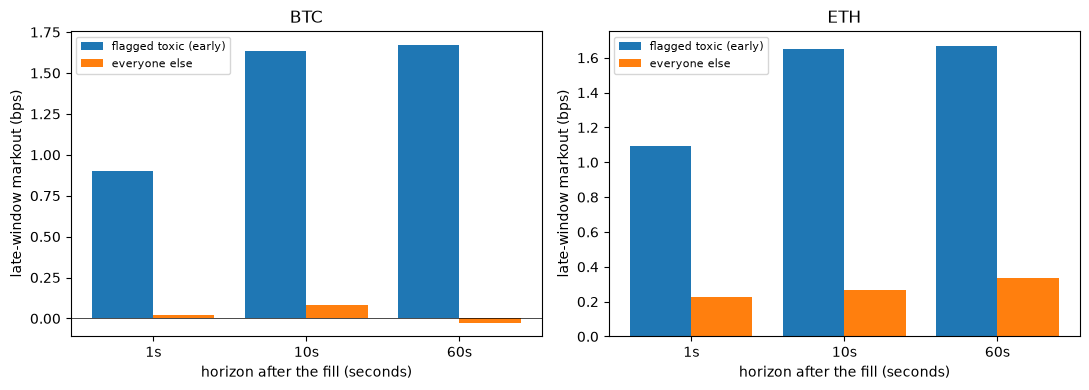

In [24]:
import matplotlib.pyplot as plt
def early_toxic_set(c, K=50, top_frac=0.10):
    m = (coin == c) & np.isin(day, EARLY_DAYS) & np.isfinite(mo_score)
    ids, inv = np.unique(taker[m], return_inverse=True)
    cost = np.bincount(inv, weights=(mo_score[m] / 1e4) * notional[m], minlength=ids.size)
    cnt = np.bincount(inv, minlength=ids.size)
    elig = ids[cnt >= K]; cost = cost[cnt >= K]; n = max(1, int(len(elig) * top_frac))
    return set(elig[np.argsort(-cost)[:n]].tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (c, name) in zip(axes, COIN.items()):
    tox = early_toxic_set(c); late = (coin == c) & np.isin(day, LATE_DAYS)
    is_tox = np.array([t in tox for t in taker[late]])
    hz = [('1s', mo1), ('10s', mo10), ('60s', mo60)]
    toxic_vals = [np.nanmean(h[late][is_tox]) for _, h in hz]
    rest_vals = [np.nanmean(h[late][~is_tox]) for _, h in hz]
    xx = np.arange(3)
    ax.bar(xx - 0.2, toxic_vals, 0.4, label='flagged toxic (early)')
    ax.bar(xx + 0.2, rest_vals, 0.4, label='everyone else')
    ax.set_xticks(xx); ax.set_xticklabels([n for n, _ in hz])
    ax.set_xlabel('horizon after the fill (seconds)')
    ax.set_ylabel('late-window markout (bps)'); ax.set_title(name)
    ax.axhline(0, color='k', lw=0.5); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('fig_oos_toxic_decile.png', dpi=110); plt.show()

## Verification summary

In [25]:
n_pass = sum(1 for *_, ok in CHECKS if ok)
print(f"{'CHECK':52s} {'recomputed':>12s} {'paper':>12s}  status"); print('-' * 84)
for what, got, want, ok in CHECKS:
    print(f"{what:52s} {got:12.4f} {want:12.4f}  {'PASS' if ok else 'FAIL'}")
print('-' * 84); print(f'{n_pass}/{len(CHECKS)} checks reproduce the reported numbers')
# Three numbers rather than one. A difference filed against a declared outside cause is
# neither a match nor a failure, and folding it into either would say something untrue:
# into the first that the number reproduced, into the second that the work is broken. Each
# one is named again below with both values and the cause it is filed under.
n_fail = len(CHECKS) - n_pass
print(f'{n_pass} matched, {len(DIVERGED)} differed for a stated outside reason, {n_fail} failed')
for what, got, want, why in DIVERGED:
    print(f'  DIFFERED  {what:52s} recomputed={got:+.6f}  paper={want:+.6f}')
    print(f'            {why}')
assert n_fail == 0, 'some checks did not reproduce'

CHECK                                                  recomputed        paper  status
------------------------------------------------------------------------------------
collapsed taker trades in the window                 2480267.0000 2480267.0000  PASS
distinct counterparties in the window                  45849.0000   45849.0000  PASS
book-mid markout at 1s (bps)                               1.8779       1.8779  PASS
book-mid markout at 10s (bps)                              2.2388       2.2388  PASS
book-mid markout at 60s (bps)                              2.3150       2.3150  PASS
trade-print markout at 10s (bps)                           0.5208       0.5208  PASS
BTC (>= 50 fills): the ranking carries to the late half, book-mid       0.8414       0.8414  PASS
BTC (>= 100 fills): the ranking carries to the late half, book-mid       0.9207       0.9207  PASS
ETH (>= 50 fills): the ranking carries to the late half, book-mid       0.7987       0.7987  PASS
ETH (>= 100 fills): the

## The rest of the reported figures, and where they are checked

Everything above rebuilds the main line of the argument from the published fills: what the flow costs, whether the cost stays with a counterparty from one week to the next, how much of it the visible order book already explains, how much a screen on past behaviour avoids, how concentrated it is, and what a passive maker is left holding. Each of those is recomputed here and compared against the reported value.

The report carries further figures that this notebook does not rebuild. Each of them comes out of one committed script in the repository, and each of those scripts writes a results file that records its own inputs, its settings and its run.

There are three reasons, and the table keeps them apart. Some figures need a market the published slice does not carry, a second venue on one side and a third contract on the other. Some are not measurements at all but settings declared before a run, and those are checked by reading the declaration. The rest are within reach of the published data and are left out only because the code for them is not in this file.

The table prints no values. A number shown without being recomputed, inside a notebook whose whole job is recomputation, would read as checked when it is not. Each row gives instead the place inside that script's results file where the value sits, so a reader who wants it opens the file and lands on it.

| What it shows | Computed by | Why it is not rebuilt here | Value at |
|---|---|---|---|
| **How far does the centralised venue lead this one in price?** The answer says how much of the measured informedness is fast reaction to an already public price rather than private information. | `probe_E_leadlag.py`, Bitcoin, this venue's mid against the other venue's trades, best lag in seconds. | Needs a second venue. The probe reads Binance trades and depth from their own archives, and it also needs a trade-print series of this venue that no script here writes. Neither has a stand-in in the published slice. | `by_coin.BTC.pairs.HLmid_vs_BNtrade.hayashi_yoshida.best_lag_s` |
| **Does declining the worst-ranked counterparties still pay when the ranking is refitted every day and scored on the day after?** | `t1_toxicity_skew_backtest.py`, both contracts pooled, book mid, median cost reduction in per cent over the walk-forward folds. | The data is here, the code is not. The walk-forward reads the counterparty code, the day, the notional and the book-mid markout at the scoring window, and all four are rebuilt at the top of this notebook. The refit over an expanding window is what this file does not carry. | `pooled.by_measure.mid.t2_walk_forward.median_cost_reduction_pct` |
| **What extra half-spread does each quoter charge on average?** Two quoters cannot be compared until this is held equal between them. | `mm_bakeoff.py`, fill floor of fifty, the counterparty-resolved arm, both contracts pooled, in basis points, and the same value is recorded under each of the nine arms. | The data is here, the code is not. The bake-off reads the counterparty code, the contract, the day, the trade price, the notional, the aggressor side, the pre-trade inventory, the queue imbalance and the half-spread at the fill, together with the markout ladder on both reference prices, and every one of those is shipped or rebuilt above. Running nine quoters over the whole window is the part this file does not carry. | `quoters.K50.as_toxicity.extra_half_spread_summary.by_coin.pooled.mean_extra_half_spread_bps` |
| **The seed and the number of bootstrap draws that run was given.** | `mm_bakeoff.py`, in the run's own header, with the draw count recorded beside it. | Not a computed value, so nothing is missing. Both are fixed in the settings module and written into the run header, and a constant is checked by reading where it is declared. | `_meta.seed` |
| **The risk-aversion coefficient the inventory quotes are solved at.** | `mm_bakeoff.py`, in the run's own header. | Not a computed value either, and for the same reason. It is declared in the quoter module, carried into the run unchanged, and recorded at that address. | `_meta.gamma_anchor` |
| **What the counterparty surcharge takes off the passive maker's adverse-selection cost, at each tier of the exchange fee schedule.** | `maker_econ.py`, the idealised decline policy at a fill floor of fifty and a ten-second window, change in basis points on the book mid. | The data is here, the code is not. The walk across the six fee tiers is not written in this file. The baseline this change is read against is not out of reach: it is the symmetric quoter's own net cost, which the quoter table of section 8 shows at the base fee. Those costs are displayed rather than rebuilt, each tied to the same quoter's cost at the zero-fee tier through the fee the venue publishes. The rebuild from the tape that this notebook does carry stands in section 6, at sixty seconds rather than ten, and is a different number. | `b1_idealized_policy_upper_bound.K50.h10.delta_net_vw_bps.net_MID_lower` |
| **How much does the past-cost gain on Ethereum move from one split of the data to another?** It is reported as a median with its range rather than as one draw. | `i3_book_comparator.py`, Ethereum at a fill floor of fifty and a ten-second window, median over forty draws. | The data is here, the code is not. The order-book predictors are already built above: eight of the ten travel in the published slice under their own names, and the other two are the same numbers under other names, rebuilt here exactly. The sweep over forty splits is what is missing, and this notebook scores one. | `seed_robustness.cells[4].median` |
| **The same gain differenced within each draw between the two contracts**, which is how the contrast between them is stated without treating the two as independent. | `i3_book_comparator.py`, Ethereum minus Bitcoin at a fill floor of fifty: the median, then the two ends of its interval. | The same reason, and the paired difference is taken over the same forty draws. | `seed_robustness.paired_eth_minus_btc.50.median`, `seed_robustness.paired_eth_minus_btc.50.pctile_2_5`, `seed_robustness.paired_eth_minus_btc.50.pctile_97_5` |
| **Does the counterparty ranking still repeat on a third and thinner market?** That is what keeps the result from being a property of the two largest markets alone. | `three_coin_persistence.py`, solana on the book mid at ten seconds, wallets with at least fifty fills in each half, correlation after correcting for measurement noise. | Needs a market the published slice does not carry. The published fills hold two contracts, and this run scores one outside them. Its readings on the two published contracts are rebuilt above; the third is what the run exists for. | `cells[28].disatt` |
| **How many counterparties the requirement of activity in both halves removes**, at the four decision points other than the one the opening figure is taken at. | `survivorship_census.py`, the four sites. | The data is here, the code is not. The census reads the counterparty code, the contract, the day, the notional, the realised profit and the book-mid markout at the scoring window, all of them above, and it reproduces five published anchors before it reports anything. The site the opening figure is taken at is rebuilt above; each of the other four needs its own producer's admission rule replayed, and this file carries none of the four. | `totals.loss_by_site.ws1_horizon_persistence.never_returned`, `totals.loss_by_site.ws2_hard_classifier.returned_below_floor`, `totals.loss_by_site.ws3_taker_pnl.never_returned`, `totals.loss_by_site.build_toxicity_frame.never_returned` |

## What we found, and why it matters
The cost of trading against this flow is real and mostly hidden: about 2 bps on the book mid, roughly four times what the trade price alone shows. It sticks to the wallet, since the same counterparties stay toxic from one week to the next, which is what lets a maker act on it at all. The public order book does not replace knowing who you traded with, because most of the toxicity spread survives the book control and on Ethereum the wallet's own past cost is almost the only signal, which is the whole reason to resolve the counterparty. The cost is also concentrated, since a small group carries most of it and the worst ten percent on past data hold 76.4 percent of the positive later cost, which says where the cost sits and not what a rule would save. The honest bottom line is that this is a cost to defend against rather than free money: a passive maker still loses at every real fee tier, so the value is in avoiding cost, and knowing the counterparty is what makes that possible.

What the checks recompute live here matches the reported numbers, rebuilt from the raw fills and the order-book series. The summary cell above prints how many comparisons were made and how many reproduced, so those counts stand there and are not repeated here. Two sections still show their figures from the committed run rather than rebuilding them, the quoter table and the one that follows the informed flow, because both need the whole late window replayed. The rest of what is not rebuilt is listed in the table above, with the script that produces each figure and the address the value sits at.